# Archived measured results and the interrupted FP32 attempt

**DOCX pages: 7–9; full comparison. Hardware: CPU.**

Recompute all count-derived metrics from the 83 archived comparison records, plot their confusion matrices, and display the supplied Kaggle environments/probes and the incomplete Mac FP32 attempt. No model is trained.

Upload this single `.ipynb` into a fresh Kaggle notebook, enable Internet, and Run All. GPU notebooks use one visible GPU; T4 ×2 is compatible. No dataset upload, previous notebook output, personal repository, Hugging Face token or AI API key is required. Training code and fixed input revisions are embedded below. Each file writes into its own folder under `/kaggle/working/Project/teacher_runs`.

**Historical finding:** This is an evidence replay. AP/AUC/Brier values without imported Kaggle per-post predictions remain transcribed log values. A memory-pressure failure on a Mac cannot be promised to recur on a different Kaggle GPU. Fresh training is provided by the other notebooks.

Fresh results are generated by this execution. Historical values quoted in explanations are references, not substitutes for the new outputs. Hardware, Python and library versions can change numerical results. The real historical test sets were inspected during development, so this reproduces the reported exploratory protocol, not fresh external validation. Ten epochs has not been tested in the joint pipeline and is not silently added here.


In [1]:
import os,sys,json,subprocess,importlib.util
from pathlib import Path
from IPython.display import display,Image,Markdown
SLUG='10_archived_logs_and_interrupted_attempt'
PROFILE='archive'
MODEL_KEYS=[]
NEURAL=False
GPU_REQUIRED=False
IS_KAGGLE=Path('/kaggle/working').exists()
VALIDATION_REUSE=os.environ.get('FORUM_TEACHER_VALIDATE','0')=='1'
default_root=(Path('/kaggle/working/Project/teacher_runs') if IS_KAGGLE else Path.cwd()/'Project/teacher_runs')/SLUG
PROJECT=Path(os.environ.get('FORUM_TEACHER_RUN_DIR',str(default_root))).resolve()
if VALIDATION_REUSE:
    saved_root=Path(os.environ['FORUM_TEACHER_SAVED_PROJECT']).resolve()
    assert PROJECT.is_relative_to(saved_root) and PROJECT!=saved_root
for name in ['scripts','models','reports/teacher','reports/figures','reports/experiments','.cache/tmp']:(PROJECT/name).mkdir(parents=True,exist_ok=True)
os.environ.update(PROJECT_ROOT=str(PROJECT),HF_HOME=str(PROJECT/'.cache/huggingface'),HF_HUB_CACHE=str(PROJECT/'.cache/huggingface/hub'),
    HF_XET_CACHE=str(PROJECT/'.cache/huggingface/xet'),HF_HUB_DISABLE_XET='1',HF_HUB_DISABLE_TELEMETRY='1',
    MPLCONFIGDIR=str(PROJECT/'.cache/matplotlib'),TMPDIR=str(PROJECT/'.cache/tmp'),PIP_CACHE_DIR=str(PROJECT/'.cache/pip'),
    OMP_NUM_THREADS='1',OPENBLAS_NUM_THREADS='1',MKL_NUM_THREADS='1',TOKENIZERS_PARALLELISM='false',PYTORCH_ENABLE_MPS_FALLBACK='1')
RUN_TRAINING=not VALIDATION_REUSE and PROFILE not in ['data','archive']
print('Project:',PROJECT)
print('Mode:','LOCAL QA: saved completed training; no fitting' if VALIDATION_REUSE else ('FRESH TRAINING' if RUN_TRAINING else 'DATA AUDIT / HISTORICAL EVIDENCE; NO TRAINING'))


Project: /Users/nhaterik/lastyear/machine/Project/.cache/teacher-notebooks-validation/10_archived_logs_and_interrupted_attempt
Mode: LOCAL QA: saved completed training; no fitting


## Dependencies and recorded environment

Unlike the older presence-only dependency check, this cell checks installed versions against the requested requirements. Existing PyTorch is kept when compatible. Installation occurs only in the Kaggle notebook environment; local QA never installs packages. Start in a fresh kernel. If a changed package was already imported and this cell requests a restart, restart once and Run All.


In [2]:
from importlib.metadata import version,PackageNotFoundError
try:
    from packaging.requirements import Requirement
except ImportError:
    if not IS_KAGGLE:raise RuntimeError('Use the existing Project/.venv; local package installation is not performed.')
    subprocess.run([sys.executable,'-m','pip','install','packaging>=24'],check=True)
    from packaging.requirements import Requirement
REQUIREMENTS=['numpy>=2,<3', 'scikit-learn==1.9.1', 'matplotlib>=3.10,<4', 'joblib>=1.4,<2', 'packaging>=24']
changes=[];loaded_changes=[]
module_names={'scikit-learn':'sklearn','sentence-transformers':'sentence_transformers','protobuf':'google.protobuf'}
for text in REQUIREMENTS:
    requirement=Requirement(text)
    try:installed=version(requirement.name)
    except PackageNotFoundError:installed=None
    if installed is None or installed not in requirement.specifier:
        changes.append(text)
        if module_names.get(requirement.name,requirement.name.replace('-','_')) in sys.modules:loaded_changes.append(requirement.name)
if changes:
    if VALIDATION_REUSE or not IS_KAGGLE:raise RuntimeError('Use the existing Project/.venv with compatible packages; no local installation: '+str(changes))
    subprocess.run([sys.executable,'-m','pip','install',*changes],check=True)
    if loaded_changes:raise RuntimeError('Packages changed after import. Restart the kernel once, then Run All: '+str(loaded_changes))
for text in REQUIREMENTS:
    requirement=Requirement(text)
    assert version(requirement.name) in requirement.specifier,(requirement.name,version(requirement.name),str(requirement.specifier))
DEVICE='cpu';USE_BF16=False
if NEURAL:
    import torch
    DEVICE='cuda' if torch.cuda.is_available() else ('mps' if torch.backends.mps.is_available() else 'cpu')
    USE_BF16=DEVICE=='mps' or (DEVICE=='cuda' and torch.cuda.is_bf16_supported(including_emulation=False))
if RUN_TRAINING and IS_KAGGLE and GPU_REQUIRED and DEVICE!='cuda':raise RuntimeError('Enable a Kaggle GPU before training this notebook.')
environment={'python':sys.version,'requirements':REQUIREMENTS,'versions':{Requirement(text).name:version(Requirement(text).name) for text in REQUIREMENTS},
    'device':DEVICE,'visible_gpus':torch.cuda.device_count() if NEURAL else 0,'training_gpu_count':1 if RUN_TRAINING and DEVICE=='cuda' else 0,
    'validation_reuse':VALIDATION_REUSE,'fresh_training_requested':RUN_TRAINING}
(PROJECT/'reports/teacher/environment.json').write_text(json.dumps(environment,indent=2)+'\n')
print(json.dumps(environment,indent=2))


{
  "python": "3.12.13 (main, Mar  3 2026, 12:39:30) [Clang 21.0.0 (clang-2100.0.123.102)]",
  "requirements": [
    "numpy>=2,<3",
    "scikit-learn==1.9.1",
    "matplotlib>=3.10,<4",
    "joblib>=1.4,<2",
    "packaging>=24"
  ],
  "versions": {
    "numpy": "2.5.4",
    "scikit-learn": "1.9.1",
    "matplotlib": "3.11.2",
    "joblib": "1.6.0",
    "packaging": "26.3"
  },
  "device": "cpu",
  "visible_gpus": 0,
  "training_gpu_count": 0,
  "validation_reuse": true,
  "fresh_training_requested": false
}


## Embedded source files

Each module below is written into this experiment folder. Defaults and algorithm parameters match the completed project protocol; the baseline CLI merely selects the requested existing method.


In [3]:
SOURCES={}


### teacher_notebook_tools.py


In [4]:
SOURCES['teacher_notebook_tools.py']=r'''"""Shared data checks, saved-run validation, statistics and figures for teacher notebooks.

Every training notebook embeds this file. Saved-run QA is explicitly separate
from fresh training and never writes through links to the original model files.
"""
import argparse,csv,hashlib,json,os,shutil,textwrap
from collections import defaultdict
from pathlib import Path
import numpy as np
from sklearn.metrics import average_precision_score,roc_auc_score,precision_recall_curve

ROOT=Path(__file__).resolve().parents[1]
OUT=ROOT/'reports/teacher'


def read_json(path):return json.loads(Path(path).read_text())
def write_json(path,value):
    path=Path(path);path.parent.mkdir(parents=True,exist_ok=True)
    path.write_text(json.dumps(value,indent=2,ensure_ascii=False)+'\n')
def read_csv(path):
    with Path(path).open(encoding='utf-8-sig',newline='') as handle:return list(csv.DictReader(handle))


def copy_tree_for_qa(source,target):
    source,target=Path(source),Path(target)
    if not source.exists():raise FileNotFoundError(source)
    for path in source.rglob('*'):
        if not path.is_file():continue
        destination=target/path.relative_to(source);destination.parent.mkdir(parents=True,exist_ok=True)
        if destination.is_symlink():destination.unlink()
        if path.suffix in {'.safetensors','.bin','.pt','.joblib'}:
            if destination.exists():destination.unlink()
            destination.symlink_to(path.resolve())
        else:shutil.copy2(path,destination)


def hydrate_qa(profile,model_keys):
    """Populate only the saved evidence required by this notebook, without training."""
    if os.environ.get('FORUM_TEACHER_VALIDATE')!='1':return
    saved=Path(os.environ['FORUM_TEACHER_SAVED_PROJECT']).resolve()
    assert saved!=ROOT and saved.is_dir()
    for folder in ['scripts','models','reports/figures','reports/experiments','data/raw','.cache/tmp']:
        (ROOT/folder).mkdir(parents=True,exist_ok=True)
    cache=ROOT/'.cache/huggingface'
    if not cache.exists():cache.symlink_to(saved/'.cache/huggingface',target_is_directory=True)
    for name,filename in [('UPenn','All_Courses_REDACTED_CODED.csv'),('Stanford','Stanford.csv')]:
        target=ROOT/'data/raw'/filename
        if not target.exists():shutil.copy2(saved/'Datasets'/name/'raw.csv',target)
    split=saved/'reports/experiments/split_ids.csv'
    shutil.copy2(split,ROOT/'reports/experiments/split_ids.csv')
    families=[];models=[]
    if profile=='baseline':
        families=['experiments']
        models=[f'{source}__{key}.joblib' for source in ['upenn','stanford'] for key in model_keys]
    elif profile in ['source_minilm','blend']:
        families=['fine_tuning']
        models=[f'urgency_minilm_{source}' for source in ['upenn','stanford']]
        if profile=='blend':
            families+=['experiments','ensembles']
            models += [f'{source}__tfidf_logreg.joblib' for source in ['upenn','stanford']]
            models += [f'urgency_hybrid_{source}' for source in ['upenn','stanford']]
    elif profile=='deberta':
        families=['reliability/deberta_real_only'];models=['urgency_deberta_real_only']
    elif profile in ['joint_real','joint_custom']:
        families=['final_minilm_trial']
        models=[p.name for p in (saved/'models').glob('urgency_final_minilm_*')
                if profile=='joint_custom' or p.name.startswith('urgency_final_minilm_real_only_')]
    for family in families:copy_tree_for_qa(saved/'reports'/family,ROOT/'reports'/family)
    for name in models:
        source=saved/'models'/name;target=ROOT/'models'/name
        if source.is_dir():copy_tree_for_qa(source,target)
        else:
            if target.exists() or target.is_symlink():target.unlink()
            target.symlink_to(source.resolve())
    if profile=='baseline':
        for filename in ['results.json','cv_results.json']:
            path=ROOT/'reports/experiments'/filename
            write_json(path,[r for r in read_json(path) if r['model'] in model_keys])
    write_json(OUT/'validation_origin.json',{
        'mode':'LOCAL VALIDATION USING COMPLETED TRAINING; no fitting performed',
        'saved_project':str(saved),'profile':profile,'model_keys':model_keys})


def check_data():
    audit=read_json(ROOT/'reports/data_audit.json')
    assert all(audit['checks'].values())
    plan=read_csv(ROOT/'reports/reliability/split_plan.csv')
    historical={r['post_id']:r for r in read_csv(ROOT/'reports/experiments/split_ids.csv')}
    assert len(plan)==len({r['post_id'] for r in plan})==32563
    assert all((r['role']=='test')==(historical[r['post_id']]['split']=='test') for r in plan)
    students=defaultdict(set)
    for row in plan:
        if row['source']=='upenn':students[row['group_id']].add(row['role'])
    assert all(len(roles)==1 for roles in students.values())
    groups=defaultdict(set)
    for row in read_csv(ROOT/'Datasets/CustomForum/draft_examples.csv'):groups[row['scenario_group']].add(row['split'])
    assert all(len(roles)==1 for roles in groups.values())
    result={'passed':True,'hashes_and_cleaning_checks':audit['checks'],
        'historical_test_membership_preserved':True,'upenn_student_roles_disjoint':True,
        'custom_scenario_groups_disjoint':True,'rows':len(plan),
        'split_plan_sha256':hashlib.sha256((ROOT/'reports/reliability/split_plan.csv').read_bytes()).hexdigest()}
    write_json(OUT/'data_checks.json',result)
    return result


def count_metrics(matrix):
    (tn,fp),(fn,tp)=matrix
    ratio=lambda a,b:a/b if b else 0.
    f1=ratio(2*tp,2*tp+fp+fn)
    return {'precision':ratio(tp,tp+fp),'recall':ratio(tp,tp+fn),'f1':f1,
        'accuracy':ratio(tn+tp,tn+fp+fn+tp),
        'macro_f1':(f1+ratio(2*tn,2*tn+fp+fn))/2}


def result_rows(profile,model_keys):
    if profile=='baseline':return [r for r in read_json(ROOT/'reports/experiments/results.json') if r['model'] in model_keys]
    if profile=='source_minilm':
        selected=[r for source in ['upenn','stanford'] for r in read_json(ROOT/f'reports/fine_tuning/{source}/test_results.json')]
        write_json(ROOT/'reports/fine_tuning/results.json',selected)
        return [record for r in selected for record in [dict(r,policy='selected threshold'),
            dict(r['default_threshold_metrics'],train_source=r['train_source'],test_source=r['test_source'],model=r['model'],threshold=.5,policy='fixed 0.5 diagnostic')]]
    if profile=='blend':return read_json(ROOT/'reports/ensembles/results.json')
    if profile=='deberta':
        rows=read_json(ROOT/'reports/reliability/deberta_real_only/results.json')
        rows += [dict(r,model='joint_deberta',train_source='upenn+stanford',test_source=r['source'],policy='fixed 0.5 diagnostic')
                 for r in read_json(ROOT/'reports/reliability/deberta_real_only/fixed_threshold_diagnostic.json')]
        return rows
    if profile in ['joint_real','joint_custom']:
        filename='control_results.json' if profile=='joint_real' else 'results.json'
        return [dict(r,model='joint_minilm_'+r['arm'],train_source='joint') for r in read_json(ROOT/'reports/final_minilm_trial'/filename)]
    if profile=='archive':return read_json(ROOT/'reports/teacher/archived_comparison.json')
    return []


def prediction_rows(record,profile):
    source=record.get('test_source');train=record.get('train_source')
    if profile=='baseline':path=ROOT/f'reports/experiments/predictions_{train}_{source}_{record["model"]}.csv'
    elif profile=='source_minilm':path=ROOT/f'reports/fine_tuning/{train}/predictions_{source}.csv'
    elif profile=='blend':path=ROOT/f'reports/ensembles/{train}/predictions_{source}.csv'
    elif profile=='deberta':
        policy=record['policy'] if record['policy'] in ['upenn','stanford','mixed'] else 'mixed'
        path=ROOT/f'reports/reliability/deberta_real_only/predictions_{source}_{policy}.csv'
    elif profile in ['joint_real','joint_custom']:
        directory=ROOT/'reports/final_minilm_trial'/record['run']
        path=directory/('custom_all_predictions.csv' if source=='custom_challenge' else f'predictions_{source}.csv')
    else:return []
    rows=read_csv(path)
    if source=='custom_challenge':
        rows=[dict(r,label=r['draft_priority']) for r in rows if r['split']=='challenge' and r['draft_priority'] in ['0','1']]
    return rows


def label(row):
    method=row.get('trial_label',row.get('run',row.get('model','method')))
    policy=row.get('policy','')
    return f"{method} {row.get('train_source','joint')} → {row['test_source']}"+(f' / {policy}' if policy else '')


def verify_results(rows,profile):
    errors=[];checked=[];curves=[]
    for row in rows:
        calculated=count_metrics(row['confusion_matrix'])
        for key,value in calculated.items():
            if row.get(key) is not None:assert abs(float(row[key])-value)<1e-10,(label(row),key,row[key],value)
        predicted_rows=prediction_rows(row,profile)
        if predicted_rows:
            y=np.array([int(r['label']) for r in predicted_rows]);p=np.array([float(r['score']) for r in predicted_rows])
            threshold=float(row.get('threshold',.5));pred=p>=threshold
            matrix=[[int(((y==0)&(~pred)).sum()),int(((y==0)&pred).sum())],
                    [int(((y==1)&(~pred)).sum()),int(((y==1)&pred).sum())]]
            assert matrix==row['confusion_matrix'],label(row)
            for key,value in [('average_precision',average_precision_score(y,p)),('roc_auc',roc_auc_score(y,p))]:
                if row.get(key) is not None:assert abs(float(row[key])-float(value))<1e-8,(label(row),key)
            wrong=[]
            for item,true,score,guess in zip(predicted_rows,y,p,pred):
                if int(true)!=int(guess):wrong.append({'post_id':item['post_id'],'true':int(true),'predicted':int(guess),
                    'score':float(score),'threshold':threshold,'error':'FN' if true else 'FP','text':item.get('text','')})
            errors.append({'experiment':label(row),'all_error_count':len(wrong),
                'examples':sorted(wrong,key=lambda r:abs(r['score']-threshold),reverse=True)[:4]})
            curves.append((label(row),y,p,threshold))
        checked.append({'experiment':label(row),'count_metrics_match':True,
                        'per_post_predictions_checked':bool(predicted_rows)})
    write_json(OUT/'checks.json',checked);write_json(OUT/'error_examples.json',errors)
    return curves


def make_figures(rows,curves,profile):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    figures=[]
    def save(fig,name):
        path=OUT/(name+'.png');fig.tight_layout();fig.savefig(path,dpi=145,bbox_inches='tight');plt.close(fig);figures.append(str(path.relative_to(ROOT)))
    if not rows:
        audit=read_json(ROOT/'reports/data_audit.json');fig,ax=plt.subplots(figsize=(7,3.7))
        sources=list(audit['datasets']);x=np.arange(len(sources));width=.35
        for i,(key,title) in enumerate([('0','Not urgent'),('1','Urgent')]):
            ax.bar(x+(i-.5)*width,[audit['datasets'][s]['label_counts'][key] for s in sources],width,label=title)
        ax.set(xticks=x,xticklabels=sources,ylabel='Clean posts',title='Actual prepared dataset counts');ax.legend();save(fig,'dataset_labels')
    for start in range(0,len(rows),8):
        chunk=rows[start:start+8];x=np.arange(len(chunk));width=.25
        fig,ax=plt.subplots(figsize=(max(8,len(chunk)*1.35),4.8))
        for i,key in enumerate(['precision','recall','f1']):ax.bar(x+(i-1)*width,[row[key] for row in chunk],width,label=key)
        ax.set(ylim=(0,1),xticks=x,xticklabels=[textwrap.fill(label(row),24) for row in chunk],title='All-post binary metrics; review rows remain included')
        ax.tick_params(axis='x',labelsize=7);ax.legend();save(fig,f'metrics_{start//8+1:02d}')
        fig,axes=plt.subplots((len(chunk)+1)//2,2,figsize=(8,3.2*((len(chunk)+1)//2)),squeeze=False)
        for ax,row in zip(axes.flat,chunk):
            matrix=np.array(row['confusion_matrix']);ax.imshow(matrix,cmap='Blues')
            for a in range(2):
                for b in range(2):ax.text(b,a,str(matrix[a,b]),ha='center',va='center',color='white' if matrix[a,b]>matrix.max()*.5 else 'black')
            ax.set(title=textwrap.fill(label(row),42),xlabel='Predicted',ylabel='True',xticks=[0,1],yticks=[0,1],xticklabels=['Normal','Urgent'],yticklabels=['Normal','Urgent'])
            ax.title.set_fontsize(8)
        for ax in list(axes.flat)[len(chunk):]:ax.axis('off')
        save(fig,f'confusions_{start//8+1:02d}')
    for start in range(0,len(curves),8):
        fig,axes=plt.subplots(1,2,figsize=(11,4))
        for title,y,p,t in curves[start:start+8]:
            precision,recall,thresholds=precision_recall_curve(y,p)
            axes[0].plot(recall,precision,label=title)
            f1=2*precision[:-1]*recall[:-1]/np.maximum(precision[:-1]+recall[:-1],1e-12)
            axes[1].plot(thresholds,f1,label=title)
        axes[0].set(xlabel='Recall',ylabel='Precision',title='Precision–recall curves',xlim=(0,1),ylim=(0,1))
        axes[1].set(xlabel='Decision threshold',ylabel='F1',title='Test threshold diagnostic only; no selection',ylim=(0,1))
        axes[0].legend(fontsize=6);save(fig,f'precision_recall_threshold_{start//8+1:02d}')
    histories=[]
    if profile=='source_minilm':
        for source in ['upenn','stanford']:
            for run in read_json(ROOT/f'reports/fine_tuning/{source}/selection.json')['scout_runs']:
                histories.append((source+'/'+run['name'],run['history'],'val_ap'))
    elif profile=='deberta':histories=[('deberta',read_json(ROOT/'reports/reliability/deberta_real_only/history.json'),'mean_validation_ap')]
    elif profile in ['joint_real','joint_custom']:
        for run in dict.fromkeys(row['run'] for row in rows):
            histories.append((run,read_json(ROOT/'reports/final_minilm_trial'/run/'history.json'),'mean_real_validation_ap'))
    if histories:
        fig,axes=plt.subplots(1,2,figsize=(10,4))
        for title,history,metric in histories:
            axes[0].plot([r['epoch'] for r in history],[r['train_loss'] for r in history],'o-',label=title)
            if all(metric in r for r in history):axes[1].plot([r['epoch'] for r in history],[r[metric] for r in history],'o-',label=title)
        axes[0].set(xlabel='Epoch',ylabel='Training loss');axes[1].set(xlabel='Epoch',ylabel='Validation AP',ylim=(0,1));axes[0].legend(fontsize=6);save(fig,'learning_curves')
    write_json(OUT/'figure_files.json',figures)
    return figures


def emit(profile,model_keys):
    OUT.mkdir(parents=True,exist_ok=True);rows=result_rows(profile,model_keys)
    curves=verify_results(rows,profile);figures=make_figures(rows,curves,profile)
    write_json(OUT/'results.json',rows)
    fields=['environment','run','train_source','test_source','model','policy','seed','threshold','precision','recall','f1','macro_f1','accuracy','average_precision','roc_auc','brier_score','precision_at_20','recall_at_20','automatic_coverage','review_count','confusion_matrix']
    with (OUT/'results.csv').open('w',encoding='utf-8-sig',newline='') as handle:
        writer=csv.DictWriter(handle,fieldnames=fields,extrasaction='ignore');writer.writeheader()
        for row in rows:writer.writerow(row)
    print(json.dumps({'profile':profile,'rows':len(rows),'figures':figures,
        'mode':'SAVED-TRAINING VALIDATION' if os.environ.get('FORUM_TEACHER_VALIDATE')=='1' else ('HISTORICAL LOG REPLAY; NO TRAINING' if profile=='archive' else 'FRESH EXPERIMENT'),
        'checks':'All reported count metrics recomputed; per-post scores checked when available.'},indent=2))


def main():
    parser=argparse.ArgumentParser(description=__doc__);parser.add_argument('action',choices=['hydrate','check-data','emit'])
    parser.add_argument('--profile',default='data');parser.add_argument('--models',nargs='*',default=[])
    args=parser.parse_args()
    if args.action=='hydrate':hydrate_qa(args.profile,args.models)
    elif args.action=='check-data':print(json.dumps(check_data(),indent=2))
    else:emit(args.profile,args.models)


if __name__=='__main__':main()
'''
(PROJECT/"scripts"/'teacher_notebook_tools.py').write_text(SOURCES['teacher_notebook_tools.py'],encoding="utf-8")


16111

In [5]:
import hashlib
def run(name,*args):subprocess.run([sys.executable,str(PROJECT/'scripts'/name),*map(str,args)],cwd=PROJECT,env=os.environ.copy(),check=True)
def read_json(relative):return json.loads((PROJECT/relative).read_text())
print(json.dumps({name:hashlib.sha256(source.encode()).hexdigest() for name,source in SOURCES.items()},indent=2))
if VALIDATION_REUSE:run('teacher_notebook_tools.py','hydrate','--profile',PROFILE,'--models',*MODEL_KEYS)


{
  "teacher_notebook_tools.py": "c1f9bacc5808ed2267a2aee5028d9bbd51a98357dbca6007c5962f68e6c1a603"
}


## Archived evidence and its limits

These are explicitly embedded measured records from the DOCX, not fresh training. P/R/F1/Accuracy are recomputed from every confusion matrix. Kaggle AP/AUC/Brier values are transcribed log statistics when per-post Kaggle files are unavailable. The FP32 record was stopped before validation and has no test score or exported classifier; the three-step timing benchmarks discarded their weights. Their timings and memory failure depend on the original hardware.


In [6]:
ARCHIVED={'reports/all_trials_comparison.json': [{'environment': 'Mac / original', 'trial_label': 'TF-IDF + LR', 'accuracy': 0.9204052098408104, 'average_precision': 0.6595937758457739, 'confusion_matrix': [[605, 25], [30, 31]], 'default_threshold_metrics': {'accuracy': 0.9319826338639653, 'average_precision': 0.6595937758457739, 'confusion_matrix': [[616, 14], [33, 28]], 'f1': 0.5436893203883495, 'macro_f1': 0.7534709307180215, 'positive_count': 61, 'precision': 0.6666666666666666, 'precision_at_20': 0.95, 'recall': 0.45901639344262296, 'recall_at_20': 0.3114754098360656, 'roc_auc': 0.9043195420244601, 'test_size': 691, 'top20_found': 19}, 'f1': 0.5299145299145299, 'inference_seconds': 0.030501333065330982, 'macro_f1': 0.7432181345224824, 'model': 'tfidf_logreg', 'positive_count': 61, 'precision': 0.5535714285714286, 'precision_at_20': 0.95, 'recall': 0.5081967213114754, 'recall_at_20': 0.3114754098360656, 'roc_auc': 0.9043195420244601, 'test_size': 691, 'test_source': 'upenn', 'threshold': 0.4225475624901568, 'top20_found': 19, 'train_source': 'upenn', 'training_seconds': 2.5021156668663025}, {'environment': 'Mac / original', 'trial_label': 'TF-IDF + LR', 'accuracy': 0.8348813209494325, 'average_precision': 0.5323111973045145, 'confusion_matrix': [[4517, 192], [768, 337]], 'default_threshold_metrics': {'accuracy': 0.8314413484692122, 'average_precision': 0.5323111973045145, 'confusion_matrix': [[4599, 110], [870, 235]], 'f1': 0.32413793103448274, 'macro_f1': 0.6139259118721245, 'positive_count': 1105, 'precision': 0.6811594202898551, 'precision_at_20': 0.7, 'recall': 0.21266968325791855, 'recall_at_20': 0.012669683257918552, 'roc_auc': 0.8202325574691383, 'test_size': 5814, 'top20_found': 14}, 'f1': 0.412484700122399, 'inference_seconds': 0.1567400828935206, 'macro_f1': 0.6582135327708253, 'model': 'tfidf_logreg', 'positive_count': 1105, 'precision': 0.6370510396975425, 'precision_at_20': 0.7, 'recall': 0.3049773755656109, 'recall_at_20': 0.012669683257918552, 'roc_auc': 0.8202325574691383, 'test_size': 5814, 'test_source': 'stanford', 'threshold': 0.4225475624901568, 'top20_found': 14, 'train_source': 'upenn', 'training_seconds': 2.5021156668663025}, {'environment': 'Mac / original', 'trial_label': 'TF-IDF + SVM', 'accuracy': 0.914616497829233, 'average_precision': 0.6557883130313705, 'confusion_matrix': [[598, 32], [27, 34]], 'default_threshold_metrics': {'accuracy': 0.9319826338639653, 'average_precision': 0.6557883130313705, 'confusion_matrix': [[617, 13], [34, 27]], 'f1': 0.5346534653465347, 'macro_f1': 0.7489816897380605, 'positive_count': 61, 'precision': 0.675, 'precision_at_20': 0.95, 'recall': 0.4426229508196721, 'recall_at_20': 0.3114754098360656, 'roc_auc': 0.900416341399948, 'test_size': 691, 'top20_found': 19}, 'f1': 0.5354330708661418, 'inference_seconds': 0.035409582778811455, 'macro_f1': 0.7442105593374533, 'model': 'tfidf_svm', 'positive_count': 61, 'precision': 0.5151515151515151, 'precision_at_20': 0.95, 'recall': 0.5573770491803278, 'recall_at_20': 0.3114754098360656, 'roc_auc': 0.900416341399948, 'test_size': 691, 'test_source': 'upenn', 'threshold': -0.1646198683014054, 'top20_found': 19, 'train_source': 'upenn', 'training_seconds': 3.032327917404473}, {'environment': 'Mac / original', 'trial_label': 'TF-IDF + SVM', 'accuracy': 0.8362573099415205, 'average_precision': 0.5323729667045595, 'confusion_matrix': [[4485, 224], [728, 377]], 'default_threshold_metrics': {'accuracy': 0.8305813553491572, 'average_precision': 0.5323729667045595, 'confusion_matrix': [[4608, 101], [884, 221]], 'f1': 0.3097407147862649, 'macro_f1': 0.6065907769598416, 'positive_count': 1105, 'precision': 0.6863354037267081, 'precision_at_20': 0.75, 'recall': 0.2, 'recall_at_20': 0.013574660633484163, 'roc_auc': 0.8179686726774281, 'test_size': 5814, 'top20_found': 15}, 'f1': 0.44196951934349354, 'inference_seconds': 0.160993583034724, 'macro_f1': 0.6730105609214948, 'model': 'tfidf_svm', 'positive_count': 1105, 'precision': 0.627287853577371, 'precision_at_20': 0.75, 'recall': 0.3411764705882353, 'recall_at_20': 0.013574660633484163, 'roc_auc': 0.8179686726774281, 'test_size': 5814, 'test_source': 'stanford', 'threshold': -0.1646198683014054, 'top20_found': 15, 'train_source': 'upenn', 'training_seconds': 3.032327917404473}, {'environment': 'Mac / original', 'trial_label': 'TF-IDF + NB', 'accuracy': 0.8683068017366136, 'average_precision': 0.45168597377353814, 'confusion_matrix': [[569, 61], [30, 31]], 'default_threshold_metrics': {'accuracy': 0.918958031837916, 'average_precision': 0.45168597377353814, 'confusion_matrix': [[628, 2], [54, 7]], 'f1': 0.2, 'macro_f1': 0.5786585365853658, 'positive_count': 61, 'precision': 0.7777777777777778, 'precision_at_20': 0.75, 'recall': 0.11475409836065574, 'recall_at_20': 0.2459016393442623, 'roc_auc': 0.8421545667447308, 'test_size': 691, 'top20_found': 15}, 'f1': 0.40522875816993464, 'inference_seconds': 0.02948762523010373, 'macro_f1': 0.665592410004414, 'model': 'tfidf_nb', 'positive_count': 61, 'precision': 0.33695652173913043, 'precision_at_20': 0.75, 'recall': 0.5081967213114754, 'recall_at_20': 0.2459016393442623, 'roc_auc': 0.8421545667447308, 'test_size': 691, 'test_source': 'upenn', 'threshold': 0.0479195042686865, 'top20_found': 15, 'train_source': 'upenn', 'training_seconds': 2.6864963746629655}, {'environment': 'Mac / original', 'trial_label': 'TF-IDF + NB', 'accuracy': 0.7865497076023392, 'average_precision': 0.39371463491078784, 'confusion_matrix': [[4170, 539], [702, 403]], 'default_threshold_metrics': {'accuracy': 0.8114895080839353, 'average_precision': 0.39371463491078784, 'confusion_matrix': [[4701, 8], [1088, 17]], 'f1': 0.03008849557522124, 'macro_f1': 0.4628438286601578, 'positive_count': 1105, 'precision': 0.68, 'precision_at_20': 0.8, 'recall': 0.015384615384615385, 'recall_at_20': 0.014479638009049774, 'roc_auc': 0.7253998072430861, 'test_size': 5814, 'top20_found': 16}, 'f1': 0.3937469467513434, 'inference_seconds': 0.14640133315697312, 'macro_f1': 0.6321098787613308, 'model': 'tfidf_nb', 'positive_count': 1105, 'precision': 0.4278131634819533, 'precision_at_20': 0.8, 'recall': 0.36470588235294116, 'recall_at_20': 0.014479638009049774, 'roc_auc': 0.7253998072430861, 'test_size': 5814, 'test_source': 'stanford', 'threshold': 0.0479195042686865, 'top20_found': 16, 'train_source': 'upenn', 'training_seconds': 2.6864963746629655}, {'environment': 'Mac / original', 'trial_label': 'Đa số', 'accuracy': 0.9117221418234442, 'average_precision': 0.08827785817655572, 'confusion_matrix': [[630, 0], [61, 0]], 'default_threshold_metrics': {'accuracy': 0.9117221418234442, 'average_precision': 0.08827785817655572, 'confusion_matrix': [[630, 0], [61, 0]], 'f1': 0.0, 'macro_f1': 0.4769114307342922, 'positive_count': 61, 'precision': 0.0, 'precision_at_20': 0.0, 'recall': 0.0, 'recall_at_20': 0.0, 'roc_auc': 0.5, 'test_size': 691, 'top20_found': 0}, 'f1': 0.0, 'inference_seconds': 0.02927629230543971, 'macro_f1': 0.4769114307342922, 'model': 'tfidf_dummy', 'positive_count': 61, 'precision': 0.0, 'precision_at_20': 0.0, 'recall': 0.0, 'recall_at_20': 0.0, 'roc_auc': 0.5, 'test_size': 691, 'test_source': 'upenn', 'threshold': 0.5, 'top20_found': 0, 'train_source': 'upenn', 'training_seconds': 1.3289369158446789}, {'environment': 'Mac / original', 'trial_label': 'Đa số', 'accuracy': 0.8099415204678363, 'average_precision': 0.19005847953216373, 'confusion_matrix': [[4709, 0], [1105, 0]], 'default_threshold_metrics': {'accuracy': 0.8099415204678363, 'average_precision': 0.19005847953216373, 'confusion_matrix': [[4709, 0], [1105, 0]], 'f1': 0.0, 'macro_f1': 0.44749596122778673, 'positive_count': 1105, 'precision': 0.0, 'precision_at_20': 0.1, 'recall': 0.0, 'recall_at_20': 0.0018099547511312218, 'roc_auc': 0.5, 'test_size': 5814, 'top20_found': 2}, 'f1': 0.0, 'inference_seconds': 0.14476962480694056, 'macro_f1': 0.44749596122778673, 'model': 'tfidf_dummy', 'positive_count': 1105, 'precision': 0.0, 'precision_at_20': 0.1, 'recall': 0.0, 'recall_at_20': 0.0018099547511312218, 'roc_auc': 0.5, 'test_size': 5814, 'test_source': 'stanford', 'threshold': 0.5, 'top20_found': 2, 'train_source': 'upenn', 'training_seconds': 1.3289369158446789}, {'environment': 'Mac / original', 'trial_label': 'TF-IDF + LR', 'accuracy': 0.8031837916063675, 'average_precision': 0.38028528614395307, 'confusion_matrix': [[511, 119], [17, 44]], 'default_threshold_metrics': {'accuracy': 0.7800289435600579, 'average_precision': 0.38028528614395307, 'confusion_matrix': [[492, 138], [14, 47]], 'f1': 0.3821138211382114, 'macro_f1': 0.6241555021184014, 'positive_count': 61, 'precision': 0.25405405405405407, 'precision_at_20': 0.45, 'recall': 0.7704918032786885, 'recall_at_20': 0.14754098360655737, 'roc_auc': 0.8719229768410096, 'test_size': 691, 'top20_found': 9}, 'f1': 0.39285714285714285, 'inference_seconds': 0.031366124749183655, 'macro_f1': 0.6377066370589687, 'model': 'tfidf_logreg', 'positive_count': 61, 'precision': 0.26993865030674846, 'precision_at_20': 0.45, 'recall': 0.7213114754098361, 'recall_at_20': 0.14754098360655737, 'roc_auc': 0.8719229768410096, 'test_size': 691, 'test_source': 'upenn', 'threshold': 0.5886726433816505, 'top20_found': 9, 'train_source': 'stanford', 'training_seconds': 13.989018082618713}, {'environment': 'Mac / original', 'trial_label': 'TF-IDF + LR', 'accuracy': 0.890264877880977, 'average_precision': 0.7817367526767178, 'confusion_matrix': [[4357, 352], [286, 819]], 'default_threshold_metrics': {'accuracy': 0.8796009631922944, 'average_precision': 0.7817367526767178, 'confusion_matrix': [[4223, 486], [214, 891]], 'f1': 0.717969379532635, 'macro_f1': 0.8207165944240914, 'positive_count': 1105, 'precision': 0.6470588235294118, 'precision_at_20': 1.0, 'recall': 0.8063348416289593, 'recall_at_20': 0.01809954751131222, 'roc_auc': 0.9332177048090256, 'test_size': 5814, 'top20_found': 20}, 'f1': 0.7196836555360281, 'inference_seconds': 0.15985354175791144, 'macro_f1': 0.8257314770408968, 'model': 'tfidf_logreg', 'positive_count': 1105, 'precision': 0.6994022203245089, 'precision_at_20': 1.0, 'recall': 0.7411764705882353, 'recall_at_20': 0.01809954751131222, 'roc_auc': 0.9332177048090256, 'test_size': 5814, 'test_source': 'stanford', 'threshold': 0.5886726433816505, 'top20_found': 20, 'train_source': 'stanford', 'training_seconds': 13.989018082618713}, {'environment': 'Mac / original', 'trial_label': 'TF-IDF + SVM', 'accuracy': 0.7930535455861071, 'average_precision': 0.39095408191644326, 'confusion_matrix': [[503, 127], [16, 45]], 'default_threshold_metrics': {'accuracy': 0.7814761215629522, 'average_precision': 0.39095408191644326, 'confusion_matrix': [[494, 136], [15, 46]], 'f1': 0.3786008230452675, 'macro_f1': 0.6230141955437049, 'positive_count': 61, 'precision': 0.25274725274725274, 'precision_at_20': 0.55, 'recall': 0.7540983606557377, 'recall_at_20': 0.18032786885245902, 'roc_auc': 0.8712464220660943, 'test_size': 691, 'top20_found': 11}, 'f1': 0.38626609442060084, 'inference_seconds': 0.03101641684770584, 'macro_f1': 0.6309050228412839, 'model': 'tfidf_svm', 'positive_count': 61, 'precision': 0.2616279069767442, 'precision_at_20': 0.55, 'recall': 0.7377049180327869, 'recall_at_20': 0.18032786885245902, 'roc_auc': 0.8712464220660943, 'test_size': 691, 'test_source': 'upenn', 'threshold': 0.08191062228048629, 'top20_found': 11, 'train_source': 'stanford', 'training_seconds': 14.41557375015691}, {'environment': 'Mac / original', 'trial_label': 'TF-IDF + SVM', 'accuracy': 0.8857929136566908, 'average_precision': 0.7799705791071292, 'confusion_matrix': [[4303, 406], [258, 847]], 'default_threshold_metrics': {'accuracy': 0.8783969728242174, 'average_precision': 0.7799705791071292, 'confusion_matrix': [[4222, 487], [220, 885]], 'f1': 0.7145740815502624, 'macro_f1': 0.8186573828142526, 'positive_count': 1105, 'precision': 0.6450437317784257, 'precision_at_20': 1.0, 'recall': 0.8009049773755657, 'recall_at_20': 0.01809954751131222, 'roc_auc': 0.9324042052909177, 'test_size': 5814, 'top20_found': 20}, 'f1': 0.7184054283290925, 'inference_seconds': 0.15573679190129042, 'macro_f1': 0.8233882589326154, 'model': 'tfidf_svm', 'positive_count': 1105, 'precision': 0.6759776536312849, 'precision_at_20': 1.0, 'recall': 0.7665158371040725, 'recall_at_20': 0.01809954751131222, 'roc_auc': 0.9324042052909177, 'test_size': 5814, 'test_source': 'stanford', 'threshold': 0.08191062228048629, 'top20_found': 20, 'train_source': 'stanford', 'training_seconds': 14.41557375015691}, {'environment': 'Mac / original', 'trial_label': 'TF-IDF + NB', 'accuracy': 0.8726483357452967, 'average_precision': 0.5479794354501208, 'confusion_matrix': [[559, 71], [17, 44]], 'default_threshold_metrics': {'accuracy': 0.8856729377713459, 'average_precision': 0.5479794354501208, 'confusion_matrix': [[573, 57], [22, 39]], 'f1': 0.4968152866242038, 'macro_f1': 0.7161627453529182, 'positive_count': 61, 'precision': 0.40625, 'precision_at_20': 0.7, 'recall': 0.639344262295082, 'recall_at_20': 0.22950819672131148, 'roc_auc': 0.8869112672391362, 'test_size': 691, 'top20_found': 14}, 'f1': 0.5, 'inference_seconds': 0.03124174987897277, 'macro_f1': 0.7135157545605306, 'model': 'tfidf_nb', 'positive_count': 61, 'precision': 0.3826086956521739, 'precision_at_20': 0.7, 'recall': 0.7213114754098361, 'recall_at_20': 0.22950819672131148, 'roc_auc': 0.8869112672391362, 'test_size': 691, 'test_source': 'upenn', 'threshold': 0.41970412783704825, 'top20_found': 14, 'train_source': 'stanford', 'training_seconds': 13.195452958811074}, {'environment': 'Mac / original', 'trial_label': 'TF-IDF + NB', 'accuracy': 0.848469212246302, 'average_precision': 0.7154647529052545, 'confusion_matrix': [[4139, 570], [311, 794]], 'default_threshold_metrics': {'accuracy': 0.8613691090471276, 'average_precision': 0.7154647529052545, 'confusion_matrix': [[4270, 439], [367, 738]], 'f1': 0.6468010517090271, 'macro_f1': 0.7802804744956435, 'positive_count': 1105, 'precision': 0.627017841971113, 'precision_at_20': 1.0, 'recall': 0.6678733031674208, 'recall_at_20': 0.01809954751131222, 'roc_auc': 0.8965506505786071, 'test_size': 5814, 'top20_found': 20}, 'f1': 0.6431753746456055, 'inference_seconds': 0.1588643747381866, 'macro_f1': 0.7734929171513867, 'model': 'tfidf_nb', 'positive_count': 1105, 'precision': 0.5821114369501467, 'precision_at_20': 1.0, 'recall': 0.718552036199095, 'recall_at_20': 0.01809954751131222, 'roc_auc': 0.8965506505786071, 'test_size': 5814, 'test_source': 'stanford', 'threshold': 0.41970412783704825, 'top20_found': 20, 'train_source': 'stanford', 'training_seconds': 13.195452958811074}, {'environment': 'Mac / original', 'trial_label': 'Đa số', 'accuracy': 0.9117221418234442, 'average_precision': 0.08827785817655572, 'confusion_matrix': [[630, 0], [61, 0]], 'default_threshold_metrics': {'accuracy': 0.9117221418234442, 'average_precision': 0.08827785817655572, 'confusion_matrix': [[630, 0], [61, 0]], 'f1': 0.0, 'macro_f1': 0.4769114307342922, 'positive_count': 61, 'precision': 0.0, 'precision_at_20': 0.0, 'recall': 0.0, 'recall_at_20': 0.0, 'roc_auc': 0.5, 'test_size': 691, 'top20_found': 0}, 'f1': 0.0, 'inference_seconds': 0.03465550020337105, 'macro_f1': 0.4769114307342922, 'model': 'tfidf_dummy', 'positive_count': 61, 'precision': 0.0, 'precision_at_20': 0.0, 'recall': 0.0, 'recall_at_20': 0.0, 'roc_auc': 0.5, 'test_size': 691, 'test_source': 'upenn', 'threshold': 0.5, 'top20_found': 0, 'train_source': 'stanford', 'training_seconds': 7.809000458102673}, {'environment': 'Mac / original', 'trial_label': 'Đa số', 'accuracy': 0.8099415204678363, 'average_precision': 0.19005847953216373, 'confusion_matrix': [[4709, 0], [1105, 0]], 'default_threshold_metrics': {'accuracy': 0.8099415204678363, 'average_precision': 0.19005847953216373, 'confusion_matrix': [[4709, 0], [1105, 0]], 'f1': 0.0, 'macro_f1': 0.44749596122778673, 'positive_count': 1105, 'precision': 0.0, 'precision_at_20': 0.1, 'recall': 0.0, 'recall_at_20': 0.0018099547511312218, 'roc_auc': 0.5, 'test_size': 5814, 'top20_found': 2}, 'f1': 0.0, 'inference_seconds': 0.18033399991691113, 'macro_f1': 0.44749596122778673, 'model': 'tfidf_dummy', 'positive_count': 1105, 'precision': 0.0, 'precision_at_20': 0.1, 'recall': 0.0, 'recall_at_20': 0.0018099547511312218, 'roc_auc': 0.5, 'test_size': 5814, 'test_source': 'stanford', 'threshold': 0.5, 'top20_found': 2, 'train_source': 'stanford', 'training_seconds': 7.809000458102673}, {'environment': 'Mac / original', 'trial_label': 'MiniLM frozen + LR', 'accuracy': 0.9117221418234442, 'average_precision': 0.5775959949997739, 'confusion_matrix': [[594, 36], [25, 36]], 'default_threshold_metrics': {'accuracy': 0.8639652677279306, 'average_precision': 0.5775959949997739, 'confusion_matrix': [[550, 80], [14, 47]], 'f1': 0.5, 'macro_f1': 0.7106365159128978, 'positive_count': 61, 'precision': 0.3700787401574803, 'precision_at_20': 0.75, 'recall': 0.7704918032786885, 'recall_at_20': 0.2459016393442623, 'roc_auc': 0.9056206088992974, 'test_size': 691, 'top20_found': 15}, 'f1': 0.5413533834586466, 'inference_seconds': 0.00019999966025352478, 'macro_f1': 0.7462571561008204, 'model': 'minilm_logreg', 'positive_count': 61, 'precision': 0.5, 'precision_at_20': 0.75, 'recall': 0.5901639344262295, 'recall_at_20': 0.2459016393442623, 'roc_auc': 0.9056206088992974, 'test_size': 691, 'test_source': 'upenn', 'threshold': 0.6789393463677474, 'top20_found': 15, 'train_source': 'upenn', 'training_seconds': 0.5758349997922778}, {'environment': 'Mac / original', 'trial_label': 'MiniLM frozen + LR', 'accuracy': 0.8214654282765738, 'average_precision': 0.46232501525570285, 'confusion_matrix': [[4428, 281], [757, 348]], 'default_threshold_metrics': {'accuracy': 0.803061575507396, 'average_precision': 0.46232501525570285, 'confusion_matrix': [[4161, 548], [597, 508]], 'f1': 0.4701527070800555, 'macro_f1': 0.6746031307661817, 'positive_count': 1105, 'precision': 0.4810606060606061, 'precision_at_20': 0.75, 'recall': 0.4597285067873303, 'recall_at_20': 0.013574660633484163, 'roc_auc': 0.7852935891510335, 'test_size': 5814, 'top20_found': 15}, 'f1': 0.4013840830449827, 'inference_seconds': 0.0008151670917868614, 'macro_f1': 0.6482360075625156, 'model': 'minilm_logreg', 'positive_count': 1105, 'precision': 0.5532591414944356, 'precision_at_20': 0.75, 'recall': 0.31493212669683257, 'recall_at_20': 0.013574660633484163, 'roc_auc': 0.7852935891510335, 'test_size': 5814, 'test_source': 'stanford', 'threshold': 0.6789393463677474, 'top20_found': 15, 'train_source': 'upenn', 'training_seconds': 0.5758349997922778}, {'environment': 'Mac / original', 'trial_label': 'MiniLM frozen + LR', 'accuracy': 0.7800289435600579, 'average_precision': 0.38983703359634786, 'confusion_matrix': [[490, 140], [12, 49]], 'default_threshold_metrics': {'accuracy': 0.6903039073806078, 'average_precision': 0.38983703359634786, 'confusion_matrix': [[422, 208], [6, 55]], 'f1': 0.3395061728395062, 'macro_f1': 0.5686188709188079, 'positive_count': 61, 'precision': 0.20912547528517111, 'precision_at_20': 0.35, 'recall': 0.9016393442622951, 'recall_at_20': 0.11475409836065574, 'roc_auc': 0.8605776736924278, 'test_size': 691, 'top20_found': 7}, 'f1': 0.392, 'inference_seconds': 0.0002754577435553074, 'macro_f1': 0.6288621908127209, 'model': 'minilm_logreg', 'positive_count': 61, 'precision': 0.25925925925925924, 'precision_at_20': 0.35, 'recall': 0.8032786885245902, 'recall_at_20': 0.11475409836065574, 'roc_auc': 0.8605776736924278, 'test_size': 691, 'test_source': 'upenn', 'threshold': 0.6411202738271031, 'top20_found': 7, 'train_source': 'stanford', 'training_seconds': 10.183370791841298}, {'environment': 'Mac / original', 'trial_label': 'MiniLM frozen + LR', 'accuracy': 0.8314413484692122, 'average_precision': 0.6370477376765308, 'confusion_matrix': [[4031, 678], [302, 803]], 'default_threshold_metrics': {'accuracy': 0.7865497076023392, 'average_precision': 0.6370477376765308, 'confusion_matrix': [[3645, 1064], [177, 928]], 'f1': 0.5992896351307717, 'macro_f1': 0.7269100854120627, 'positive_count': 1105, 'precision': 0.46586345381526106, 'precision_at_20': 0.75, 'recall': 0.8398190045248869, 'recall_at_20': 0.013574660633484163, 'roc_auc': 0.8896882738262825, 'test_size': 5814, 'top20_found': 15}, 'f1': 0.6210363495746326, 'inference_seconds': 0.0007849996909499168, 'macro_f1': 0.7563266242454008, 'model': 'minilm_logreg', 'positive_count': 1105, 'precision': 0.5422012153950033, 'precision_at_20': 0.75, 'recall': 0.7266968325791855, 'recall_at_20': 0.013574660633484163, 'roc_auc': 0.8896882738262825, 'test_size': 5814, 'test_source': 'stanford', 'threshold': 0.6411202738271031, 'top20_found': 15, 'train_source': 'stanford', 'training_seconds': 10.183370791841298}, {'environment': 'Mac / extensions', 'trial_label': 'MiniLM fine tuned', 'accuracy': 0.9261939218523878, 'average_precision': 0.7059076755021558, 'confusion_matrix': [[598, 32], [19, 42]], 'default_threshold_metrics': {'accuracy': 0.9001447178002895, 'average_precision': 0.7059076755021558, 'confusion_matrix': [[571, 59], [10, 51]], 'f1': 0.5964912280701754, 'macro_f1': 0.7697567618468135, 'positive_count': 61, 'precision': 0.4636363636363636, 'precision_at_20': 0.9, 'recall': 0.8360655737704918, 'recall_at_20': 0.29508196721311475, 'roc_auc': 0.911904761904762, 'test_size': 691, 'top20_found': 18}, 'f1': 0.6222222222222222, 'macro_f1': 0.7906620333244231, 'model': 'finetuned_minilm', 'positive_count': 61, 'precision': 0.5675675675675675, 'precision_at_20': 0.9, 'recall': 0.6885245901639344, 'recall_at_20': 0.29508196721311475, 'roc_auc': 0.911904761904762, 'test_size': 691, 'test_source': 'upenn', 'threshold': 0.6701767444610596, 'top20_found': 18, 'train_source': 'upenn'}, {'environment': 'Mac / extensions', 'trial_label': 'MiniLM fine tuned', 'accuracy': 0.8794289645682835, 'average_precision': 0.703558913949917, 'confusion_matrix': [[4516, 193], [508, 597]], 'default_threshold_metrics': {'accuracy': 0.869281045751634, 'average_precision': 0.703558913949917, 'confusion_matrix': [[4309, 400], [360, 745]], 'f1': 0.6622222222222223, 'macro_f1': 0.790590744295159, 'positive_count': 1105, 'precision': 0.6506550218340611, 'precision_at_20': 0.95, 'recall': 0.6742081447963801, 'recall_at_20': 0.017194570135746608, 'roc_auc': 0.8812357005791356, 'test_size': 5814, 'top20_found': 19}, 'f1': 0.6300791556728232, 'macro_f1': 0.7790280705930128, 'model': 'finetuned_minilm', 'positive_count': 1105, 'precision': 0.7556962025316456, 'precision_at_20': 0.95, 'recall': 0.5402714932126697, 'recall_at_20': 0.017194570135746608, 'roc_auc': 0.8812357005791356, 'test_size': 5814, 'test_source': 'stanford', 'threshold': 0.6701767444610596, 'top20_found': 19, 'train_source': 'upenn'}, {'environment': 'Mac / extensions', 'trial_label': 'MiniLM fine tuned', 'accuracy': 0.7814761215629522, 'average_precision': 0.48728471743461627, 'confusion_matrix': [[487, 143], [8, 53]], 'default_threshold_metrics': {'accuracy': 0.804630969609262, 'average_precision': 0.48728471743461627, 'confusion_matrix': [[508, 122], [13, 48]], 'f1': 0.4155844155844156, 'macro_f1': 0.6491475509720515, 'positive_count': 61, 'precision': 0.2823529411764706, 'precision_at_20': 0.55, 'recall': 0.7868852459016393, 'recall_at_20': 0.18032786885245902, 'roc_auc': 0.9036429872495446, 'test_size': 691, 'top20_found': 11}, 'f1': 0.41245136186770426, 'macro_f1': 0.639114569822741, 'model': 'finetuned_minilm', 'positive_count': 61, 'precision': 0.27040816326530615, 'precision_at_20': 0.55, 'recall': 0.8688524590163934, 'recall_at_20': 0.18032786885245902, 'roc_auc': 0.9036429872495446, 'test_size': 691, 'test_source': 'upenn', 'threshold': 0.34997692704200745, 'top20_found': 11, 'train_source': 'stanford'}, {'environment': 'Mac / extensions', 'trial_label': 'MiniLM fine tuned', 'accuracy': 0.9203646370829034, 'average_precision': 0.8808811911888398, 'confusion_matrix': [[4404, 305], [158, 947]], 'default_threshold_metrics': {'accuracy': 0.9248366013071896, 'average_precision': 0.8808811911888398, 'confusion_matrix': [[4482, 227], [210, 895]], 'f1': 0.8037718904355635, 'macro_f1': 0.8786437369420664, 'positive_count': 1105, 'precision': 0.7976827094474154, 'precision_at_20': 1.0, 'recall': 0.8099547511312217, 'recall_at_20': 0.01809954751131222, 'roc_auc': 0.9639264948510072, 'test_size': 5814, 'top20_found': 20}, 'f1': 0.8035638523546882, 'macro_f1': 0.876811588565436, 'model': 'finetuned_minilm', 'positive_count': 1105, 'precision': 0.7563897763578274, 'precision_at_20': 1.0, 'recall': 0.8570135746606334, 'recall_at_20': 0.01809954751131222, 'roc_auc': 0.9639264948510072, 'test_size': 5814, 'test_source': 'stanford', 'threshold': 0.34997692704200745, 'top20_found': 20, 'train_source': 'stanford'}, {'environment': 'Mac / extensions', 'trial_label': 'MiniLM + TF-IDF', 'train_source': 'upenn', 'test_source': 'upenn', 'model': 'minilm_tfidf_blend', 'threshold': 0.5731890967671966, 'minilm_weight': 0.75, 'precision': 0.5915492957746479, 'recall': 0.6885245901639344, 'f1': 0.6363636363636364, 'macro_f1': 0.7989818181818182, 'accuracy': 0.9305354558610709, 'average_precision': 0.7224185895670262, 'roc_auc': 0.9234192037470728, 'precision_at_20': 0.95, 'recall_at_20': 0.3114754098360656, 'top20_found': 19, 'confusion_matrix': [[601, 29], [19, 42]], 'test_size': 691, 'positive_count': 61}, {'environment': 'Mac / extensions', 'trial_label': 'MiniLM + TF-IDF', 'train_source': 'upenn', 'test_source': 'stanford', 'model': 'minilm_tfidf_blend', 'threshold': 0.5731890967671966, 'minilm_weight': 0.75, 'precision': 0.7447073474470735, 'recall': 0.5411764705882353, 'f1': 0.6268343815513627, 'macro_f1': 0.7767916763723892, 'accuracy': 0.8775369797041623, 'average_precision': 0.6952677450955922, 'roc_auc': 0.8869775696677874, 'precision_at_20': 0.9, 'recall_at_20': 0.016289592760180997, 'top20_found': 18, 'confusion_matrix': [[4504, 205], [507, 598]], 'test_size': 5814, 'positive_count': 1105}, {'environment': 'Mac / extensions', 'trial_label': 'MiniLM + TF-IDF', 'train_source': 'stanford', 'test_source': 'upenn', 'model': 'minilm_tfidf_blend', 'threshold': 0.3931987027552757, 'minilm_weight': 0.8, 'precision': 0.2717948717948718, 'recall': 0.8688524590163934, 'f1': 0.4140625, 'macro_f1': 0.640423789964476, 'accuracy': 0.7829232995658466, 'average_precision': 0.46387293469993557, 'roc_auc': 0.904735883424408, 'precision_at_20': 0.65, 'recall_at_20': 0.21311475409836064, 'top20_found': 13, 'confusion_matrix': [[488, 142], [8, 53]], 'test_size': 691, 'positive_count': 61}, {'environment': 'Mac / extensions', 'trial_label': 'MiniLM + TF-IDF', 'train_source': 'stanford', 'test_source': 'stanford', 'model': 'minilm_tfidf_blend', 'threshold': 0.3931987027552757, 'minilm_weight': 0.8, 'precision': 0.7642799678197908, 'recall': 0.8597285067873304, 'f1': 0.8091993185689949, 'macro_f1': 0.8804617282500147, 'accuracy': 0.9229446164430685, 'average_precision': 0.8810931623919017, 'roc_auc': 0.9636608054855965, 'precision_at_20': 1.0, 'recall_at_20': 0.01809954751131222, 'top20_found': 20, 'confusion_matrix': [[4416, 293], [155, 950]], 'test_size': 5814, 'positive_count': 1105}, {'environment': 'Mac / extensions', 'trial_label': 'DeBERTa joint / upenn', 'model': 'joint_deberta', 'train_source': 'upenn+stanford', 'test_source': 'upenn', 'policy': 'upenn', 'threshold': 0.07091147311897518, 'precision': 0.3584905660377358, 'recall': 0.9344262295081968, 'f1': 0.5181818181818182, 'macro_f1': 0.7134798936003756, 'accuracy': 0.8465991316931982, 'average_precision': 0.7152710629783572, 'roc_auc': 0.9466042154566745, 'precision_at_20': 0.85, 'recall_at_20': 0.2786885245901639, 'top20_found': 17, 'confusion_matrix': [[528, 102], [4, 57]], 'test_size': 691, 'positive_count': 61, 'brier_score': 0.04623580148028404, 'automatic_coverage': 0.7698986975397974, 'review_count': 159, 'automatic_accuracy': 0.9924812030075187, 'urgent_sent_to_review': 57}, {'environment': 'Mac / extensions', 'trial_label': 'DeBERTa joint / mixed', 'model': 'joint_deberta', 'train_source': 'upenn+stanford', 'test_source': 'upenn', 'policy': 'mixed', 'threshold': 0.07, 'precision': 0.3584905660377358, 'recall': 0.9344262295081968, 'f1': 0.5181818181818182, 'macro_f1': 0.7134798936003756, 'accuracy': 0.8465991316931982, 'average_precision': 0.7152710629783572, 'roc_auc': 0.9466042154566745, 'precision_at_20': 0.85, 'recall_at_20': 0.2786885245901639, 'top20_found': 17, 'confusion_matrix': [[528, 102], [4, 57]], 'test_size': 691, 'positive_count': 61, 'brier_score': 0.05036982546165963, 'automatic_coverage': 0.784370477568741, 'review_count': 149, 'automatic_accuracy': 0.992619926199262, 'urgent_sent_to_review': 47}, {'environment': 'Mac / extensions', 'trial_label': 'DeBERTa joint / stanford', 'model': 'joint_deberta', 'train_source': 'upenn+stanford', 'test_source': 'stanford', 'policy': 'stanford', 'threshold': 0.07, 'precision': 0.594563986409966, 'recall': 0.9502262443438914, 'f1': 0.7314524555903866, 'macro_f1': 0.821704302478304, 'accuracy': 0.8673890608875129, 'average_precision': 0.8689890961792827, 'roc_auc': 0.9640471841251326, 'precision_at_20': 0.95, 'recall_at_20': 0.017194570135746608, 'top20_found': 19, 'confusion_matrix': [[3993, 716], [55, 1050]], 'test_size': 5814, 'positive_count': 1105, 'brier_score': 0.05479330739566275, 'automatic_coverage': 0.8006535947712419, 'review_count': 1159, 'automatic_accuracy': 0.9759398496240601, 'urgent_sent_to_review': 500}, {'environment': 'Mac / extensions', 'trial_label': 'DeBERTa joint / mixed', 'model': 'joint_deberta', 'train_source': 'upenn+stanford', 'test_source': 'stanford', 'policy': 'mixed', 'threshold': 0.07, 'precision': 0.5837028824833703, 'recall': 0.9529411764705882, 'f1': 0.7239601237538673, 'macro_f1': 0.8159312030628495, 'accuracy': 0.8618851049191606, 'average_precision': 0.8689890961792827, 'roc_auc': 0.9640471841251326, 'precision_at_20': 0.95, 'recall_at_20': 0.017194570135746608, 'top20_found': 19, 'confusion_matrix': [[3958, 751], [52, 1053]], 'test_size': 5814, 'positive_count': 1105, 'brier_score': 0.05590159869592615, 'automatic_coverage': 0.7108703130374957, 'review_count': 1681, 'automatic_accuracy': 0.9869344301959836, 'urgent_sent_to_review': 932}, {'environment': 'Mac / extensions', 'trial_label': 'DeBERTa joint / fixed 0.5', 'source': 'upenn', 'threshold': 0.5, 'precision': 0.5616438356164384, 'recall': 0.6721311475409836, 'f1': 0.6119402985074627, 'accuracy': 0.9247467438494935, 'confusion_matrix': [[598, 32], [20, 41]], 'interpretation': 'Fixed 0.5 diagnostic only; not selected by test and not the deployed review policy.', 'train_source': 'joint', 'test_source': 'upenn', 'model': 'joint_deberta', 'policy': 'fixed 0.5'}, {'environment': 'Mac / extensions', 'trial_label': 'DeBERTa joint / fixed 0.5', 'source': 'stanford', 'threshold': 0.5, 'precision': 0.8246124031007752, 'recall': 0.7701357466063349, 'f1': 0.7964436125409452, 'accuracy': 0.9251805985552115, 'confusion_matrix': [[4528, 181], [254, 851]], 'interpretation': 'Fixed 0.5 diagnostic only; not selected by test and not the deployed review policy.', 'train_source': 'joint', 'test_source': 'stanford', 'model': 'joint_deberta', 'policy': 'fixed 0.5'}, {'environment': 'Kaggle / supplied confusion counts', 'trial_label': 'TF-IDF + LR', 'train_source': 'upenn', 'test_source': 'upenn', 'model': 'tfidf_logreg', 'confusion_matrix': [[600, 30], [24, 37]], 'precision': 0.5522388059701493, 'recall': 0.6065573770491803, 'f1': 0.578125, 'accuracy': 0.9218523878437048, 'test_size': 691, 'threshold': None, 'provenance': 'Confusion counts transcribed from user-supplied Kaggle log lines 1342-1365; metrics recomputed, not a local rerun.', 'unavailable': 'Per-post predictions, AP/AUC and exact thresholds were not imported for these baseline rows.'}, {'environment': 'Kaggle / supplied confusion counts', 'trial_label': 'TF-IDF + SVM', 'train_source': 'upenn', 'test_source': 'upenn', 'model': 'tfidf_svm', 'confusion_matrix': [[602, 28], [29, 32]], 'precision': 0.5333333333333333, 'recall': 0.5245901639344263, 'f1': 0.5289256198347108, 'accuracy': 0.9175108538350217, 'test_size': 691, 'threshold': None, 'provenance': 'Confusion counts transcribed from user-supplied Kaggle log lines 1342-1365; metrics recomputed, not a local rerun.', 'unavailable': 'Per-post predictions, AP/AUC and exact thresholds were not imported for these baseline rows.'}, {'environment': 'Kaggle / supplied confusion counts', 'trial_label': 'TF-IDF + NB', 'train_source': 'upenn', 'test_source': 'upenn', 'model': 'tfidf_nb', 'confusion_matrix': [[572, 58], [32, 29]], 'precision': 0.3333333333333333, 'recall': 0.47540983606557374, 'f1': 0.3918918918918919, 'accuracy': 0.869753979739508, 'test_size': 691, 'threshold': None, 'provenance': 'Confusion counts transcribed from user-supplied Kaggle log lines 1342-1365; metrics recomputed, not a local rerun.', 'unavailable': 'Per-post predictions, AP/AUC and exact thresholds were not imported for these baseline rows.'}, {'environment': 'Kaggle / supplied confusion counts', 'trial_label': 'Đa số', 'train_source': 'upenn', 'test_source': 'upenn', 'model': 'tfidf_dummy', 'confusion_matrix': [[630, 0], [61, 0]], 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'accuracy': 0.9117221418234442, 'test_size': 691, 'threshold': None, 'provenance': 'Confusion counts transcribed from user-supplied Kaggle log lines 1342-1365; metrics recomputed, not a local rerun.', 'unavailable': 'Per-post predictions, AP/AUC and exact thresholds were not imported for these baseline rows.'}, {'environment': 'Kaggle / supplied confusion counts', 'trial_label': 'MiniLM frozen + LR', 'train_source': 'upenn', 'test_source': 'upenn', 'model': 'minilm_logreg', 'confusion_matrix': [[580, 50], [20, 41]], 'precision': 0.45054945054945056, 'recall': 0.6721311475409836, 'f1': 0.5394736842105263, 'accuracy': 0.8986975397973951, 'test_size': 691, 'threshold': None, 'provenance': 'Confusion counts transcribed from user-supplied Kaggle log lines 1342-1365; metrics recomputed, not a local rerun.', 'unavailable': 'Per-post predictions, AP/AUC and exact thresholds were not imported for these baseline rows.'}, {'environment': 'Kaggle / supplied confusion counts', 'trial_label': 'TF-IDF + LR', 'train_source': 'stanford', 'test_source': 'stanford', 'model': 'tfidf_logreg', 'confusion_matrix': [[4352, 357], [280, 825]], 'precision': 0.6979695431472082, 'recall': 0.746606334841629, 'f1': 0.7214691735898557, 'accuracy': 0.8904368765049879, 'test_size': 5814, 'threshold': None, 'provenance': 'Confusion counts transcribed from user-supplied Kaggle log lines 1342-1365; metrics recomputed, not a local rerun.', 'unavailable': 'Per-post predictions, AP/AUC and exact thresholds were not imported for these baseline rows.'}, {'environment': 'Kaggle / supplied confusion counts', 'trial_label': 'TF-IDF + SVM', 'train_source': 'stanford', 'test_source': 'stanford', 'model': 'tfidf_svm', 'confusion_matrix': [[4257, 452], [232, 873]], 'precision': 0.6588679245283019, 'recall': 0.7900452488687782, 'f1': 0.7185185185185186, 'accuracy': 0.8823529411764706, 'test_size': 5814, 'threshold': None, 'provenance': 'Confusion counts transcribed from user-supplied Kaggle log lines 1342-1365; metrics recomputed, not a local rerun.', 'unavailable': 'Per-post predictions, AP/AUC and exact thresholds were not imported for these baseline rows.'}, {'environment': 'Kaggle / supplied confusion counts', 'trial_label': 'TF-IDF + NB', 'train_source': 'stanford', 'test_source': 'stanford', 'model': 'tfidf_nb', 'confusion_matrix': [[4126, 583], [301, 804]], 'precision': 0.5796683489545782, 'recall': 0.7276018099547511, 'f1': 0.6452648475120385, 'accuracy': 0.847953216374269, 'test_size': 5814, 'threshold': None, 'provenance': 'Confusion counts transcribed from user-supplied Kaggle log lines 1342-1365; metrics recomputed, not a local rerun.', 'unavailable': 'Per-post predictions, AP/AUC and exact thresholds were not imported for these baseline rows.'}, {'environment': 'Kaggle / supplied confusion counts', 'trial_label': 'Đa số', 'train_source': 'stanford', 'test_source': 'stanford', 'model': 'tfidf_dummy', 'confusion_matrix': [[4709, 0], [1105, 0]], 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'accuracy': 0.8099415204678363, 'test_size': 5814, 'threshold': None, 'provenance': 'Confusion counts transcribed from user-supplied Kaggle log lines 1342-1365; metrics recomputed, not a local rerun.', 'unavailable': 'Per-post predictions, AP/AUC and exact thresholds were not imported for these baseline rows.'}, {'environment': 'Kaggle / supplied confusion counts', 'trial_label': 'MiniLM frozen + LR', 'train_source': 'stanford', 'test_source': 'stanford', 'model': 'minilm_logreg', 'confusion_matrix': [[4031, 678], [302, 803]], 'precision': 0.5422012153950033, 'recall': 0.7266968325791855, 'f1': 0.6210363495746326, 'accuracy': 0.8314413484692122, 'test_size': 5814, 'threshold': None, 'provenance': 'Confusion counts transcribed from user-supplied Kaggle log lines 1342-1365; metrics recomputed, not a local rerun.', 'unavailable': 'Per-post predictions, AP/AUC and exact thresholds were not imported for these baseline rows.'}, {'environment': 'Kaggle / supplied confusion counts', 'trial_label': 'TF-IDF + LR', 'train_source': 'upenn', 'test_source': 'stanford', 'model': 'tfidf_logreg', 'confusion_matrix': [[4425, 284], [698, 407]], 'precision': 0.5890014471780028, 'recall': 0.36832579185520364, 'f1': 0.4532293986636971, 'accuracy': 0.8310973512211902, 'test_size': 5814, 'threshold': None, 'provenance': 'Confusion counts transcribed from user-supplied Kaggle log lines 1342-1365; metrics recomputed, not a local rerun.', 'unavailable': 'Per-post predictions, AP/AUC and exact thresholds were not imported for these baseline rows.'}, {'environment': 'Kaggle / supplied confusion counts', 'trial_label': 'TF-IDF + SVM', 'train_source': 'upenn', 'test_source': 'stanford', 'model': 'tfidf_svm', 'confusion_matrix': [[4502, 207], [750, 355]], 'precision': 0.6316725978647687, 'recall': 0.3212669683257919, 'f1': 0.4259148170365927, 'accuracy': 0.8353973168214655, 'test_size': 5814, 'threshold': None, 'provenance': 'Confusion counts transcribed from user-supplied Kaggle log lines 1342-1365; metrics recomputed, not a local rerun.', 'unavailable': 'Per-post predictions, AP/AUC and exact thresholds were not imported for these baseline rows.'}, {'environment': 'Kaggle / supplied confusion counts', 'trial_label': 'TF-IDF + NB', 'train_source': 'upenn', 'test_source': 'stanford', 'model': 'tfidf_nb', 'confusion_matrix': [[4215, 494], [728, 377]], 'precision': 0.43283582089552236, 'recall': 0.3411764705882353, 'f1': 0.3815789473684211, 'accuracy': 0.7898176814585484, 'test_size': 5814, 'threshold': None, 'provenance': 'Confusion counts transcribed from user-supplied Kaggle log lines 1342-1365; metrics recomputed, not a local rerun.', 'unavailable': 'Per-post predictions, AP/AUC and exact thresholds were not imported for these baseline rows.'}, {'environment': 'Kaggle / supplied confusion counts', 'trial_label': 'Đa số', 'train_source': 'upenn', 'test_source': 'stanford', 'model': 'tfidf_dummy', 'confusion_matrix': [[4709, 0], [1105, 0]], 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'accuracy': 0.8099415204678363, 'test_size': 5814, 'threshold': None, 'provenance': 'Confusion counts transcribed from user-supplied Kaggle log lines 1342-1365; metrics recomputed, not a local rerun.', 'unavailable': 'Per-post predictions, AP/AUC and exact thresholds were not imported for these baseline rows.'}, {'environment': 'Kaggle / supplied confusion counts', 'trial_label': 'MiniLM frozen + LR', 'train_source': 'upenn', 'test_source': 'stanford', 'model': 'minilm_logreg', 'confusion_matrix': [[4357, 352], [700, 405]], 'precision': 0.535006605019815, 'recall': 0.3665158371040724, 'f1': 0.43501611170784105, 'accuracy': 0.8190574475404196, 'test_size': 5814, 'threshold': None, 'provenance': 'Confusion counts transcribed from user-supplied Kaggle log lines 1342-1365; metrics recomputed, not a local rerun.', 'unavailable': 'Per-post predictions, AP/AUC and exact thresholds were not imported for these baseline rows.'}, {'environment': 'Kaggle / supplied confusion counts', 'trial_label': 'TF-IDF + LR', 'train_source': 'stanford', 'test_source': 'upenn', 'model': 'tfidf_logreg', 'confusion_matrix': [[510, 120], [17, 44]], 'precision': 0.2682926829268293, 'recall': 0.7213114754098361, 'f1': 0.39111111111111113, 'accuracy': 0.8017366136034733, 'test_size': 691, 'threshold': None, 'provenance': 'Confusion counts transcribed from user-supplied Kaggle log lines 1342-1365; metrics recomputed, not a local rerun.', 'unavailable': 'Per-post predictions, AP/AUC and exact thresholds were not imported for these baseline rows.'}, {'environment': 'Kaggle / supplied confusion counts', 'trial_label': 'TF-IDF + SVM', 'train_source': 'stanford', 'test_source': 'upenn', 'model': 'tfidf_svm', 'confusion_matrix': [[500, 130], [15, 46]], 'precision': 0.26136363636363635, 'recall': 0.7540983606557377, 'f1': 0.3881856540084388, 'accuracy': 0.7901591895803184, 'test_size': 691, 'threshold': None, 'provenance': 'Confusion counts transcribed from user-supplied Kaggle log lines 1342-1365; metrics recomputed, not a local rerun.', 'unavailable': 'Per-post predictions, AP/AUC and exact thresholds were not imported for these baseline rows.'}, {'environment': 'Kaggle / supplied confusion counts', 'trial_label': 'TF-IDF + NB', 'train_source': 'stanford', 'test_source': 'upenn', 'model': 'tfidf_nb', 'confusion_matrix': [[558, 72], [16, 45]], 'precision': 0.38461538461538464, 'recall': 0.7377049180327869, 'f1': 0.5056179775280899, 'accuracy': 0.8726483357452967, 'test_size': 691, 'threshold': None, 'provenance': 'Confusion counts transcribed from user-supplied Kaggle log lines 1342-1365; metrics recomputed, not a local rerun.', 'unavailable': 'Per-post predictions, AP/AUC and exact thresholds were not imported for these baseline rows.'}, {'environment': 'Kaggle / supplied confusion counts', 'trial_label': 'Đa số', 'train_source': 'stanford', 'test_source': 'upenn', 'model': 'tfidf_dummy', 'confusion_matrix': [[630, 0], [61, 0]], 'precision': 0.0, 'recall': 0.0, 'f1': 0.0, 'accuracy': 0.9117221418234442, 'test_size': 691, 'threshold': None, 'provenance': 'Confusion counts transcribed from user-supplied Kaggle log lines 1342-1365; metrics recomputed, not a local rerun.', 'unavailable': 'Per-post predictions, AP/AUC and exact thresholds were not imported for these baseline rows.'}, {'environment': 'Kaggle / supplied confusion counts', 'trial_label': 'MiniLM frozen + LR', 'train_source': 'stanford', 'test_source': 'upenn', 'model': 'minilm_logreg', 'confusion_matrix': [[490, 140], [12, 49]], 'precision': 0.25925925925925924, 'recall': 0.8032786885245902, 'f1': 0.392, 'accuracy': 0.7800289435600579, 'test_size': 691, 'threshold': None, 'provenance': 'Confusion counts transcribed from user-supplied Kaggle log lines 1342-1365; metrics recomputed, not a local rerun.', 'unavailable': 'Per-post predictions, AP/AUC and exact thresholds were not imported for these baseline rows.'}, {'environment': 'Kaggle / supplied FINAL TEST', 'trial_label': 'MiniLM / selected', 'train_source': 'upenn', 'test_source': 'upenn', 'model': 'finetuned_minilm', 'threshold': 0.6821227073669434, 'precision': 0.5454545454545454, 'recall': 0.6885245901639344, 'f1': 0.6086956521739131, 'macro_f1': 0.7826436460226478, 'accuracy': 0.9218523878437048, 'average_precision': 0.7139106071656729, 'roc_auc': 0.9131667967733541, 'precision_at_20': 0.9, 'recall_at_20': 0.29508196721311475, 'top20_found': 18, 'confusion_matrix': [[595, 35], [19, 42]], 'test_size': 691, 'positive_count': 61, 'default_threshold_metrics': {'precision': 0.46296296296296297, 'recall': 0.819672131147541, 'f1': 0.591715976331361, 'macro_f1': 0.7674161085284175, 'accuracy': 0.9001447178002895, 'average_precision': 0.7139106071656729, 'roc_auc': 0.9131667967733541, 'precision_at_20': 0.9, 'recall_at_20': 0.29508196721311475, 'top20_found': 18, 'confusion_matrix': [[572, 58], [11, 50]], 'test_size': 691, 'positive_count': 61}, 'policy': 'selected'}, {'environment': 'Kaggle / supplied FINAL TEST', 'trial_label': 'MiniLM / fixed 0.5', 'precision': 0.46296296296296297, 'recall': 0.819672131147541, 'f1': 0.591715976331361, 'macro_f1': 0.7674161085284175, 'accuracy': 0.9001447178002895, 'average_precision': 0.7139106071656729, 'roc_auc': 0.9131667967733541, 'precision_at_20': 0.9, 'recall_at_20': 0.29508196721311475, 'top20_found': 18, 'confusion_matrix': [[572, 58], [11, 50]], 'test_size': 691, 'positive_count': 61, 'train_source': 'upenn', 'test_source': 'upenn', 'model': 'finetuned_minilm', 'threshold': 0.5, 'policy': 'fixed 0.5'}, {'environment': 'Kaggle / supplied FINAL TEST', 'trial_label': 'MiniLM / selected', 'train_source': 'upenn', 'test_source': 'stanford', 'model': 'finetuned_minilm', 'threshold': 0.6821227073669434, 'precision': 0.7577639751552795, 'recall': 0.5520361990950227, 'f1': 0.6387434554973822, 'macro_f1': 0.7838705958285429, 'accuracy': 0.8813209494324046, 'average_precision': 0.7074680086291809, 'roc_auc': 0.8826790712691304, 'precision_at_20': 0.95, 'recall_at_20': 0.017194570135746608, 'top20_found': 19, 'confusion_matrix': [[4514, 195], [495, 610]], 'test_size': 5814, 'positive_count': 1105, 'default_threshold_metrics': {'precision': 0.6414777497900923, 'recall': 0.6914027149321267, 'f1': 0.6655052264808362, 'macro_f1': 0.7916038777067704, 'accuracy': 0.8679050567595459, 'average_precision': 0.7074680086291809, 'roc_auc': 0.8826790712691304, 'precision_at_20': 0.95, 'recall_at_20': 0.017194570135746608, 'top20_found': 19, 'confusion_matrix': [[4282, 427], [341, 764]], 'test_size': 5814, 'positive_count': 1105}, 'policy': 'selected'}, {'environment': 'Kaggle / supplied FINAL TEST', 'trial_label': 'MiniLM / fixed 0.5', 'precision': 0.6414777497900923, 'recall': 0.6914027149321267, 'f1': 0.6655052264808362, 'macro_f1': 0.7916038777067704, 'accuracy': 0.8679050567595459, 'average_precision': 0.7074680086291809, 'roc_auc': 0.8826790712691304, 'precision_at_20': 0.95, 'recall_at_20': 0.017194570135746608, 'top20_found': 19, 'confusion_matrix': [[4282, 427], [341, 764]], 'test_size': 5814, 'positive_count': 1105, 'train_source': 'upenn', 'test_source': 'stanford', 'model': 'finetuned_minilm', 'threshold': 0.5, 'policy': 'fixed 0.5'}, {'environment': 'Kaggle / supplied FINAL TEST', 'trial_label': 'MiniLM / selected', 'train_source': 'stanford', 'test_source': 'upenn', 'model': 'finetuned_minilm', 'threshold': 0.71408611536026, 'precision': 0.265625, 'recall': 0.8360655737704918, 'f1': 0.4031620553359684, 'macro_f1': 0.6347076884297203, 'accuracy': 0.7814761215629522, 'average_precision': 0.49115845591004786, 'roc_auc': 0.899895914650013, 'precision_at_20': 0.5, 'recall_at_20': 0.16393442622950818, 'top20_found': 10, 'confusion_matrix': [[489, 141], [10, 51]], 'test_size': 691, 'positive_count': 61, 'default_threshold_metrics': {'precision': 0.25, 'recall': 0.8688524590163934, 'f1': 0.3882783882783883, 'macro_f1': 0.618846137331259, 'accuracy': 0.7583212735166426, 'average_precision': 0.49115845591004786, 'roc_auc': 0.899895914650013, 'precision_at_20': 0.5, 'recall_at_20': 0.16393442622950818, 'top20_found': 10, 'confusion_matrix': [[471, 159], [8, 53]], 'test_size': 691, 'positive_count': 61}, 'policy': 'selected'}, {'environment': 'Kaggle / supplied FINAL TEST', 'trial_label': 'MiniLM / fixed 0.5', 'precision': 0.25, 'recall': 0.8688524590163934, 'f1': 0.3882783882783883, 'macro_f1': 0.618846137331259, 'accuracy': 0.7583212735166426, 'average_precision': 0.49115845591004786, 'roc_auc': 0.899895914650013, 'precision_at_20': 0.5, 'recall_at_20': 0.16393442622950818, 'top20_found': 10, 'confusion_matrix': [[471, 159], [8, 53]], 'test_size': 691, 'positive_count': 61, 'train_source': 'stanford', 'test_source': 'upenn', 'model': 'finetuned_minilm', 'threshold': 0.5, 'policy': 'fixed 0.5'}, {'environment': 'Kaggle / supplied FINAL TEST', 'trial_label': 'MiniLM / selected', 'train_source': 'stanford', 'test_source': 'stanford', 'model': 'finetuned_minilm', 'threshold': 0.71408611536026, 'precision': 0.7558420628525383, 'recall': 0.848868778280543, 'f1': 0.7996589940323956, 'macro_f1': 0.8745116775807313, 'accuracy': 0.9191606467148263, 'average_precision': 0.8777149063242144, 'roc_auc': 0.9640957096692672, 'precision_at_20': 1.0, 'recall_at_20': 0.01809954751131222, 'top20_found': 20, 'confusion_matrix': [[4406, 303], [167, 938]], 'test_size': 5814, 'positive_count': 1105, 'default_threshold_metrics': {'precision': 0.7052023121387283, 'recall': 0.8832579185520362, 'f1': 0.7842507030936119, 'macro_f1': 0.862745769535645, 'accuracy': 0.9076367389060888, 'average_precision': 0.8777149063242144, 'roc_auc': 0.9640957096692672, 'precision_at_20': 1.0, 'recall_at_20': 0.01809954751131222, 'top20_found': 20, 'confusion_matrix': [[4301, 408], [129, 976]], 'test_size': 5814, 'positive_count': 1105}, 'policy': 'selected'}, {'environment': 'Kaggle / supplied FINAL TEST', 'trial_label': 'MiniLM / fixed 0.5', 'precision': 0.7052023121387283, 'recall': 0.8832579185520362, 'f1': 0.7842507030936119, 'macro_f1': 0.862745769535645, 'accuracy': 0.9076367389060888, 'average_precision': 0.8777149063242144, 'roc_auc': 0.9640957096692672, 'precision_at_20': 1.0, 'recall_at_20': 0.01809954751131222, 'top20_found': 20, 'confusion_matrix': [[4301, 408], [129, 976]], 'test_size': 5814, 'positive_count': 1105, 'train_source': 'stanford', 'test_source': 'stanford', 'model': 'finetuned_minilm', 'threshold': 0.5, 'policy': 'fixed 0.5'}, {'environment': 'Kaggle / supplied joint MiniLM log 2026-11-17', 'trial_label': 'Joint MiniLM / s42', 'run': 'real_only_seed42', 'arm': 'real_only', 'seed': 42, 'train_source': 'joint', 'test_source': 'upenn', 'model': 'joint_minilm', 'threshold': 0.5, 'precision': 0.6507936507936508, 'recall': 0.6721311475409836, 'f1': 0.6612903225806451, 'macro_f1': 0.8139519975383354, 'accuracy': 0.9392185238784371, 'confusion_matrix': [[608, 22], [20, 41]], 'test_size': 691, 'positive_count': 61, 'average_precision': 0.697783382060938, 'roc_auc': 0.936247723132969, 'precision_at_20': 0.95, 'recall_at_20': 0.3114754098360656, 'top20_found': 19, 'brier_score': 0.049237521025866725, 'automatic_coverage': 0.8986975397973951, 'review_count': 70, 'automatic_accuracy': 0.9677938808373591, 'automatic_errors': 20, 'urgent_automatically_found': 26, 'urgent_automatically_missed': 12, 'urgent_requiring_review': 23, 'provenance': 'Transcribed from the user-supplied Kaggle log on 2026-11-17', 'first_log_line': 425}, {'environment': 'Kaggle / supplied joint MiniLM log 2026-11-17', 'trial_label': 'Joint MiniLM / s42', 'run': 'real_only_seed42', 'arm': 'real_only', 'seed': 42, 'train_source': 'joint', 'test_source': 'stanford', 'model': 'joint_minilm', 'threshold': 0.5, 'precision': 0.8237113402061855, 'recall': 0.7230769230769231, 'f1': 0.7701204819277109, 'macro_f1': 0.8600942616903289, 'accuracy': 0.9179566563467493, 'confusion_matrix': [[4538, 171], [306, 799]], 'test_size': 5814, 'positive_count': 1105, 'average_precision': 0.8506134022041771, 'roc_auc': 0.9567657580698942, 'precision_at_20': 1.0, 'recall_at_20': 0.01809954751131222, 'top20_found': 20, 'brier_score': 0.060838059813975554, 'automatic_coverage': 0.8558651530787754, 'review_count': 838, 'automatic_accuracy': 0.9628215434083601, 'automatic_errors': 185, 'urgent_automatically_found': 505, 'urgent_automatically_missed': 136, 'urgent_requiring_review': 464, 'provenance': 'Transcribed from the user-supplied Kaggle log on 2026-11-17', 'first_log_line': 427}, {'environment': 'Kaggle / supplied joint MiniLM log 2026-11-17', 'trial_label': 'Joint MiniLM / s43', 'run': 'real_only_seed43', 'arm': 'real_only', 'seed': 43, 'train_source': 'joint', 'test_source': 'upenn', 'model': 'joint_minilm', 'threshold': 0.5, 'precision': 0.5857142857142857, 'recall': 0.6721311475409836, 'f1': 0.6259541984732825, 'macro_f1': 0.7933927667026683, 'accuracy': 0.9290882778581766, 'confusion_matrix': [[601, 29], [20, 41]], 'test_size': 691, 'positive_count': 61, 'average_precision': 0.6872809551022474, 'roc_auc': 0.9320062451209993, 'precision_at_20': 0.95, 'recall_at_20': 0.3114754098360656, 'top20_found': 19, 'brier_score': 0.05216424915262062, 'automatic_coverage': 0.8798842257597684, 'review_count': 83, 'automatic_accuracy': 0.9703947368421053, 'automatic_errors': 18, 'urgent_automatically_found': 27, 'urgent_automatically_missed': 12, 'urgent_requiring_review': 22, 'provenance': 'Transcribed from the user-supplied Kaggle log on 2026-11-17', 'first_log_line': 433}, {'environment': 'Kaggle / supplied joint MiniLM log 2026-11-17', 'trial_label': 'Joint MiniLM / s43', 'run': 'real_only_seed43', 'arm': 'real_only', 'seed': 43, 'train_source': 'joint', 'test_source': 'stanford', 'model': 'joint_minilm', 'threshold': 0.5, 'precision': 0.817047817047817, 'recall': 0.7113122171945702, 'f1': 0.760522496371553, 'macro_f1': 0.854374834630709, 'accuracy': 0.9148606811145511, 'confusion_matrix': [[4533, 176], [319, 786]], 'test_size': 5814, 'positive_count': 1105, 'average_precision': 0.8475725351000832, 'roc_auc': 0.9566733193105722, 'precision_at_20': 0.95, 'recall_at_20': 0.017194570135746608, 'top20_found': 19, 'brier_score': 0.06068972307892164, 'automatic_coverage': 0.8565531475748194, 'review_count': 834, 'automatic_accuracy': 0.9630522088353414, 'automatic_errors': 184, 'urgent_automatically_found': 506, 'urgent_automatically_missed': 130, 'urgent_requiring_review': 469, 'provenance': 'Transcribed from the user-supplied Kaggle log on 2026-11-17', 'first_log_line': 435}, {'environment': 'Kaggle / supplied joint MiniLM log 2026-11-17', 'trial_label': 'Joint MiniLM / s42', 'run': 'real_only_seed42', 'arm': 'real_only', 'seed': 42, 'train_source': 'joint', 'test_source': 'custom_challenge', 'model': 'joint_minilm', 'threshold': 0.5, 'precision': 0.6666666666666666, 'recall': 1.0, 'f1': 0.8, 'macro_f1': 0.6307692307692307, 'accuracy': 0.7083333333333334, 'confusion_matrix': [[3, 7], [0, 14]], 'test_size': 24, 'positive_count': 14, 'average_precision': 0.6759427814187876, 'roc_auc': 0.6571428571428571, 'precision_at_20': 0.65, 'recall_at_20': 0.9285714285714286, 'top20_found': 13, 'balanced_accuracy': 0.65, 'complete_scenario_groups': 7, 'all_three_states_correct': 0, 'label_origin': ['assistant_draft_weak_label'], 'provenance': 'Transcribed from the user-supplied Kaggle log on 2026-11-17', 'first_log_line': 575}, {'environment': 'Kaggle / supplied joint MiniLM log 2026-11-17', 'trial_label': 'Joint MiniLM / s43', 'run': 'real_only_seed43', 'arm': 'real_only', 'seed': 43, 'train_source': 'joint', 'test_source': 'custom_challenge', 'model': 'joint_minilm', 'threshold': 0.5, 'precision': 0.6666666666666666, 'recall': 1.0, 'f1': 0.8, 'macro_f1': 0.6307692307692307, 'accuracy': 0.7083333333333334, 'confusion_matrix': [[3, 7], [0, 14]], 'test_size': 24, 'positive_count': 14, 'average_precision': 0.7617176682966156, 'roc_auc': 0.7214285714285714, 'precision_at_20': 0.7, 'recall_at_20': 1.0, 'top20_found': 14, 'balanced_accuracy': 0.65, 'complete_scenario_groups': 7, 'all_three_states_correct': 0, 'label_origin': ['assistant_draft_weak_label'], 'provenance': 'Transcribed from the user-supplied Kaggle log on 2026-11-17', 'first_log_line': 684}, {'environment': 'Mac / final joint', 'trial_label': 'B real-only / 42', 'run': 'real_only_seed42', 'arm': 'real_only', 'seed': 42, 'test_source': 'upenn', 'threshold': 0.5, 'precision': 0.6461538461538462, 'recall': 0.6885245901639344, 'f1': 0.6666666666666666, 'macro_f1': 0.8166135881104033, 'accuracy': 0.9392185238784371, 'average_precision': 0.6928627650538788, 'roc_auc': 0.94087952120739, 'precision_at_20': 0.9, 'recall_at_20': 0.29508196721311475, 'top20_found': 18, 'confusion_matrix': [[607, 23], [19, 42]], 'test_size': 691, 'positive_count': 61, 'brier_score': 0.04748837762313097, 'automatic_coverage': 0.8986975397973951, 'review_count': 70, 'automatic_accuracy': 0.9629629629629629, 'automatic_errors': 23, 'urgent_automatically_found': 25, 'urgent_automatically_missed': 13, 'urgent_requiring_review': 23, 'train_source': 'joint', 'model': 'real_only'}, {'environment': 'Mac / final joint', 'trial_label': 'B real-only / 42', 'run': 'real_only_seed42', 'arm': 'real_only', 'seed': 42, 'test_source': 'stanford', 'threshold': 0.5, 'precision': 0.8271604938271605, 'recall': 0.7276018099547511, 'f1': 0.7741935483870968, 'macro_f1': 0.8625443713037986, 'accuracy': 0.9193326453388373, 'average_precision': 0.849237074705687, 'roc_auc': 0.9572677332036756, 'precision_at_20': 0.95, 'recall_at_20': 0.017194570135746608, 'top20_found': 19, 'confusion_matrix': [[4541, 168], [301, 804]], 'test_size': 5814, 'positive_count': 1105, 'brier_score': 0.06062203818324679, 'automatic_coverage': 0.8598211214310285, 'review_count': 815, 'automatic_accuracy': 0.9621924384876975, 'automatic_errors': 189, 'urgent_automatically_found': 503, 'urgent_automatically_missed': 144, 'urgent_requiring_review': 458, 'train_source': 'joint', 'model': 'real_only'}, {'environment': 'Mac / final joint', 'trial_label': 'C custom CE / 42', 'run': 'custom_ce_seed42', 'arm': 'custom_ce', 'seed': 42, 'test_source': 'upenn', 'threshold': 0.5, 'precision': 0.6779661016949152, 'recall': 0.6557377049180327, 'f1': 0.6666666666666666, 'macro_f1': 0.817485472794506, 'accuracy': 0.9421128798842258, 'average_precision': 0.6380588312986369, 'roc_auc': 0.9369763205828779, 'precision_at_20': 0.8, 'recall_at_20': 0.26229508196721313, 'top20_found': 16, 'confusion_matrix': [[611, 19], [21, 40]], 'test_size': 691, 'positive_count': 61, 'brier_score': 0.04918899814603047, 'automatic_coverage': 0.894356005788712, 'review_count': 73, 'automatic_accuracy': 0.9660194174757282, 'automatic_errors': 21, 'urgent_automatically_found': 24, 'urgent_automatically_missed': 15, 'urgent_requiring_review': 22, 'train_source': 'joint', 'model': 'custom_ce'}, {'environment': 'Mac / final joint', 'trial_label': 'C custom CE / 42', 'run': 'custom_ce_seed42', 'arm': 'custom_ce', 'seed': 42, 'test_source': 'stanford', 'threshold': 0.5, 'precision': 0.8288770053475936, 'recall': 0.7013574660633484, 'f1': 0.7598039215686274, 'macro_f1': 0.8543491864831039, 'accuracy': 0.9157206742346061, 'average_precision': 0.8496586633277959, 'roc_auc': 0.9571968186461084, 'precision_at_20': 1.0, 'recall_at_20': 0.01809954751131222, 'top20_found': 20, 'confusion_matrix': [[4549, 160], [330, 775]], 'test_size': 5814, 'positive_count': 1105, 'brier_score': 0.061160004583760114, 'automatic_coverage': 0.8596491228070176, 'review_count': 816, 'automatic_accuracy': 0.9605842336934773, 'automatic_errors': 197, 'urgent_automatically_found': 471, 'urgent_automatically_missed': 152, 'urgent_requiring_review': 482, 'train_source': 'joint', 'model': 'custom_ce'}, {'environment': 'Mac / final joint', 'trial_label': 'C custom pair / 42', 'run': 'custom_pairwise_seed42', 'arm': 'custom_pairwise', 'seed': 42, 'test_source': 'upenn', 'threshold': 0.5, 'precision': 0.6666666666666666, 'recall': 0.6557377049180327, 'f1': 0.6611570247933884, 'macro_f1': 0.814321573459343, 'accuracy': 0.9406657018813314, 'average_precision': 0.6773297374687065, 'roc_auc': 0.9378090033827738, 'precision_at_20': 0.8, 'recall_at_20': 0.26229508196721313, 'top20_found': 16, 'confusion_matrix': [[610, 20], [21, 40]], 'test_size': 691, 'positive_count': 61, 'brier_score': 0.048800132881756136, 'automatic_coverage': 0.894356005788712, 'review_count': 73, 'automatic_accuracy': 0.9611650485436893, 'automatic_errors': 24, 'urgent_automatically_found': 25, 'urgent_automatically_missed': 15, 'urgent_requiring_review': 21, 'train_source': 'joint', 'model': 'custom_pairwise'}, {'environment': 'Mac / final joint', 'trial_label': 'C custom pair / 42', 'run': 'custom_pairwise_seed42', 'arm': 'custom_pairwise', 'seed': 42, 'test_source': 'stanford', 'threshold': 0.5, 'precision': 0.8185610010427529, 'recall': 0.7104072398190046, 'f1': 0.7606589147286822, 'macro_f1': 0.8545034431443495, 'accuracy': 0.9150326797385621, 'average_precision': 0.845067416089319, 'roc_auc': 0.9560018410879717, 'precision_at_20': 0.95, 'recall_at_20': 0.017194570135746608, 'top20_found': 19, 'confusion_matrix': [[4535, 174], [320, 785]], 'test_size': 5814, 'positive_count': 1105, 'brier_score': 0.06169190416769915, 'automatic_coverage': 0.8565531475748194, 'review_count': 834, 'automatic_accuracy': 0.9612449799196787, 'automatic_errors': 193, 'urgent_automatically_found': 467, 'urgent_automatically_missed': 150, 'urgent_requiring_review': 488, 'train_source': 'joint', 'model': 'custom_pairwise'}, {'environment': 'Mac / final joint', 'trial_label': 'B real-only / 43', 'run': 'real_only_seed43', 'arm': 'real_only', 'seed': 43, 'test_source': 'upenn', 'threshold': 0.5, 'precision': 0.6176470588235294, 'recall': 0.6885245901639344, 'f1': 0.6511627906976745, 'macro_f1': 0.8076244919170734, 'accuracy': 0.934876989869754, 'average_precision': 0.6940033589895114, 'roc_auc': 0.9331251626333593, 'precision_at_20': 0.95, 'recall_at_20': 0.3114754098360656, 'top20_found': 19, 'confusion_matrix': [[604, 26], [19, 42]], 'test_size': 691, 'positive_count': 61, 'brier_score': 0.05092080920816306, 'automatic_coverage': 0.8871201157742402, 'review_count': 78, 'automatic_accuracy': 0.9706362153344209, 'automatic_errors': 18, 'urgent_automatically_found': 27, 'urgent_automatically_missed': 11, 'urgent_requiring_review': 23, 'train_source': 'joint', 'model': 'real_only'}, {'environment': 'Mac / final joint', 'trial_label': 'B real-only / 43', 'run': 'real_only_seed43', 'arm': 'real_only', 'seed': 43, 'test_source': 'stanford', 'threshold': 0.5, 'precision': 0.8180883864337102, 'recall': 0.7203619909502262, 'f1': 0.766121270452358, 'macro_f1': 0.8576156090481686, 'accuracy': 0.9164086687306502, 'average_precision': 0.8461302571543589, 'roc_auc': 0.9565095816329373, 'precision_at_20': 0.95, 'recall_at_20': 0.017194570135746608, 'top20_found': 19, 'confusion_matrix': [[4532, 177], [309, 796]], 'test_size': 5814, 'positive_count': 1105, 'brier_score': 0.060607153760001406, 'automatic_coverage': 0.8584451324389405, 'review_count': 823, 'automatic_accuracy': 0.9629332799038269, 'automatic_errors': 185, 'urgent_automatically_found': 510, 'urgent_automatically_missed': 133, 'urgent_requiring_review': 462, 'train_source': 'joint', 'model': 'real_only'}, {'environment': 'Mac / final joint', 'trial_label': 'C custom pair / 43', 'run': 'custom_pairwise_seed43', 'arm': 'custom_pairwise', 'seed': 43, 'test_source': 'upenn', 'threshold': 0.5, 'precision': 0.6129032258064516, 'recall': 0.6229508196721312, 'f1': 0.6178861788617886, 'macro_f1': 0.790277481805795, 'accuracy': 0.9319826338639653, 'average_precision': 0.7048647237820834, 'roc_auc': 0.9381472807702316, 'precision_at_20': 0.95, 'recall_at_20': 0.3114754098360656, 'top20_found': 19, 'confusion_matrix': [[606, 24], [23, 38]], 'test_size': 691, 'positive_count': 61, 'brier_score': 0.04919691926038603, 'automatic_coverage': 0.8827785817655571, 'review_count': 81, 'automatic_accuracy': 0.9704918032786886, 'automatic_errors': 18, 'urgent_automatically_found': 26, 'urgent_automatically_missed': 12, 'urgent_requiring_review': 23, 'train_source': 'joint', 'model': 'custom_pairwise'}, {'environment': 'Mac / final joint', 'trial_label': 'C custom pair / 43', 'run': 'custom_pairwise_seed43', 'arm': 'custom_pairwise', 'seed': 43, 'test_source': 'stanford', 'threshold': 0.5, 'precision': 0.8313767342582711, 'recall': 0.7049773755656109, 'f1': 0.7629774730656219, 'macro_f1': 0.8562435873569294, 'accuracy': 0.9167526659786722, 'average_precision': 0.849331505098406, 'roc_auc': 0.9569386243152372, 'precision_at_20': 0.95, 'recall_at_20': 0.017194570135746608, 'top20_found': 19, 'confusion_matrix': [[4551, 158], [326, 779]], 'test_size': 5814, 'positive_count': 1105, 'brier_score': 0.06098139342971956, 'automatic_coverage': 0.8455452356381149, 'review_count': 898, 'automatic_accuracy': 0.9637917005695688, 'automatic_errors': 178, 'urgent_automatically_found': 456, 'urgent_automatically_missed': 138, 'urgent_requiring_review': 511, 'train_source': 'joint', 'model': 'custom_pairwise'}, {'environment': 'Mac / synthetic diagnostic', 'trial_label': 'B real-only / 42', 'model': 'real_only', 'train_source': 'joint', 'run': 'real_only_seed42', 'arm': 'real_only', 'seed': 42, 'test_source': 'custom_challenge', 'precision': 0.6666666666666666, 'recall': 1.0, 'f1': 0.8, 'macro_f1': 0.6307692307692307, 'accuracy': 0.7083333333333334, 'average_precision': 0.7458882596100642, 'roc_auc': 0.7000000000000001, 'precision_at_20': 0.65, 'recall_at_20': 0.9285714285714286, 'top20_found': 13, 'confusion_matrix': [[3, 7], [0, 14]], 'test_size': 24, 'positive_count': 14, 'balanced_accuracy': 0.65, 'complete_scenario_groups': 7, 'all_three_states_correct': 0, 'label_origin': ['assistant_draft_weak_label'], 'interpretation': 'Synthetic scenario diagnostic, not independently verified real-world accuracy.'}, {'environment': 'Mac / synthetic diagnostic', 'trial_label': 'C custom CE / 42', 'model': 'custom_ce', 'train_source': 'joint', 'run': 'custom_ce_seed42', 'arm': 'custom_ce', 'seed': 42, 'test_source': 'custom_challenge', 'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'macro_f1': 1.0, 'accuracy': 1.0, 'average_precision': 1.0, 'roc_auc': 1.0, 'precision_at_20': 0.7, 'recall_at_20': 1.0, 'top20_found': 14, 'confusion_matrix': [[10, 0], [0, 14]], 'test_size': 24, 'positive_count': 14, 'balanced_accuracy': 1.0, 'complete_scenario_groups': 7, 'all_three_states_correct': 7, 'label_origin': ['assistant_draft_weak_label'], 'interpretation': 'Synthetic scenario diagnostic, not independently verified real-world accuracy.'}, {'environment': 'Mac / synthetic diagnostic', 'trial_label': 'C custom pair / 42', 'model': 'custom_pairwise', 'train_source': 'joint', 'run': 'custom_pairwise_seed42', 'arm': 'custom_pairwise', 'seed': 42, 'test_source': 'custom_challenge', 'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'macro_f1': 1.0, 'accuracy': 1.0, 'average_precision': 1.0, 'roc_auc': 1.0, 'precision_at_20': 0.7, 'recall_at_20': 1.0, 'top20_found': 14, 'confusion_matrix': [[10, 0], [0, 14]], 'test_size': 24, 'positive_count': 14, 'balanced_accuracy': 1.0, 'complete_scenario_groups': 7, 'all_three_states_correct': 7, 'label_origin': ['assistant_draft_weak_label'], 'interpretation': 'Synthetic scenario diagnostic, not independently verified real-world accuracy.'}, {'environment': 'Mac / synthetic diagnostic', 'trial_label': 'B real-only / 43', 'model': 'real_only', 'train_source': 'joint', 'run': 'real_only_seed43', 'arm': 'real_only', 'seed': 43, 'test_source': 'custom_challenge', 'precision': 0.6666666666666666, 'recall': 1.0, 'f1': 0.8, 'macro_f1': 0.6307692307692307, 'accuracy': 0.7083333333333334, 'average_precision': 0.7422732238521712, 'roc_auc': 0.7285714285714285, 'precision_at_20': 0.7, 'recall_at_20': 1.0, 'top20_found': 14, 'confusion_matrix': [[3, 7], [0, 14]], 'test_size': 24, 'positive_count': 14, 'balanced_accuracy': 0.65, 'complete_scenario_groups': 7, 'all_three_states_correct': 0, 'label_origin': ['assistant_draft_weak_label'], 'interpretation': 'Synthetic scenario diagnostic, not independently verified real-world accuracy.'}, {'environment': 'Mac / synthetic diagnostic', 'trial_label': 'C custom pair / 43', 'model': 'custom_pairwise', 'train_source': 'joint', 'run': 'custom_pairwise_seed43', 'arm': 'custom_pairwise', 'seed': 43, 'test_source': 'custom_challenge', 'precision': 1.0, 'recall': 1.0, 'f1': 1.0, 'macro_f1': 1.0, 'accuracy': 1.0, 'average_precision': 1.0, 'roc_auc': 1.0, 'precision_at_20': 0.7, 'recall_at_20': 1.0, 'top20_found': 14, 'confusion_matrix': [[10, 0], [0, 14]], 'test_size': 24, 'positive_count': 14, 'balanced_accuracy': 1.0, 'complete_scenario_groups': 7, 'all_three_states_correct': 7, 'label_origin': ['assistant_draft_weak_label'], 'interpretation': 'Synthetic scenario diagnostic, not independently verified real-world accuracy.'}], 'reports/kaggle_run/environment.json': {'provenance': 'Extracted from the Kaggle execution log supplied by the user in this conversation. This is a log excerpt, not a downloaded original Kaggle notebook or model export.', 'python': '3.13.16', 'torch': '2.11.0+cu130', 'transformers': '5.20.2', 'sklearn': '1.6.1', 'numpy': '2.1.3', 'device': 'cuda', 'bf16': False, 'cuda_devices_visible': 2, 'cuda_device_used': 'Tesla T4', 'training_gpu_count': 1, 'selected': {'upenn': 'weighted_aug', 'stanford': 'weighted_aug'}, 'total_log_seconds': 3672.1, 'frozen_stanford_encoding_seconds': 1008, 'zip_megabytes_reported': 171.7, 'standalone_exports_passed': ['upenn', 'stanford'], 'standalone_prediction': {'score': 0.9847021698951721, 'threshold': 0.71408611536026, 'urgent': True}, 'code_hashes': {'train.py': '6dee0c655157fe2f17fdf48c3e956cdf91f6651165e035b06fcea265b55c2d74', 'finetune_minilm.py': '0a17a11595dc85673bf55bcdcf52dae158145a4174d5ac24bd4f33b6b13f7042'}, 'stanford_baseline_confusion': {'tfidf_logreg': [[4352, 357], [280, 825]], 'tfidf_svm': [[4257, 452], [232, 873]], 'tfidf_nb': [[4126, 583], [301, 804]], 'tfidf_dummy': [[4709, 0], [1105, 0]], 'minilm_logreg': [[4031, 678], [302, 803]]}}, 'reports/kaggle_run/joint_minilm_20261117_run.json': {'source': 'User-supplied complete Kaggle log; not local training or imported model weights', 'notebook_url': 'https://www.kaggle.com/code/tmhiutv/minilm-confusion-final/notebook?scriptVersionId=370343895', 'script_version_id': 370343895, 'mode': 'TRAIN', 'synthetic_training': False, 'versions': {'python': '3.13.16', 'torch': '2.11.0+cu130', 'transformers': '5.20.2', 'sklearn': '1.6.1', 'sentencepiece': '0.2.2'}, 'device': 'cuda', 'visible_gpus': 2, 'training_gpu_count': 1, 'total_log_seconds': 1008.5, 'archive_mb_decimal': 182.7, 'data_checks_passed_in_log': True, 'count_metrics_independently_recomputed': True, 'per_post_kaggle_csv_imported': False, 'kaggle_model_weights_imported': False, 'best_epoch_by_seed': {'42': 3, '43': 3}, 'mean_validation_ap_by_epoch': {'42': [0.6261234155523688, 0.701094181935056, 0.7270369449441203, 0.723499352022895], '43': [0.6530186177023434, 0.7196721123913901, 0.7391745900583915, 0.7346162421569571]}, 'ten_epoch_trial_performed': False, 'environment_limitation': 'The uploaded setup installed exact requested versions only when modules were absent; Transformers 5.20.2 remained installed despite a requested 4.57.6 pin.', 'reproduction': 'Run this script to regenerate the transcribed records and count/probe checks; run the Kaggle notebook for actual fresh training, which may vary by environment.'}, 'reports/kaggle_run/joint_minilm_20261117_probes.json': {'provenance': 'Scores transcribed from log lines 1143–1322; texts match the frozen local probe definition.', 'label_status': 'assistant-authored draft expectations, not human-adjudicated gold', 'correct_binary_probes': 12, 'diagnostic_binary_count': 16, 'predictions': [{'id': 'unresolved_upload', 'expected_binary_priority': 1, 'text': 'My report is finished, but every upload attempt fails. It is due in an hour and I need assistance.', 'expected_handling': 'binary context diagnostic', 'score': 0.8766919904553908, 'priority': 1, 'action': 'PRIORITY'}, {'id': 'resolved_upload', 'expected_binary_priority': 0, 'text': 'The upload failure is fixed. I have checked the receipt and my report was accepted. No action is needed.', 'expected_handling': 'binary context diagnostic', 'score': 0.13179294484649998, 'priority': 0, 'action': 'NORMAL'}, {'id': 'longer_resolution', 'expected_binary_priority': 0, 'text': 'I was unable to enter the quiz and asked for help this morning. Since then the administrator reset my access. I completed it successfully, so please close this request.', 'expected_handling': 'binary context diagnostic', 'score': 0.6148195379206594, 'priority': 1, 'action': 'REVIEW'}, {'id': 'problem_returned', 'expected_binary_priority': 1, 'text': 'The quiz opened briefly after a reset, but now the same error is back. I still cannot start and the timer is running. Please investigate.', 'expected_handling': 'binary context diagnostic', 'score': 0.7857819888246814, 'priority': 1, 'action': 'REVIEW'}, {'id': 'denied_access', 'expected_binary_priority': 1, 'text': 'I paid for the course, yet access is denied. Support has not replied and the assessed activity closes today.', 'expected_handling': 'binary context diagnostic', 'score': 0.814495921703542, 'priority': 1, 'action': 'PRIORITY'}, {'id': 'past_problem', 'expected_binary_priority': 0, 'text': 'Yesterday I was locked out of the course. Today access has been restored and everything works. Thanks for resolving it.', 'expected_handling': 'binary context diagnostic', 'score': 0.3473589755041708, 'priority': 0, 'action': 'REVIEW'}, {'id': 'negative_statement', 'expected_binary_priority': 1, 'text': 'It is not true that my login has been repaired. I remain locked out and need someone to restore access before the exam.', 'expected_handling': 'binary context diagnostic', 'score': 0.5774006313339408, 'priority': 1, 'action': 'REVIEW'}, {'id': 'no_remaining_issue', 'expected_binary_priority': 0, 'text': 'There is no remaining login issue. I tested it again, entered the exam and finished without errors.', 'expected_handling': 'binary context diagnostic', 'score': 0.2276811886390194, 'priority': 0, 'action': 'REVIEW'}, {'id': 'quoted_problem', 'expected_binary_priority': 0, 'text': 'The tutorial uses the sentence "I cannot log in" as an example of a support request. I am quoting the tutorial, not reporting a problem with my account.', 'expected_handling': 'binary context diagnostic', 'score': 0.8161014841174796, 'priority': 1, 'action': 'PRIORITY'}, {'id': 'reference_example', 'expected_binary_priority': 0, 'text': 'Here is an example error message for our documentation: "Submission failed. Contact your instructor." My own submission completed correctly.', 'expected_handling': 'binary context diagnostic', 'score': 0.1394147352825185, 'priority': 0, 'action': 'NORMAL'}, {'id': 'still_waiting', 'expected_binary_priority': 1, 'text': 'I followed the suggested workaround. It changed nothing: my answers are still missing and I cannot finish the graded exercise.', 'expected_handling': 'binary context diagnostic', 'score': 0.34602651229930526, 'priority': 0, 'action': 'REVIEW'}, {'id': 'different_failure', 'expected_binary_priority': 1, 'text': 'The original password issue is fixed, but the payment system has charged me twice. I need help recovering the extra charge.', 'expected_handling': 'binary context diagnostic', 'score': 0.5682769342136211, 'priority': 1, 'action': 'REVIEW'}, {'id': 'thank_you', 'expected_binary_priority': 0, 'text': 'Thank you for answering my question. The explanation makes sense and I do not need any additional help.', 'expected_handling': 'binary context diagnostic', 'score': 0.024819751218269823, 'priority': 0, 'action': 'NORMAL'}, {'id': 'sharing_solution', 'expected_binary_priority': 0, 'text': 'For classmates who saw the installation error: restarting the kernel fixed it for me. I am sharing a working solution.', 'expected_handling': 'binary context diagnostic', 'score': 0.018711068722138416, 'priority': 0, 'action': 'NORMAL'}, {'id': 'lost_work', 'expected_binary_priority': 1, 'text': 'My saved project disappeared after the lab crashed. The submission window closes shortly. Can staff help recover it?', 'expected_handling': 'binary context diagnostic', 'score': 0.9069557122971804, 'priority': 1, 'action': 'PRIORITY'}, {'id': 'received_feedback', 'expected_binary_priority': 0, 'text': 'I have now received the missing feedback and the grade is correct. Please disregard my earlier complaint.', 'expected_handling': 'binary context diagnostic', 'score': 0.5787794723514542, 'priority': 1, 'action': 'REVIEW'}, {'id': 'vague', 'expected_binary_priority': None, 'text': 'Can someone help me with this?', 'expected_handling': 'context needed or outside supported scope', 'score': 0.15940341968213023, 'priority': 0, 'action': 'NORMAL'}, {'id': 'missing_reference', 'expected_binary_priority': None, 'text': 'The second one is wrong again.', 'expected_handling': 'context needed or outside supported scope', 'score': 0.14781312289847318, 'priority': 0, 'action': 'NORMAL'}, {'id': 'outside_weather', 'expected_binary_priority': None, 'text': 'What will the weather be like in Paris next weekend?', 'expected_handling': 'context needed or outside supported scope', 'score': 0.5461510085673381, 'priority': 1, 'action': 'REVIEW'}, {'id': 'outside_recipe', 'expected_binary_priority': None, 'text': 'Give me a recipe for chocolate cake.', 'expected_handling': 'context needed or outside supported scope', 'score': 0.01148696547893856, 'priority': 0, 'action': 'NORMAL'}], 'binary_errors': ['longer_resolution', 'quoted_problem', 'still_waiting', 'received_feedback'], 'unlabelled_probes_automatically_classified': ['vague', 'missing_reference', 'outside_recipe']}, 'reports/reliability/fp32_runtime_attempt.json': {'model_id': 'microsoft/deberta-v3-base', 'revision': '8ccc9b6f36199bec6961081d44eb72fb3f7353f3', 'configuration': {'epochs': 3, 'patience': 2, 'batch_size': 8, 'accumulation': 4, 'max_length': 512, 'lr': 1e-05, 'seed': 42, 'include_approved_custom': False, 'smoke_steps': 0}, 'device': 'mps', 'precision': 'float32', 'source_fit_counts': {'stanford': 18604, 'upenn': 2257}, 'source_balancing': 'loss weights inverse source sample count; natural class ratios retained', 'checkpoint_selection': 'mean per-source validation AP; no F1/test-driven selection', 'calibration': 'per-source and source-balanced pooled Platt scaling on calibration role only', 'decision_threshold': 'validation balanced accuracy; pooled policy averages source balanced accuracy', 'review_policy': 'calibrated p <= 0.15 NORMAL or >= 0.85 PRIORITY, consistent with binary threshold; otherwise REVIEW', 'custom_rows_used': 0, 'historical_test_status': 'previously inspected; exploratory comparison', 'weights_status': 'stopped before first validation checkpoint; not evaluated or exported', 'stop_reason': 'Full FP32 512-token attempt caused substantial system memory pressure on the Mac. No quality metrics obtained.', 'observed_progress': {'fit_rows_seen': 6400, 'optimizer_updates': 200, 'epoch_seconds': 588.3180016656406}}, 'reports/reliability/benchmark.json': {'status': 'training smoke test only; discarded weights; no classifier evaluation', 'device': 'mps', 'batch_size': 8, 'sequence_length': 156, 'step_seconds': [2.342475458048284, 0.4355821660719812, 0.3420052910223603], 'loss': [0.6484289765357971, 0.6163244843482971, 0.5846216082572937], 'parameters': 184423682, 'elapsed_seconds': 5.2802509581670165}, 'reports/reliability/benchmark_bf16.json': {'status': 'training smoke test only; discarded weights; no classifier evaluation', 'device': 'mps', 'batch_size': 4, 'sequence_length': 512, 'step_seconds': [2.1092064171098173, 0.8414116660133004, 0.8383766249753535], 'loss': [0.6798927187919617, 0.6547418236732483, 0.6299075484275818], 'parameters': 184423682, 'elapsed_seconds': 4.836919333785772, 'bf16': True, 'driver_memory_gb': 7.0486907958984375}}
for relative,value in ARCHIVED.items():
    target=PROJECT/'reports/teacher/archive'/Path(relative).name;target.parent.mkdir(parents=True,exist_ok=True)
    target.write_text(json.dumps(value,indent=2)+'\n')
(PROJECT/'reports/teacher/archived_comparison.json').write_text(json.dumps(ARCHIVED['reports/all_trials_comparison.json'],indent=2)+'\n')
for relative,value in ARCHIVED.items():
    if relative!='reports/all_trials_comparison.json':print(relative,json.dumps(value,indent=2))


reports/kaggle_run/environment.json {
  "provenance": "Extracted from the Kaggle execution log supplied by the user in this conversation. This is a log excerpt, not a downloaded original Kaggle notebook or model export.",
  "python": "3.13.16",
  "torch": "2.11.0+cu130",
  "transformers": "5.20.2",
  "sklearn": "1.6.1",
  "numpy": "2.1.3",
  "device": "cuda",
  "bf16": false,
  "cuda_devices_visible": 2,
  "cuda_device_used": "Tesla T4",
  "training_gpu_count": 1,
  "selected": {
    "upenn": "weighted_aug",
    "stanford": "weighted_aug"
  },
  "total_log_seconds": 3672.1,
  "frozen_stanford_encoding_seconds": 1008,
  "zip_megabytes_reported": 171.7,
  "standalone_exports_passed": [
    "upenn",
    "stanford"
  ],
  "standalone_prediction": {
    "score": 0.9847021698951721,
    "threshold": 0.71408611536026,
    "urgent": true
  },
  "code_hashes": {
    "train.py": "6dee0c655157fe2f17fdf48c3e956cdf91f6651165e035b06fcea265b55c2d74",
    "finetune_minilm.py": "0a17a11595dc85673bf55bc

## All statistics figures and actual errors

Precision/Recall/F1 describe the urgent class, while Accuracy includes every test post. Review rows remain in binary metrics. Each available prediction CSV is checked against its confusion matrix and AP/AUC; full wrong-prediction CSVs remain in the archive. Test threshold curves below are labelled diagnostics and never used to choose a threshold. Historical log replay has count checks only where per-post files were not supplied.


Matplotlib is building the font cache; this may take a moment.


{
  "profile": "archive",
  "rows": 83,
  "figures": [
    "reports/teacher/metrics_01.png",
    "reports/teacher/confusions_01.png",
    "reports/teacher/metrics_02.png",
    "reports/teacher/confusions_02.png",
    "reports/teacher/metrics_03.png",
    "reports/teacher/confusions_03.png",
    "reports/teacher/metrics_04.png",
    "reports/teacher/confusions_04.png",
    "reports/teacher/metrics_05.png",
    "reports/teacher/confusions_05.png",
    "reports/teacher/metrics_06.png",
    "reports/teacher/confusions_06.png",
    "reports/teacher/metrics_07.png",
    "reports/teacher/confusions_07.png",
    "reports/teacher/metrics_08.png",
    "reports/teacher/confusions_08.png",
    "reports/teacher/metrics_09.png",
    "reports/teacher/confusions_09.png",
    "reports/teacher/metrics_10.png",
    "reports/teacher/confusions_10.png",
    "reports/teacher/metrics_11.png",
    "reports/teacher/confusions_11.png"
  ],
  "mode": "SAVED-TRAINING VALIDATION",
  "checks": "All reported count m

| Method/run | Train → test | Policy | P | R | F1 | Accuracy | FP | FN |
|---|---|---|---|---|---|---|---|---|
| TF-IDF + LR | upenn → upenn |  | 0.5536 | 0.5082 | 0.5299 | 0.9204 | 25 | 30 |
| TF-IDF + LR | upenn → stanford |  | 0.6371 | 0.3050 | 0.4125 | 0.8349 | 192 | 768 |
| TF-IDF + SVM | upenn → upenn |  | 0.5152 | 0.5574 | 0.5354 | 0.9146 | 32 | 27 |
| TF-IDF + SVM | upenn → stanford |  | 0.6273 | 0.3412 | 0.4420 | 0.8363 | 224 | 728 |
| TF-IDF + NB | upenn → upenn |  | 0.3370 | 0.5082 | 0.4052 | 0.8683 | 61 | 30 |
| TF-IDF + NB | upenn → stanford |  | 0.4278 | 0.3647 | 0.3937 | 0.7865 | 539 | 702 |
| Đa số | upenn → upenn |  | 0.0000 | 0.0000 | 0.0000 | 0.9117 | 0 | 61 |
| Đa số | upenn → stanford |  | 0.0000 | 0.0000 | 0.0000 | 0.8099 | 0 | 1105 |
| TF-IDF + LR | stanford → upenn |  | 0.2699 | 0.7213 | 0.3929 | 0.8032 | 119 | 17 |
| TF-IDF + LR | stanford → stanford |  | 0.6994 | 0.7412 | 0.7197 | 0.8903 | 352 | 286 |
| TF-IDF + SVM | stanford → upenn |  | 0.2616 | 0.7377 | 0.3863 | 0.7931 | 127 | 16 |
| TF-IDF + SVM | stanford → stanford |  | 0.6760 | 0.7665 | 0.7184 | 0.8858 | 406 | 258 |
| TF-IDF + NB | stanford → upenn |  | 0.3826 | 0.7213 | 0.5000 | 0.8726 | 71 | 17 |
| TF-IDF + NB | stanford → stanford |  | 0.5821 | 0.7186 | 0.6432 | 0.8485 | 570 | 311 |
| Đa số | stanford → upenn |  | 0.0000 | 0.0000 | 0.0000 | 0.9117 | 0 | 61 |
| Đa số | stanford → stanford |  | 0.0000 | 0.0000 | 0.0000 | 0.8099 | 0 | 1105 |
| MiniLM frozen + LR | upenn → upenn |  | 0.5000 | 0.5902 | 0.5414 | 0.9117 | 36 | 25 |
| MiniLM frozen + LR | upenn → stanford |  | 0.5533 | 0.3149 | 0.4014 | 0.8215 | 281 | 757 |
| MiniLM frozen + LR | stanford → upenn |  | 0.2593 | 0.8033 | 0.3920 | 0.7800 | 140 | 12 |
| MiniLM frozen + LR | stanford → stanford |  | 0.5422 | 0.7267 | 0.6210 | 0.8314 | 678 | 302 |
| MiniLM fine tuned | upenn → upenn |  | 0.5676 | 0.6885 | 0.6222 | 0.9262 | 32 | 19 |
| MiniLM fine tuned | upenn → stanford |  | 0.7557 | 0.5403 | 0.6301 | 0.8794 | 193 | 508 |
| MiniLM fine tuned | stanford → upenn |  | 0.2704 | 0.8689 | 0.4125 | 0.7815 | 143 | 8 |
| MiniLM fine tuned | stanford → stanford |  | 0.7564 | 0.8570 | 0.8036 | 0.9204 | 305 | 158 |
| MiniLM + TF-IDF | upenn → upenn |  | 0.5915 | 0.6885 | 0.6364 | 0.9305 | 29 | 19 |
| MiniLM + TF-IDF | upenn → stanford |  | 0.7447 | 0.5412 | 0.6268 | 0.8775 | 205 | 507 |
| MiniLM + TF-IDF | stanford → upenn |  | 0.2718 | 0.8689 | 0.4141 | 0.7829 | 142 | 8 |
| MiniLM + TF-IDF | stanford → stanford |  | 0.7643 | 0.8597 | 0.8092 | 0.9229 | 293 | 155 |
| DeBERTa joint / upenn | upenn+stanford → upenn | upenn | 0.3585 | 0.9344 | 0.5182 | 0.8466 | 102 | 4 |
| DeBERTa joint / mixed | upenn+stanford → upenn | mixed | 0.3585 | 0.9344 | 0.5182 | 0.8466 | 102 | 4 |
| DeBERTa joint / stanford | upenn+stanford → stanford | stanford | 0.5946 | 0.9502 | 0.7315 | 0.8674 | 716 | 55 |
| DeBERTa joint / mixed | upenn+stanford → stanford | mixed | 0.5837 | 0.9529 | 0.7240 | 0.8619 | 751 | 52 |
| DeBERTa joint / fixed 0.5 | joint → upenn | fixed 0.5 | 0.5616 | 0.6721 | 0.6119 | 0.9247 | 32 | 20 |
| DeBERTa joint / fixed 0.5 | joint → stanford | fixed 0.5 | 0.8246 | 0.7701 | 0.7964 | 0.9252 | 181 | 254 |
| TF-IDF + LR | upenn → upenn |  | 0.5522 | 0.6066 | 0.5781 | 0.9219 | 30 | 24 |
| TF-IDF + SVM | upenn → upenn |  | 0.5333 | 0.5246 | 0.5289 | 0.9175 | 28 | 29 |
| TF-IDF + NB | upenn → upenn |  | 0.3333 | 0.4754 | 0.3919 | 0.8698 | 58 | 32 |
| Đa số | upenn → upenn |  | 0.0000 | 0.0000 | 0.0000 | 0.9117 | 0 | 61 |
| MiniLM frozen + LR | upenn → upenn |  | 0.4505 | 0.6721 | 0.5395 | 0.8987 | 50 | 20 |
| TF-IDF + LR | stanford → stanford |  | 0.6980 | 0.7466 | 0.7215 | 0.8904 | 357 | 280 |
| TF-IDF + SVM | stanford → stanford |  | 0.6589 | 0.7900 | 0.7185 | 0.8824 | 452 | 232 |
| TF-IDF + NB | stanford → stanford |  | 0.5797 | 0.7276 | 0.6453 | 0.8480 | 583 | 301 |
| Đa số | stanford → stanford |  | 0.0000 | 0.0000 | 0.0000 | 0.8099 | 0 | 1105 |
| MiniLM frozen + LR | stanford → stanford |  | 0.5422 | 0.7267 | 0.6210 | 0.8314 | 678 | 302 |
| TF-IDF + LR | upenn → stanford |  | 0.5890 | 0.3683 | 0.4532 | 0.8311 | 284 | 698 |
| TF-IDF + SVM | upenn → stanford |  | 0.6317 | 0.3213 | 0.4259 | 0.8354 | 207 | 750 |
| TF-IDF + NB | upenn → stanford |  | 0.4328 | 0.3412 | 0.3816 | 0.7898 | 494 | 728 |
| Đa số | upenn → stanford |  | 0.0000 | 0.0000 | 0.0000 | 0.8099 | 0 | 1105 |
| MiniLM frozen + LR | upenn → stanford |  | 0.5350 | 0.3665 | 0.4350 | 0.8191 | 352 | 700 |
| TF-IDF + LR | stanford → upenn |  | 0.2683 | 0.7213 | 0.3911 | 0.8017 | 120 | 17 |
| TF-IDF + SVM | stanford → upenn |  | 0.2614 | 0.7541 | 0.3882 | 0.7902 | 130 | 15 |
| TF-IDF + NB | stanford → upenn |  | 0.3846 | 0.7377 | 0.5056 | 0.8726 | 72 | 16 |
| Đa số | stanford → upenn |  | 0.0000 | 0.0000 | 0.0000 | 0.9117 | 0 | 61 |
| MiniLM frozen + LR | stanford → upenn |  | 0.2593 | 0.8033 | 0.3920 | 0.7800 | 140 | 12 |
| MiniLM / selected | upenn → upenn | selected | 0.5455 | 0.6885 | 0.6087 | 0.9219 | 35 | 19 |
| MiniLM / fixed 0.5 | upenn → upenn | fixed 0.5 | 0.4630 | 0.8197 | 0.5917 | 0.9001 | 58 | 11 |
| MiniLM / selected | upenn → stanford | selected | 0.7578 | 0.5520 | 0.6387 | 0.8813 | 195 | 495 |
| MiniLM / fixed 0.5 | upenn → stanford | fixed 0.5 | 0.6415 | 0.6914 | 0.6655 | 0.8679 | 427 | 341 |
| MiniLM / selected | stanford → upenn | selected | 0.2656 | 0.8361 | 0.4032 | 0.7815 | 141 | 10 |
| MiniLM / fixed 0.5 | stanford → upenn | fixed 0.5 | 0.2500 | 0.8689 | 0.3883 | 0.7583 | 159 | 8 |
| MiniLM / selected | stanford → stanford | selected | 0.7558 | 0.8489 | 0.7997 | 0.9192 | 303 | 167 |
| MiniLM / fixed 0.5 | stanford → stanford | fixed 0.5 | 0.7052 | 0.8833 | 0.7843 | 0.9076 | 408 | 129 |
| real_only_seed42 | joint → upenn |  | 0.6508 | 0.6721 | 0.6613 | 0.9392 | 22 | 20 |
| real_only_seed42 | joint → stanford |  | 0.8237 | 0.7231 | 0.7701 | 0.9180 | 171 | 306 |
| real_only_seed43 | joint → upenn |  | 0.5857 | 0.6721 | 0.6260 | 0.9291 | 29 | 20 |
| real_only_seed43 | joint → stanford |  | 0.8170 | 0.7113 | 0.7605 | 0.9149 | 176 | 319 |
| real_only_seed42 | joint → custom_challenge |  | 0.6667 | 1.0000 | 0.8000 | 0.7083 | 7 | 0 |
| real_only_seed43 | joint → custom_challenge |  | 0.6667 | 1.0000 | 0.8000 | 0.7083 | 7 | 0 |
| real_only_seed42 | joint → upenn |  | 0.6462 | 0.6885 | 0.6667 | 0.9392 | 23 | 19 |
| real_only_seed42 | joint → stanford |  | 0.8272 | 0.7276 | 0.7742 | 0.9193 | 168 | 301 |
| custom_ce_seed42 | joint → upenn |  | 0.6780 | 0.6557 | 0.6667 | 0.9421 | 19 | 21 |
| custom_ce_seed42 | joint → stanford |  | 0.8289 | 0.7014 | 0.7598 | 0.9157 | 160 | 330 |
| custom_pairwise_seed42 | joint → upenn |  | 0.6667 | 0.6557 | 0.6612 | 0.9407 | 20 | 21 |
| custom_pairwise_seed42 | joint → stanford |  | 0.8186 | 0.7104 | 0.7607 | 0.9150 | 174 | 320 |
| real_only_seed43 | joint → upenn |  | 0.6176 | 0.6885 | 0.6512 | 0.9349 | 26 | 19 |
| real_only_seed43 | joint → stanford |  | 0.8181 | 0.7204 | 0.7661 | 0.9164 | 177 | 309 |
| custom_pairwise_seed43 | joint → upenn |  | 0.6129 | 0.6230 | 0.6179 | 0.9320 | 24 | 23 |
| custom_pairwise_seed43 | joint → stanford |  | 0.8314 | 0.7050 | 0.7630 | 0.9168 | 158 | 326 |
| real_only_seed42 | joint → custom_challenge |  | 0.6667 | 1.0000 | 0.8000 | 0.7083 | 7 | 0 |
| custom_ce_seed42 | joint → custom_challenge |  | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 0 | 0 |
| custom_pairwise_seed42 | joint → custom_challenge |  | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 0 | 0 |
| real_only_seed43 | joint → custom_challenge |  | 0.6667 | 1.0000 | 0.8000 | 0.7083 | 7 | 0 |
| custom_pairwise_seed43 | joint → custom_challenge |  | 1.0000 | 1.0000 | 1.0000 | 1.0000 | 0 | 0 |


{
  "environment": "Mac / original",
  "trial_label": "TF-IDF + LR",
  "accuracy": 0.9204052098408104,
  "average_precision": 0.6595937758457739,
  "confusion_matrix": [
    [
      605,
      25
    ],
    [
      30,
      31
    ]
  ],
  "default_threshold_metrics": {
    "accuracy": 0.9319826338639653,
    "average_precision": 0.6595937758457739,
    "confusion_matrix": [
      [
        616,
        14
      ],
      [
        33,
        28
      ]
    ],
    "f1": 0.5436893203883495,
    "macro_f1": 0.7534709307180215,
    "positive_count": 61,
    "precision": 0.6666666666666666,
    "precision_at_20": 0.95,
    "recall": 0.45901639344262296,
    "recall_at_20": 0.3114754098360656,
    "roc_auc": 0.9043195420244601,
    "test_size": 691,
    "top20_found": 19
  },
  "f1": 0.5299145299145299,
  "inference_seconds": 0.030501333065330982,
  "macro_f1": 0.7432181345224824,
  "model": "tfidf_logreg",
  "positive_count": 61,
  "precision": 0.5535714285714286,
  "precision_at_20": 0.9

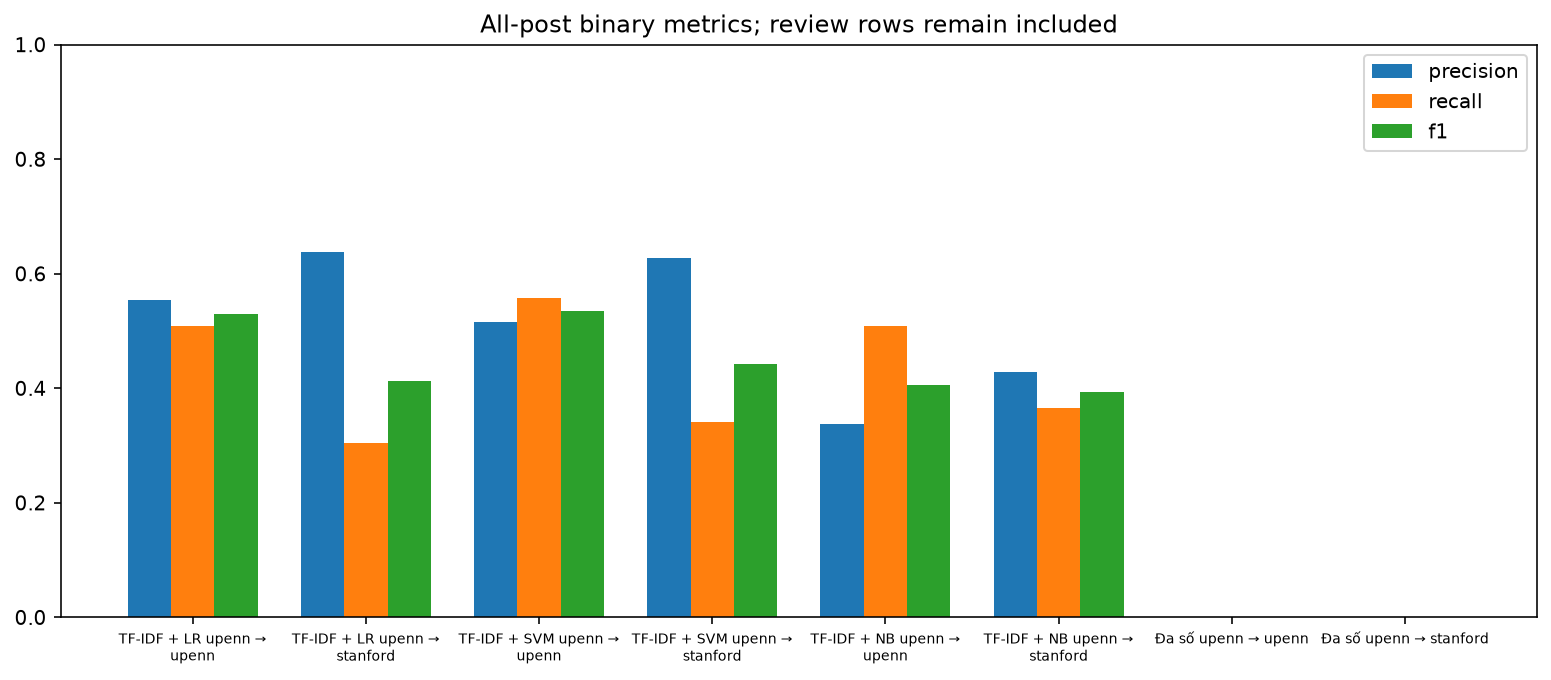

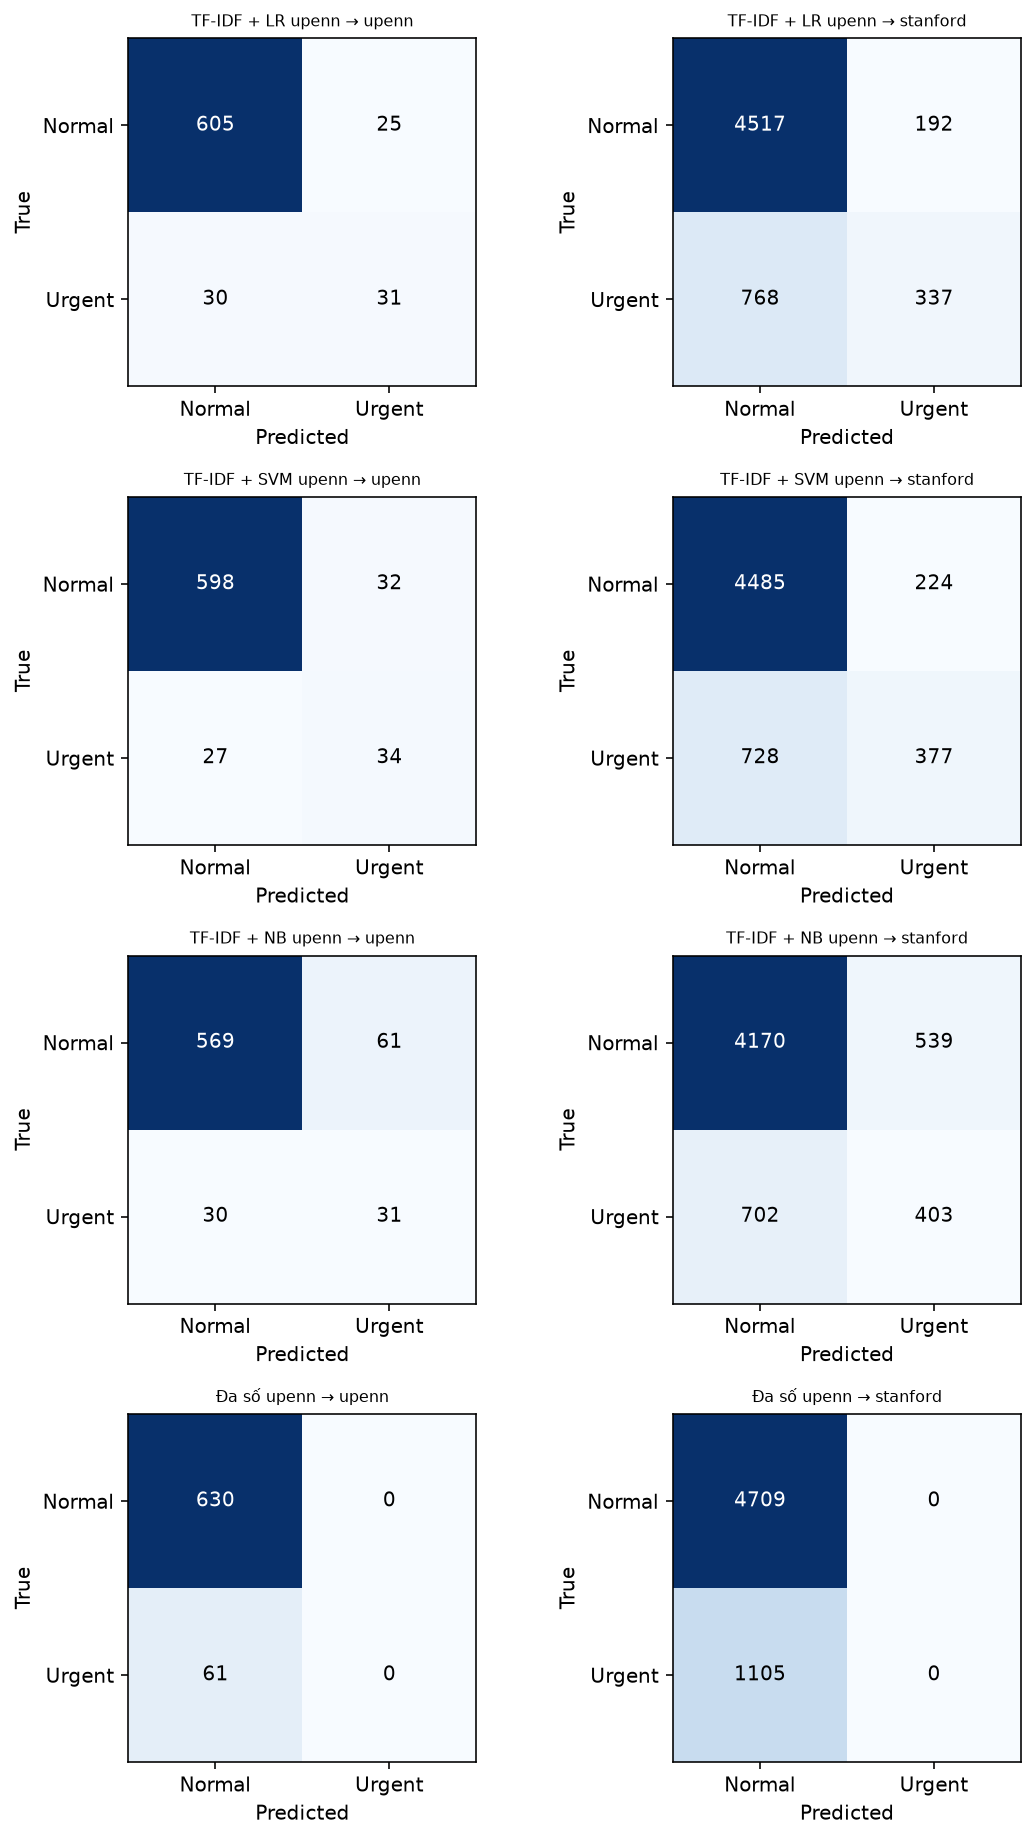

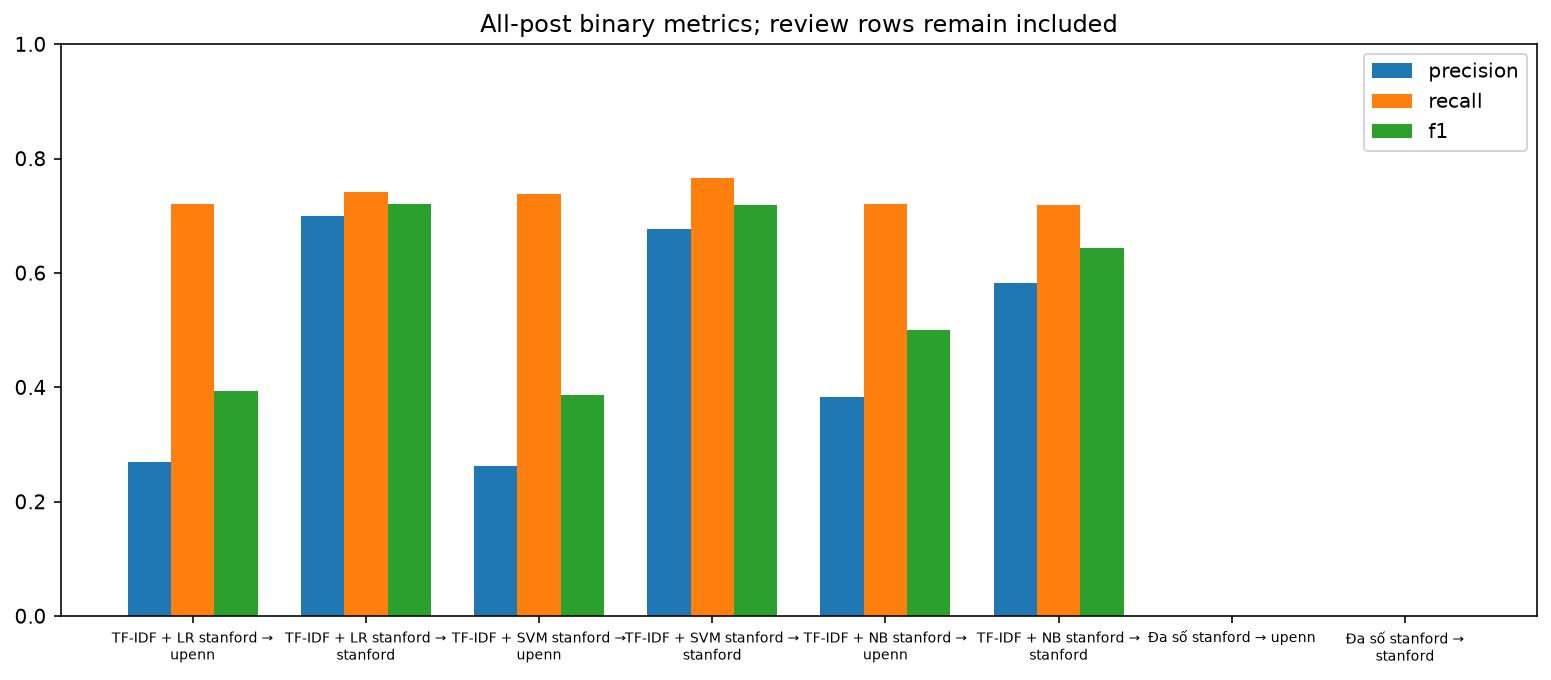

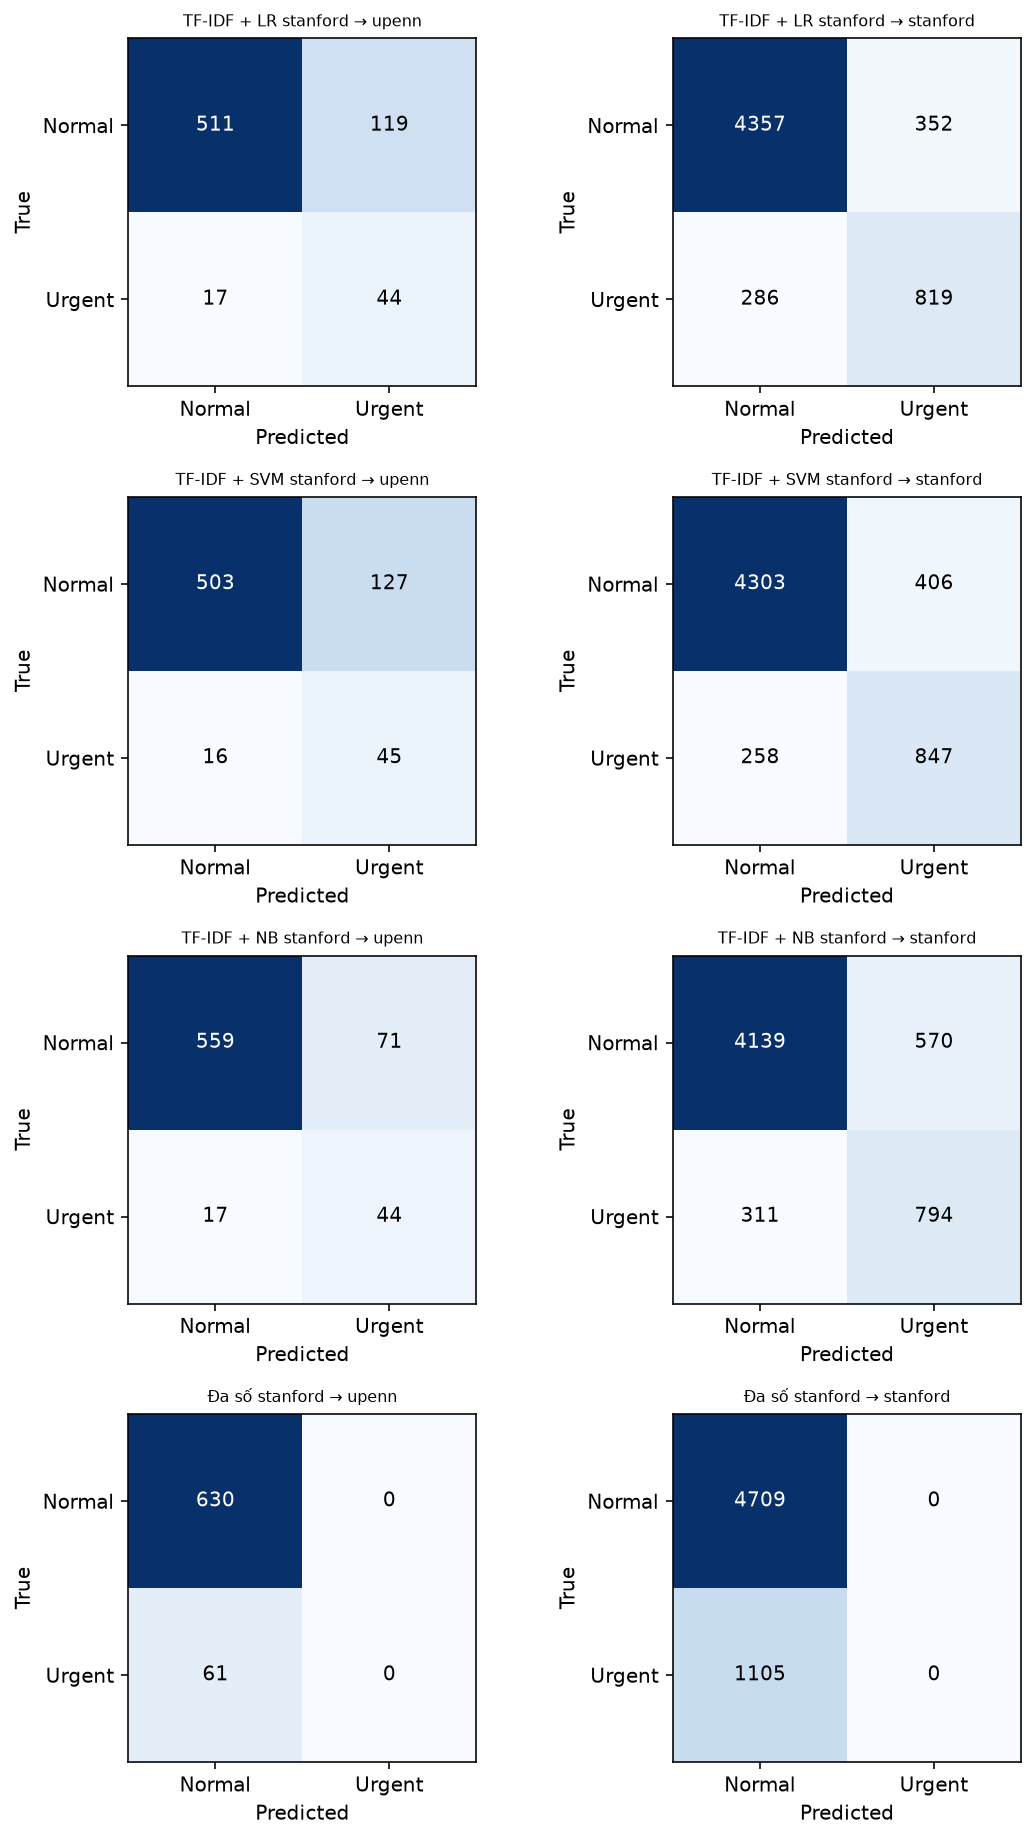

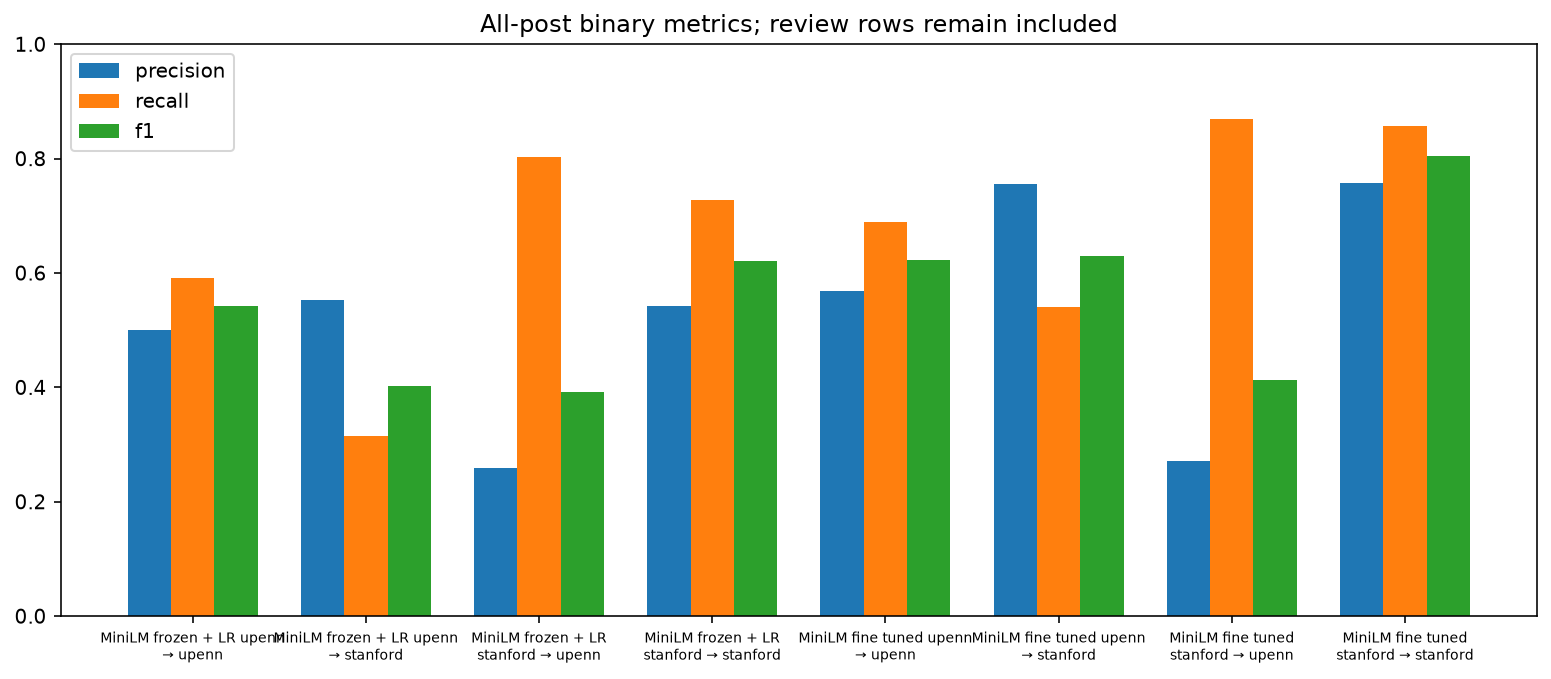

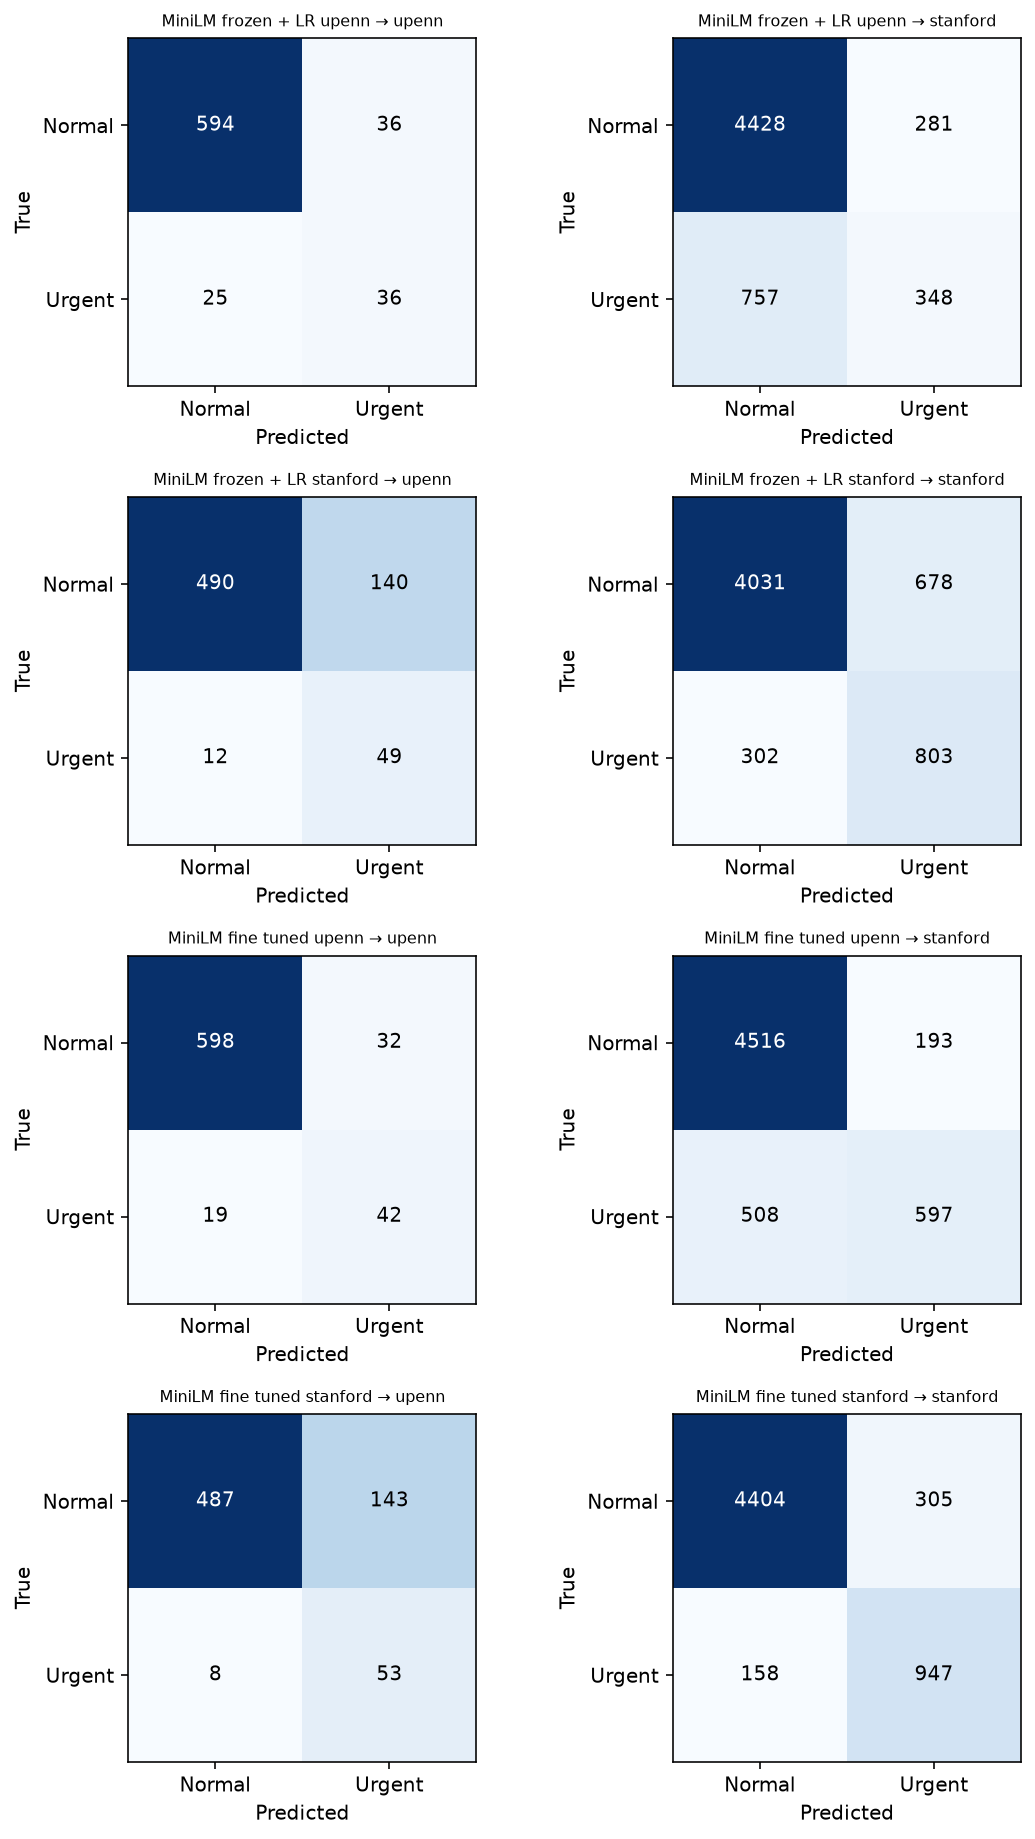

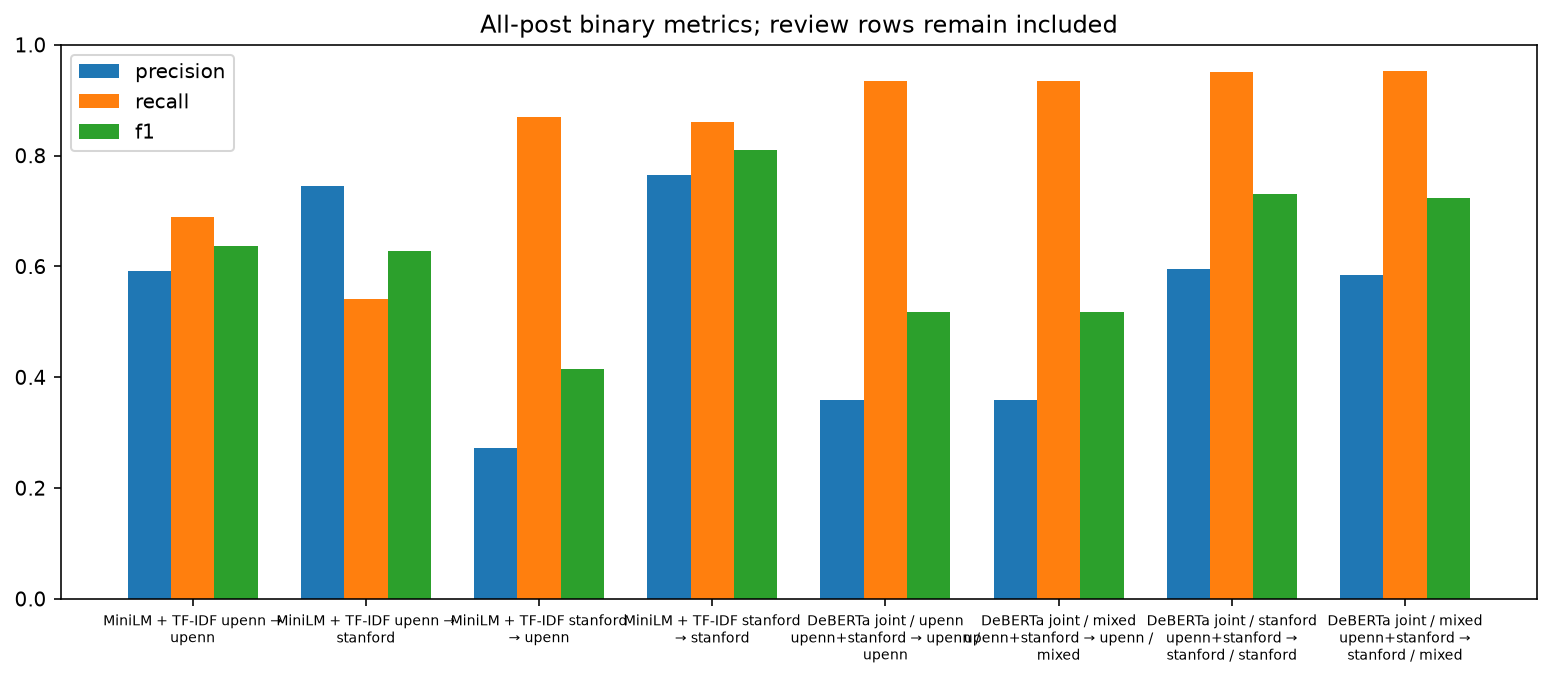

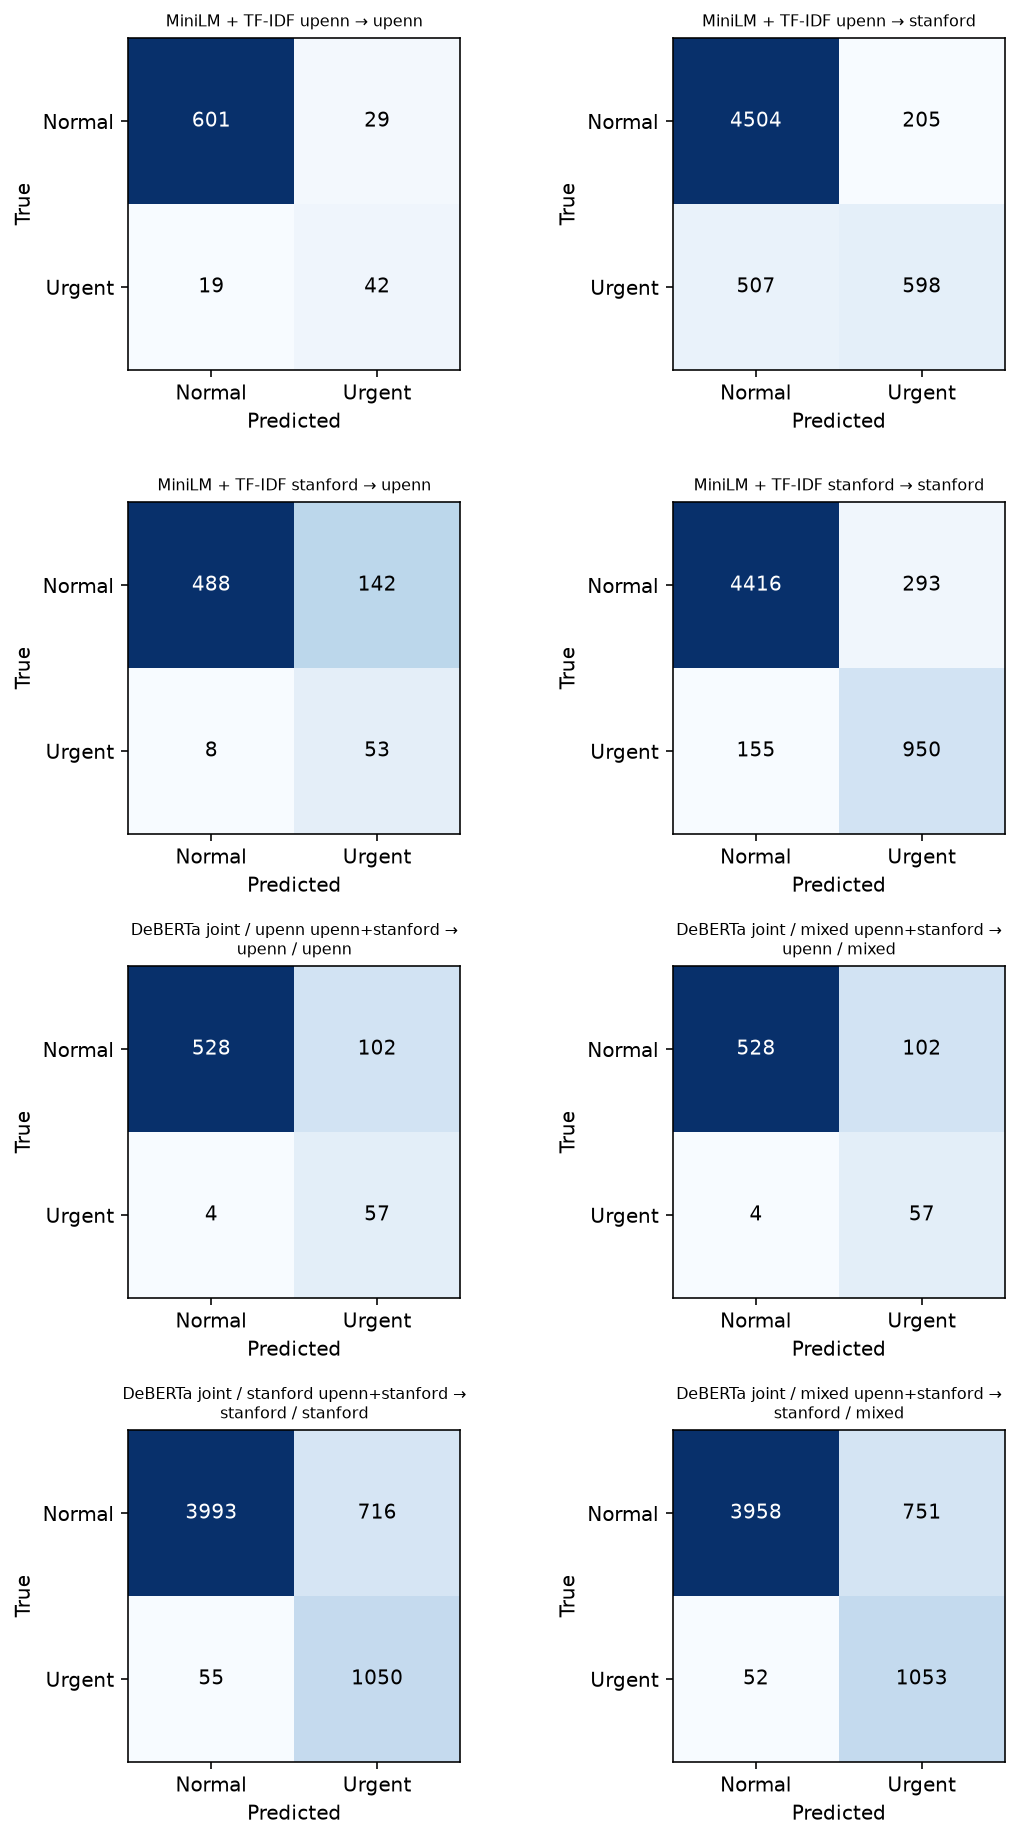

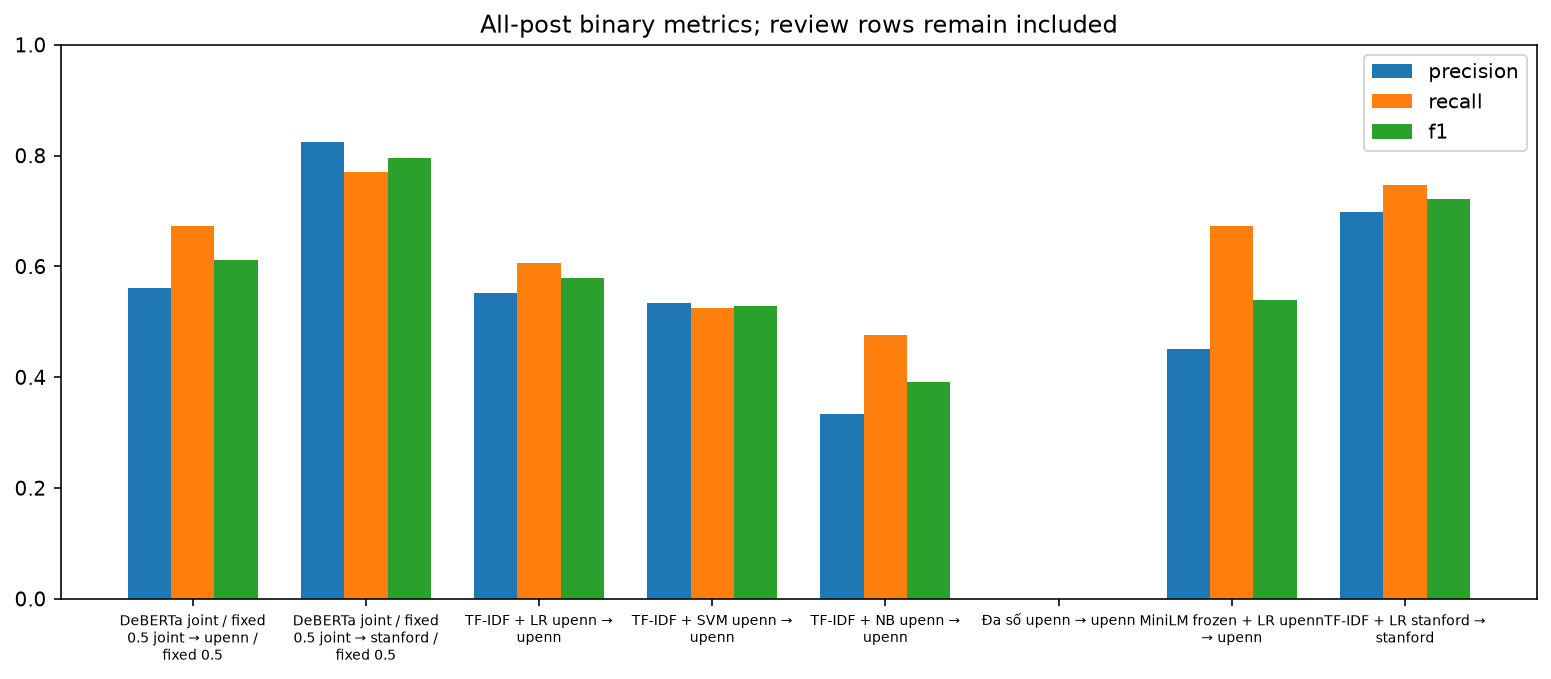

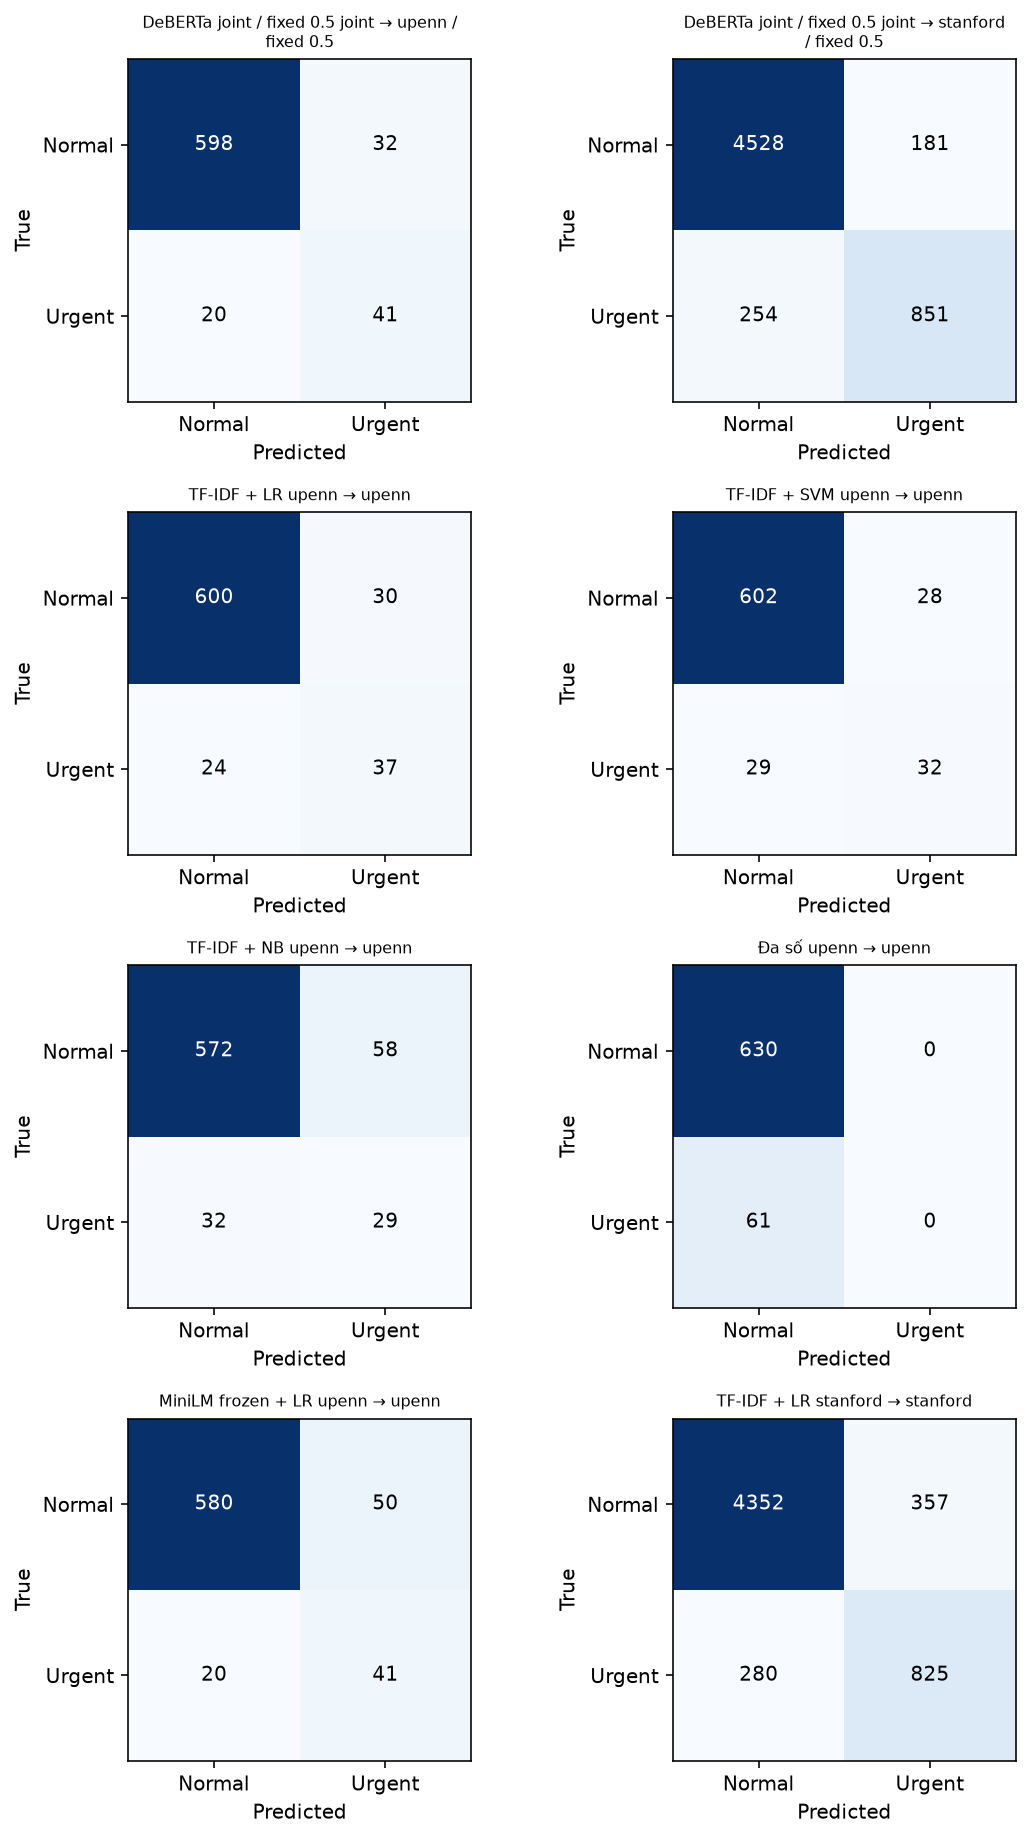

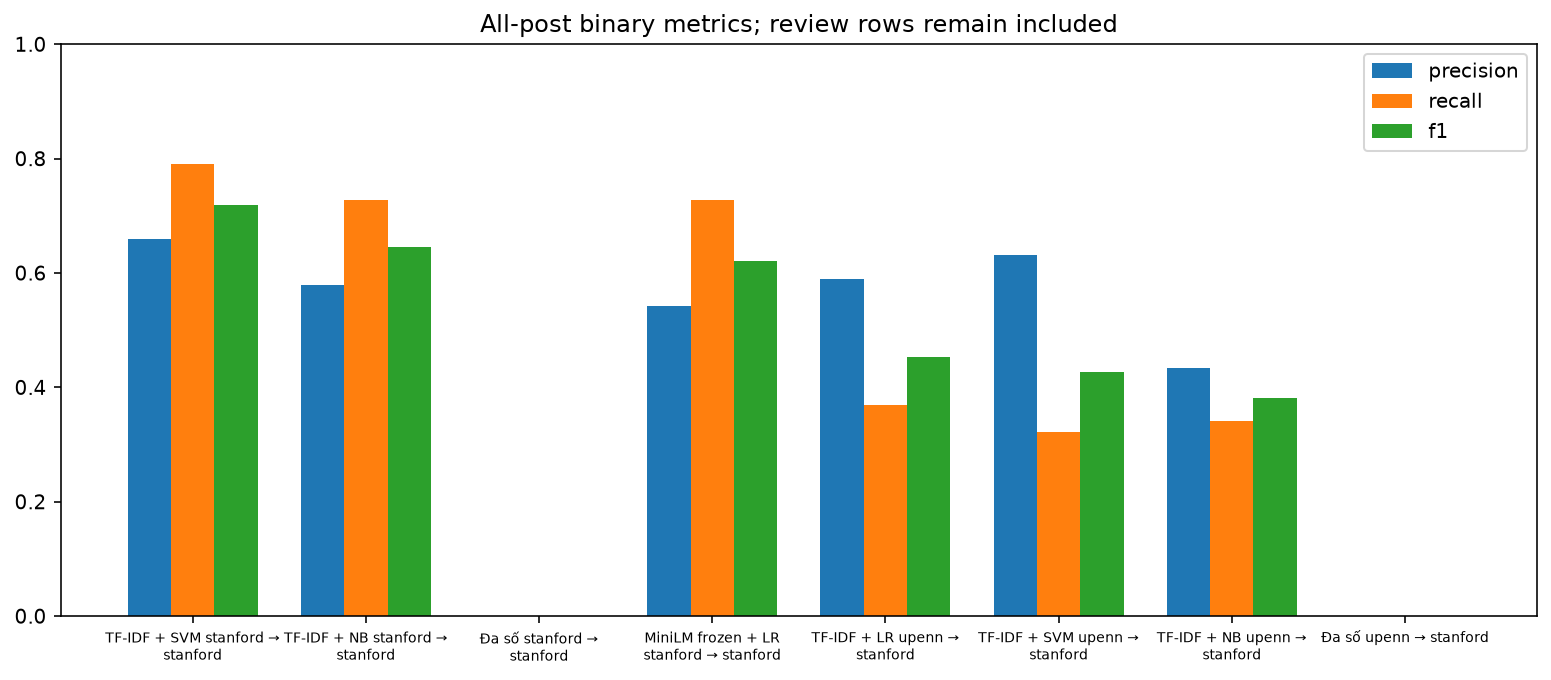

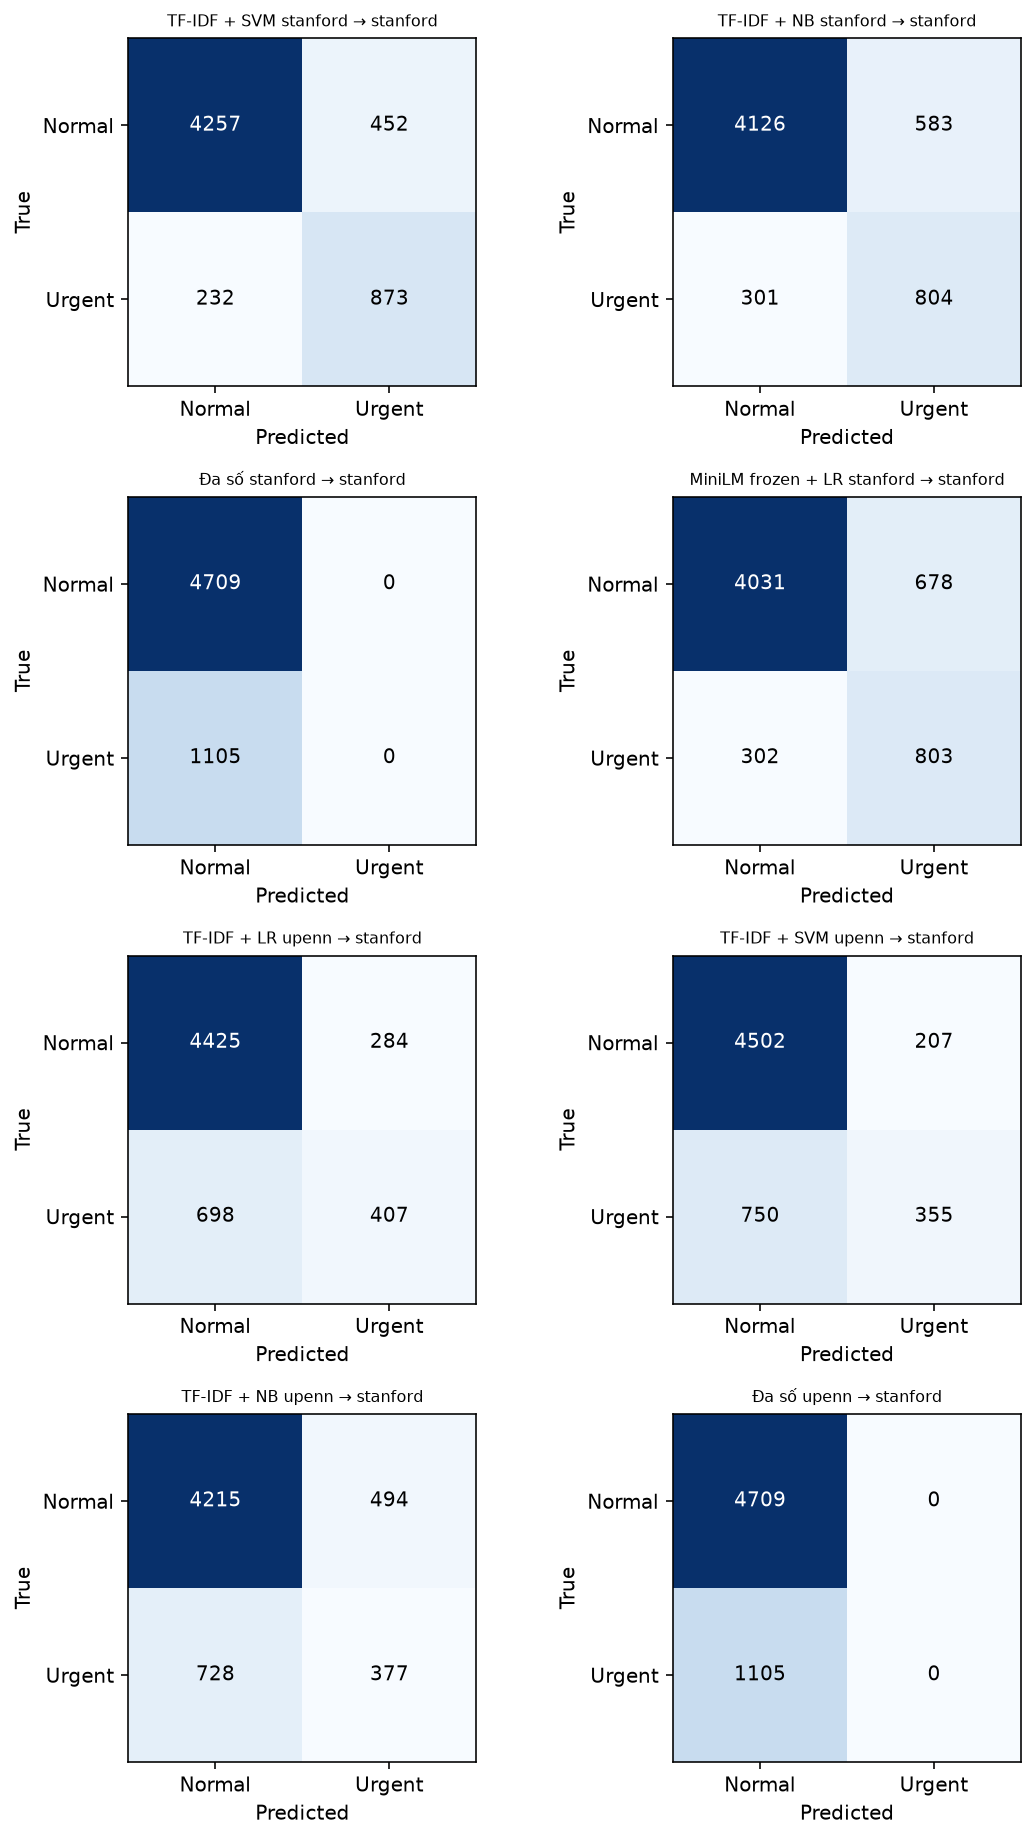

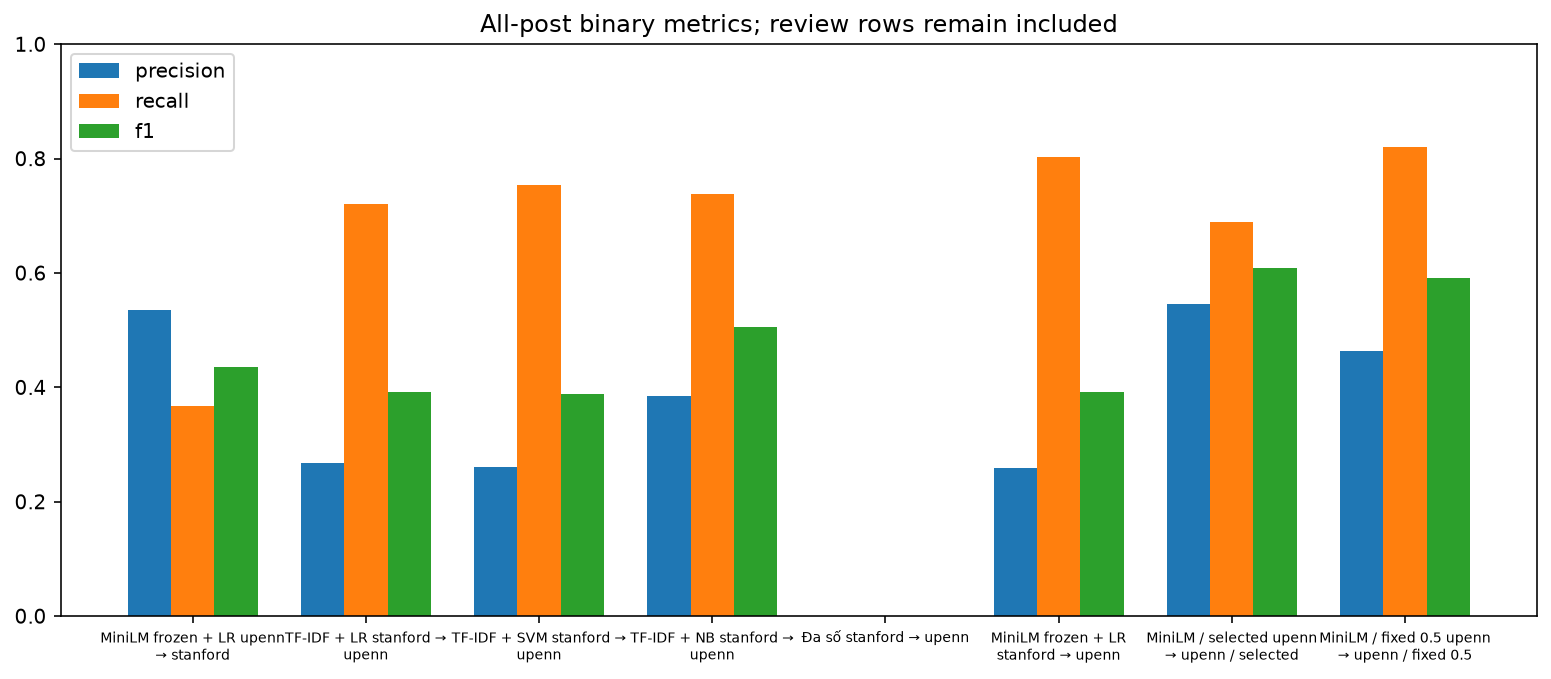

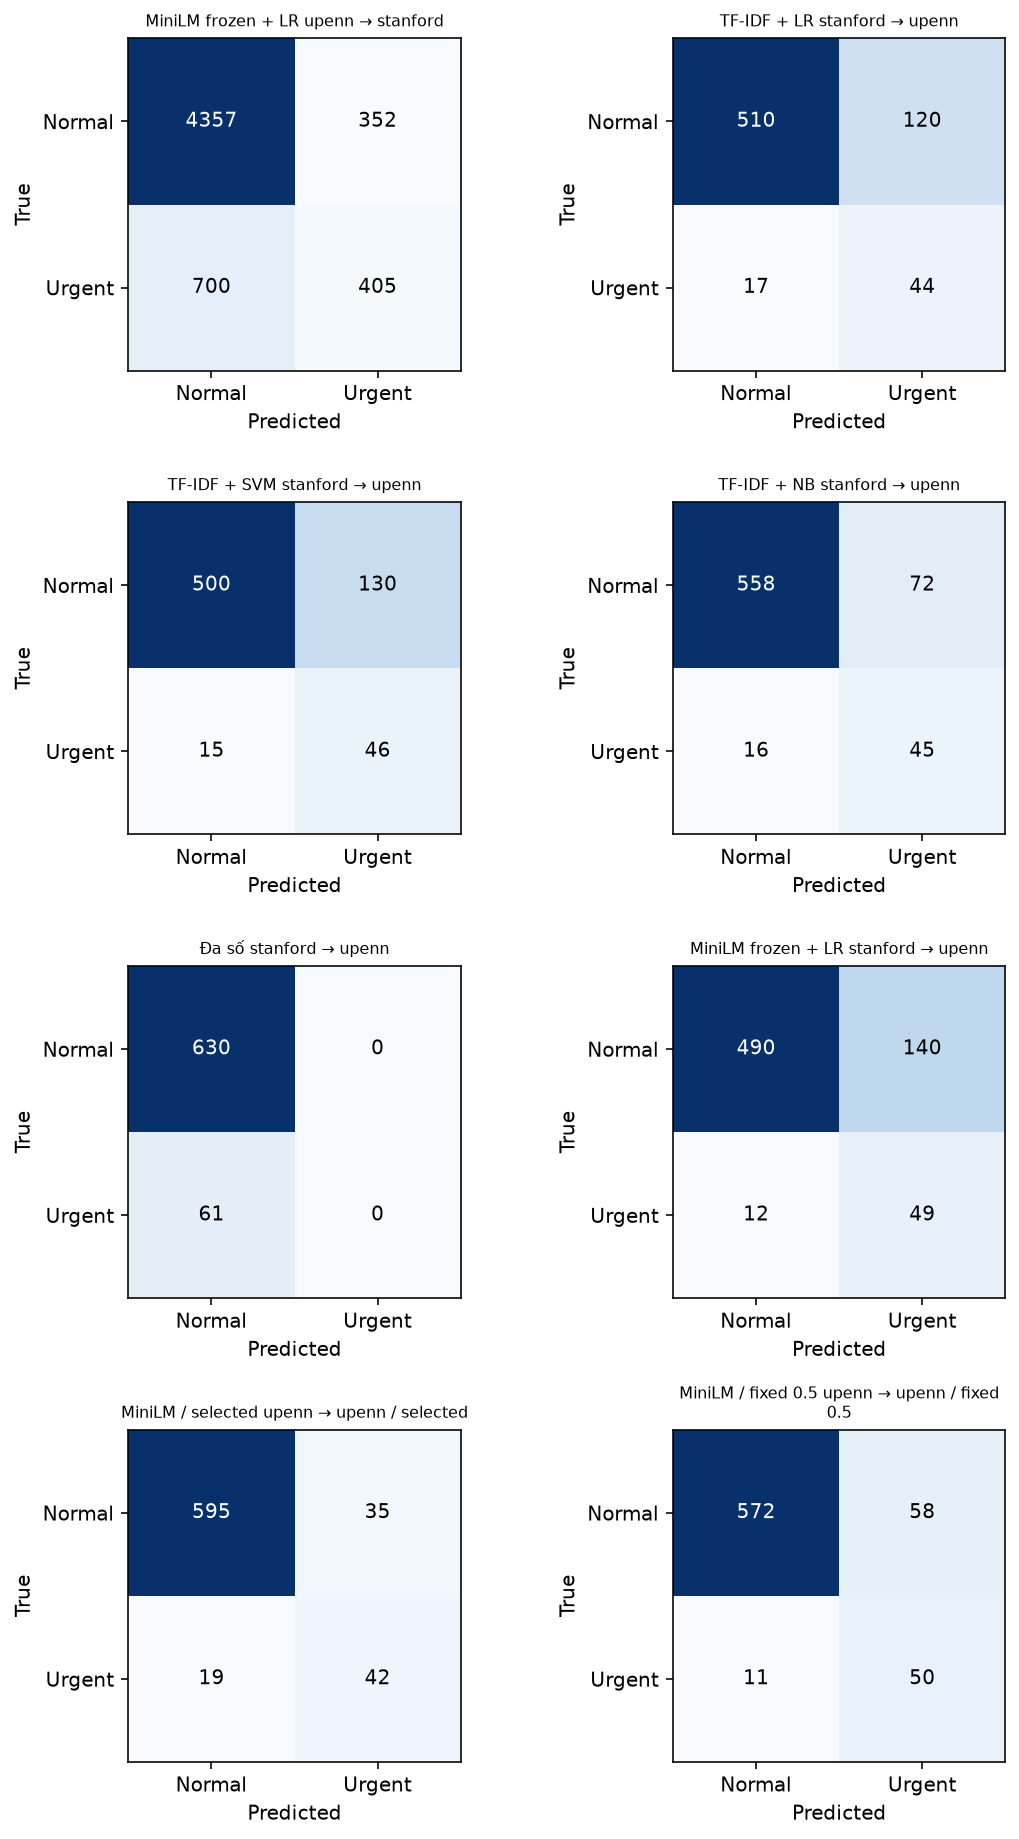

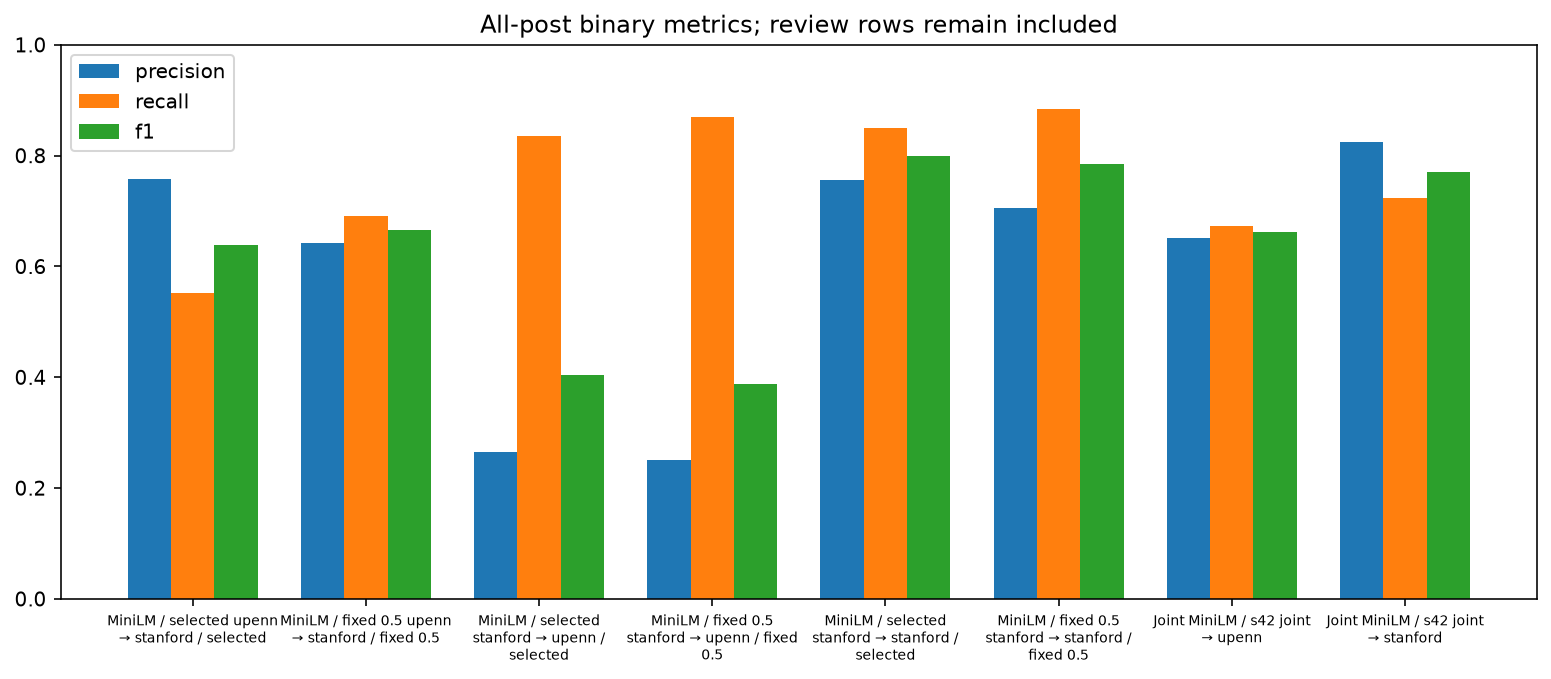

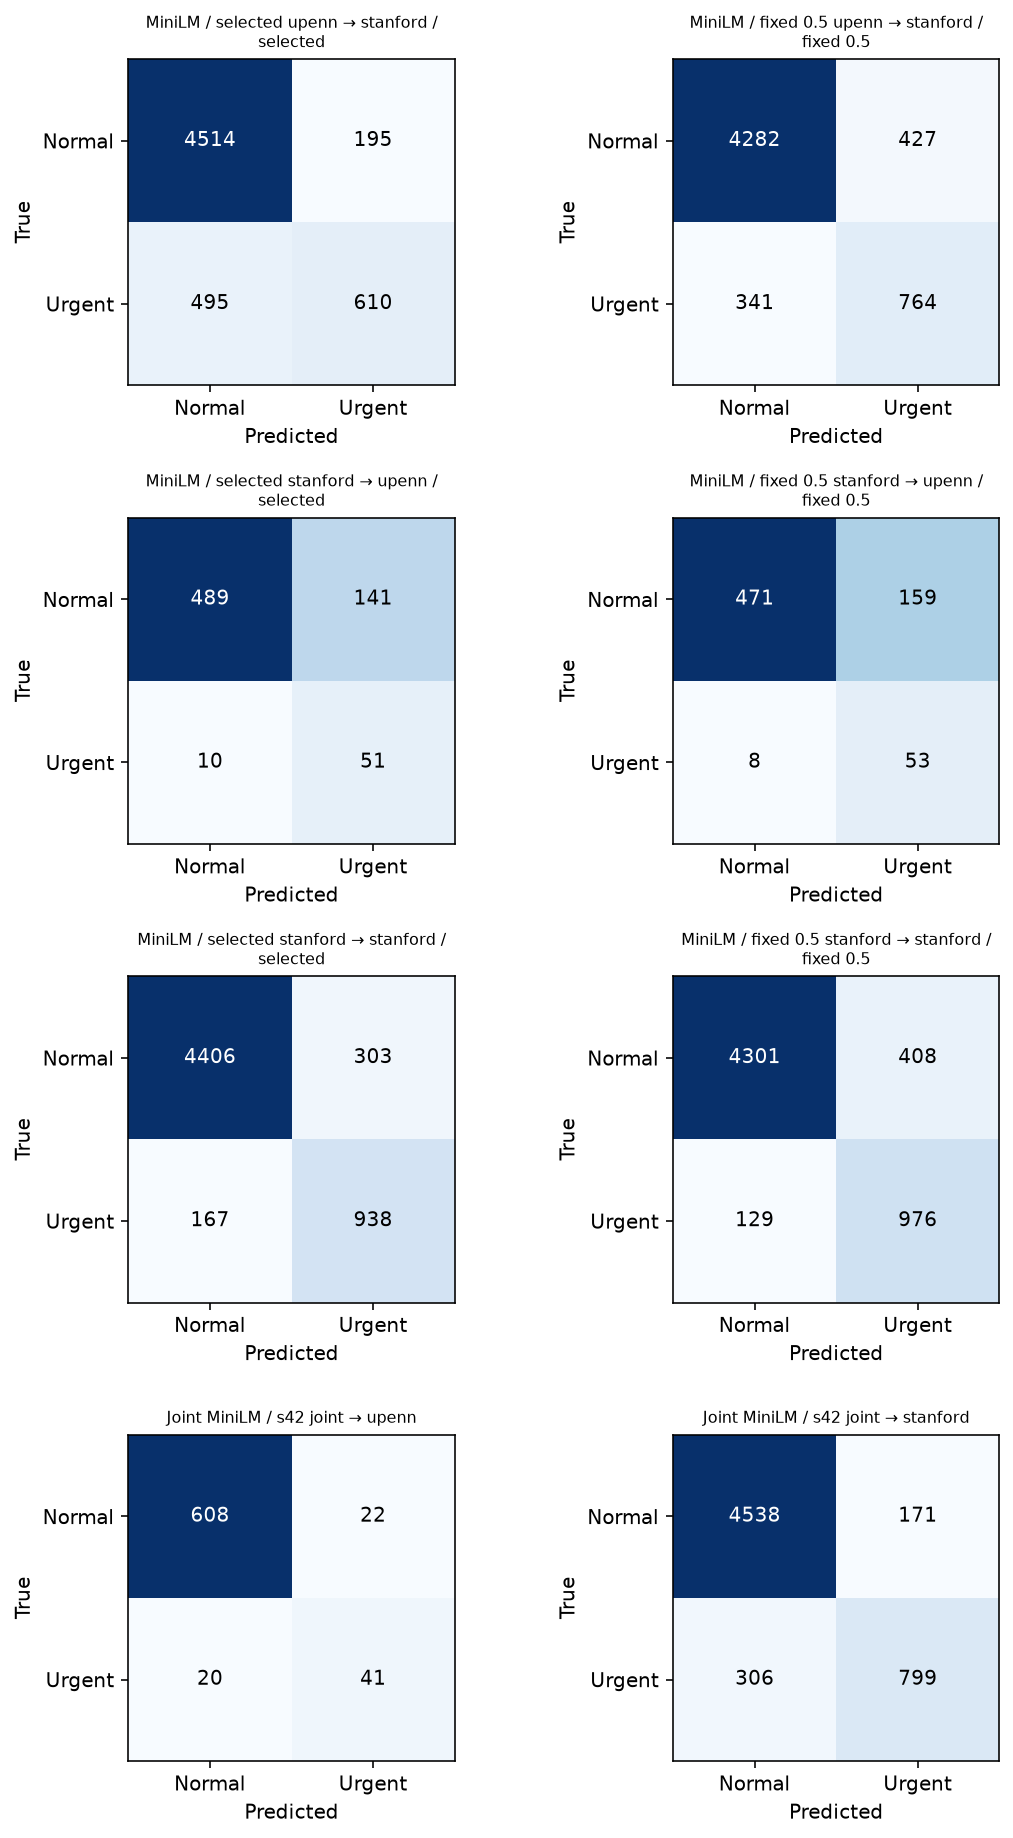

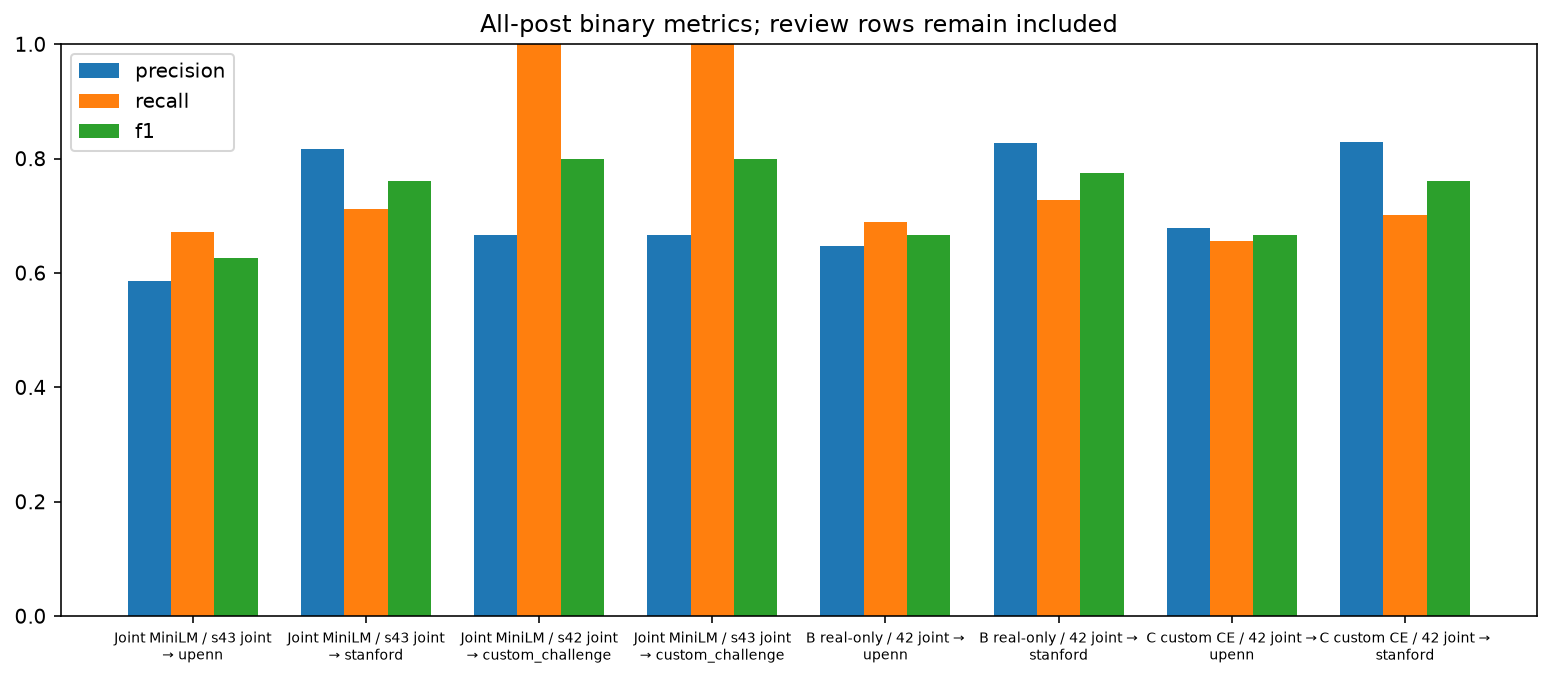

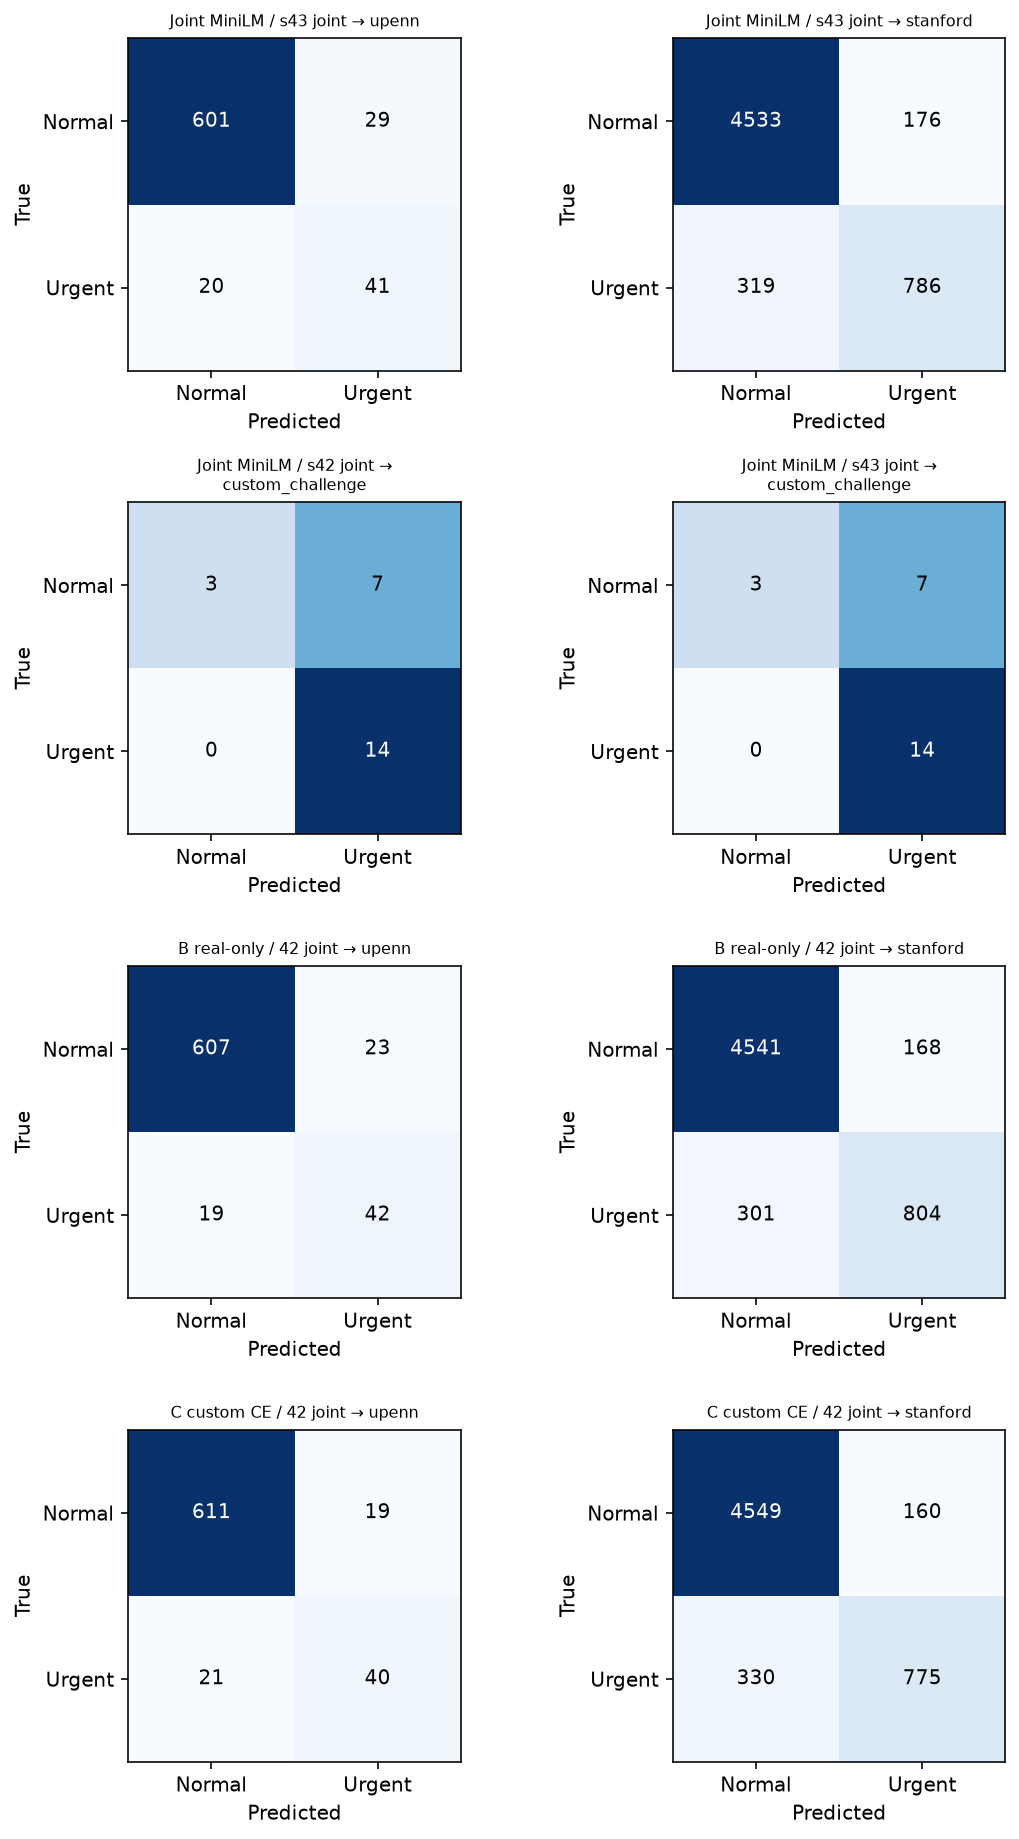

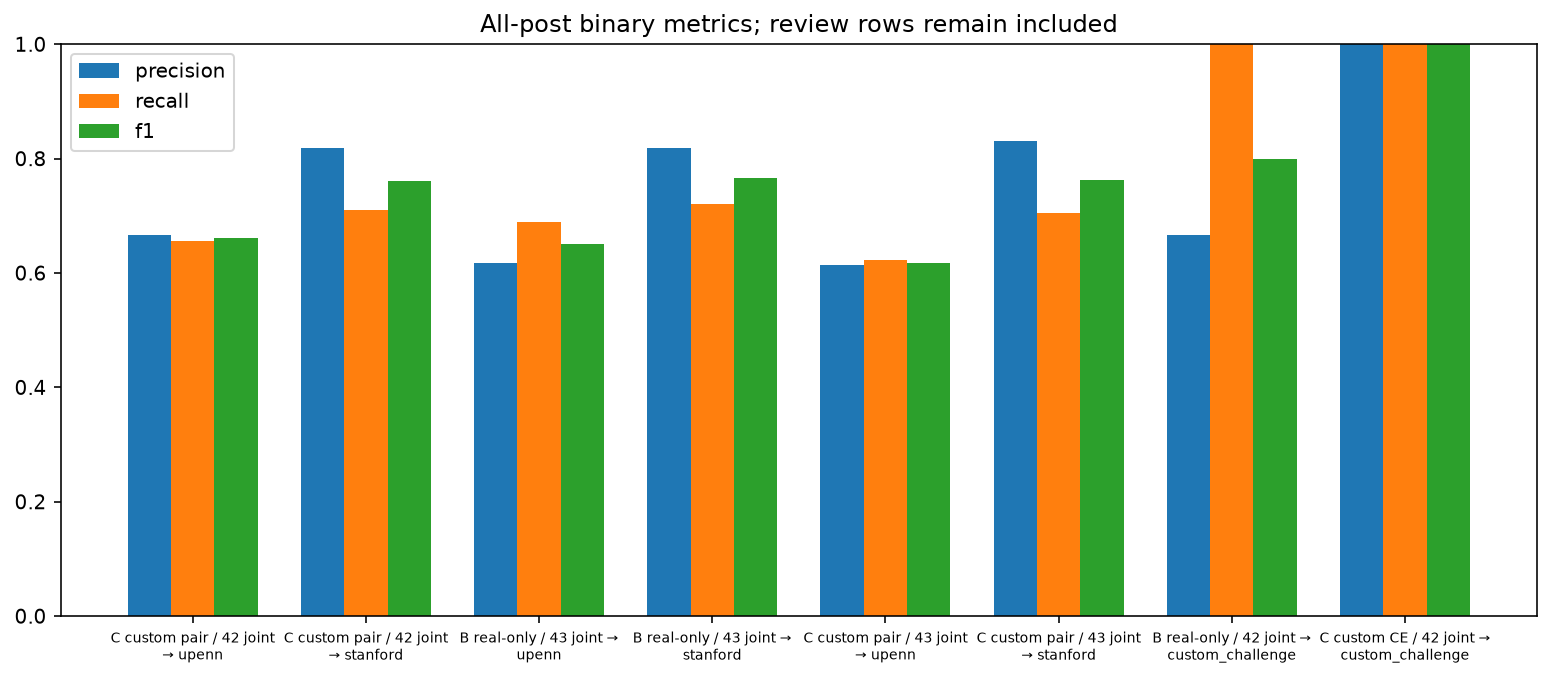

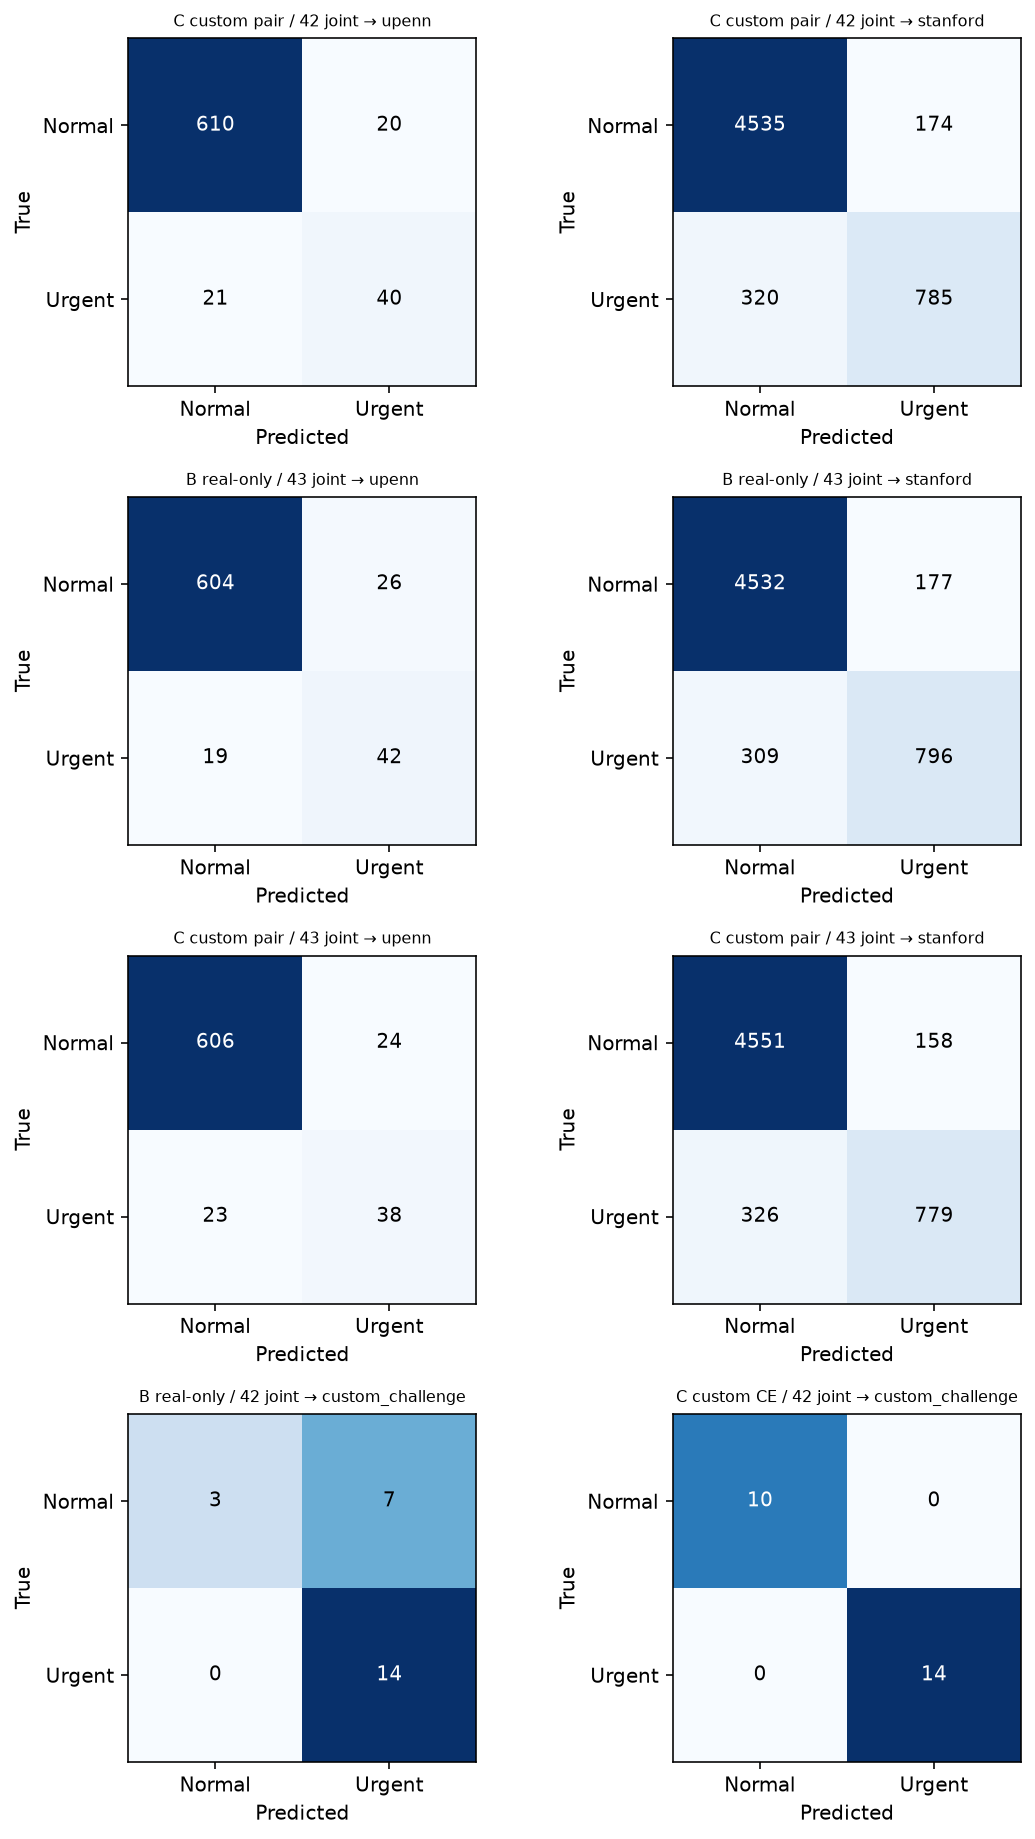

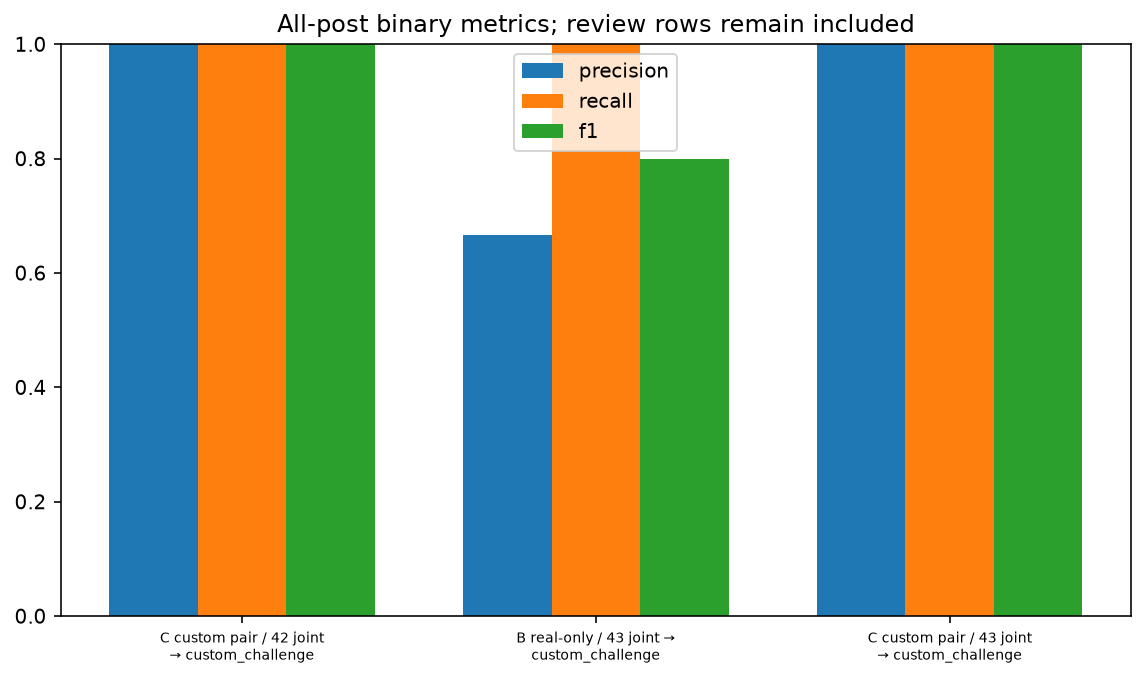

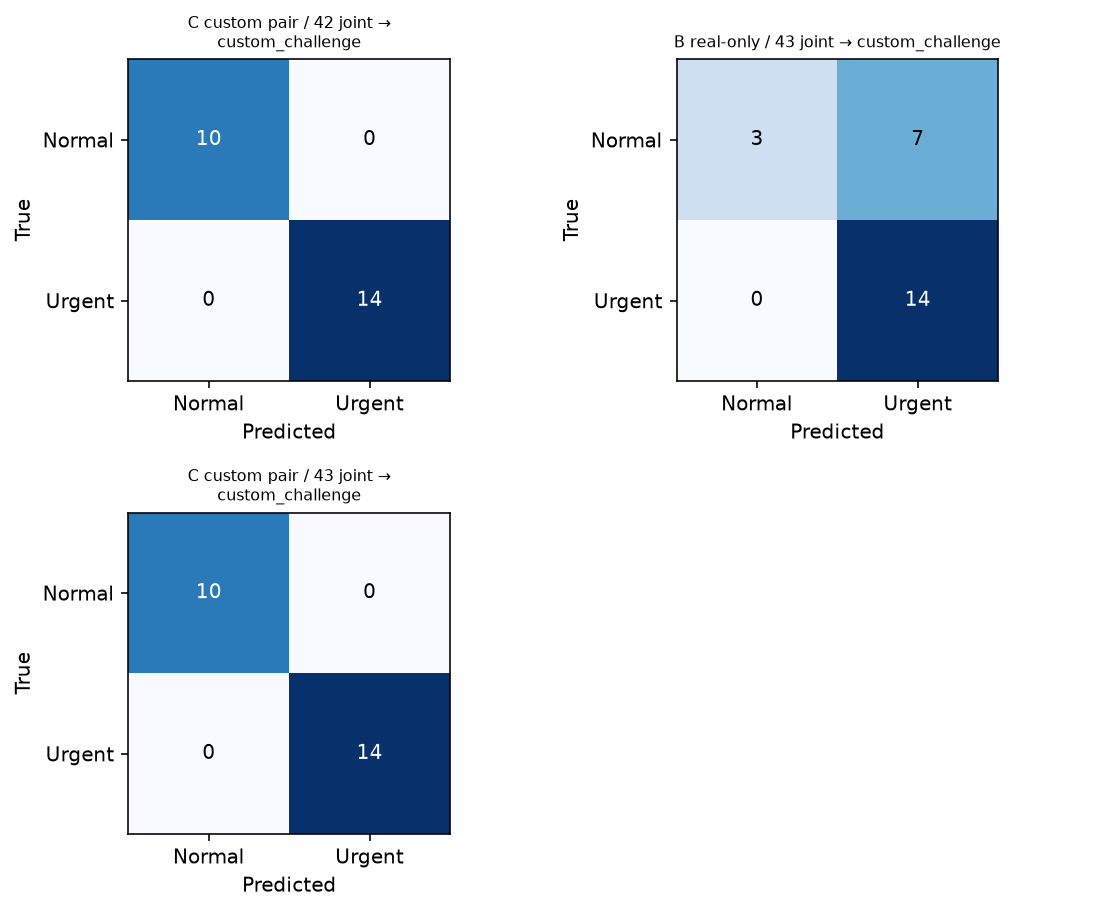

Checks: [
  {
    "experiment": "TF-IDF + LR upenn \u2192 upenn",
    "count_metrics_match": true,
    "per_post_predictions_checked": false
  },
  {
    "experiment": "TF-IDF + LR upenn \u2192 stanford",
    "count_metrics_match": true,
    "per_post_predictions_checked": false
  },
  {
    "experiment": "TF-IDF + SVM upenn \u2192 upenn",
    "count_metrics_match": true,
    "per_post_predictions_checked": false
  },
  {
    "experiment": "TF-IDF + SVM upenn \u2192 stanford",
    "count_metrics_match": true,
    "per_post_predictions_checked": false
  },
  {
    "experiment": "TF-IDF + NB upenn \u2192 upenn",
    "count_metrics_match": true,
    "per_post_predictions_checked": false
  },
  {
    "experiment": "TF-IDF + NB upenn \u2192 stanford",
    "count_metrics_match": true,
    "per_post_predictions_checked": false
  },
  {
    "experiment": "\u0110a s\u1ed1 upenn \u2192 upenn",
    "count_metrics_match": true,
    "per_post_predictions_checked": false
  },
  {
    "experiment": "

In [7]:
run('teacher_notebook_tools.py','emit','--profile',PROFILE,'--models',*MODEL_KEYS)
rows=read_json('reports/teacher/results.json')
if rows:
    headers=['Method/run','Train → test','Policy','P','R','F1','Accuracy','FP','FN']
    table='| '+' | '.join(headers)+' |\n|'+ '|'.join(['---']*len(headers))+'|\n'
    for r in rows:
        table+='| '+' | '.join([str(r.get('run',r.get('trial_label',r.get('model','method')))),str(r.get('train_source','joint'))+' → '+r['test_source'],str(r.get('policy','')),
            *[f"{r[k]:.4f}" for k in ['precision','recall','f1','accuracy']],str(r['confusion_matrix'][0][1]),str(r['confusion_matrix'][1][0])])+' |\n'
    display(Markdown(table))
    for r in rows:print(json.dumps(r,indent=2))
for relative in read_json('reports/teacher/figure_files.json'):display(Image(filename=str(PROJECT/relative)))
print('Checks:',json.dumps(read_json('reports/teacher/checks.json'),indent=2))
print('Actual error examples:',json.dumps(read_json('reports/teacher/error_examples.json'),indent=2))


## Download the complete experiment output

The ZIP includes source code, dataset provenance/splits, statistics, figures, predictions, and trained model folders when training occurred. Caches and temporary checkpoints are excluded. Explicit local validation omits linked model weights from its QA ZIP; a fresh Kaggle training run includes its actual trained weights. Download the displayed ZIP from Kaggle Output. This notebook does not launch the local web application.


In [8]:
from zipfile import ZipFile,ZIP_DEFLATED
archive=PROJECT/(SLUG+'_output.zip')
with ZipFile(archive,'w',ZIP_DEFLATED) as z:
    for directory in ['scripts','Datasets','reports','models']:
        for path in (PROJECT/directory).rglob('*'):
            if not path.is_file() or path.name=='best_state.pt':continue
            if VALIDATION_REUSE and path.suffix in ['.safetensors','.bin','.pt']:continue
            z.write(path,str(path.relative_to(PROJECT)))
print('Download from Kaggle Output:',archive,'MB:',round(archive.stat().st_size/1e6,1))


Download from Kaggle Output: /Users/nhaterik/lastyear/machine/Project/.cache/teacher-notebooks-validation/10_archived_logs_and_interrupted_attempt/10_archived_logs_and_interrupted_attempt_output.zip MB: 1.7
